<a href="https://colab.research.google.com/github/ju4n1t0x/repitencia_educacional/blob/main/TRABAJO_APREN_AUTOMATICO_completo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏫 Infraestructura escolar y repitencia: predicción de la tasa de repitencia 2025 a partir de datos 2024

**Aprendizaje Automático · UGR · Grupo 11**
Integrantes: Sasia, Juan Ignacio · Segovia, Jorge Nicolás · Martos, Stefania · Muñoz Franchi, Juan José

## 📌 Contexto y definición del problema
En el sistema educativo argentino hay diferencias marcadas en la infraestructura, los servicios básicos y el equipamiento tecnológico de las escuelas. Esas diferencias son parte del entorno en el que aprenden los alumnos, y por eso nos preguntamos si tienen relación con la repitencia.

**El desafío:**
Hoy no es fácil saber, de forma objetiva, qué condiciones acompañan a una tasa de repitencia más alta. Con este trabajo buscamos ver si la infraestructura de los establecimientos tiene una asociacion con la tasa de repitencia y, junto con los antecedentes de matrícula y trayectoria escolar, tartar de predecir la tasa de repitencia del año 2025.

La pregunta que guía todo el trabajo es:

> **¿Las condiciones de infraestructura, matrícula y trayectoria escolar observadas en 2024 permiten, poseen una asosiacion tal que nos permita predecir la tasa de repitencia de 2025?**

---

## 🎯 Objetivos del proyecto

* **Objetivo general:** identificar si las caracteristicas de los establecimientos educativos poseen asociacion con el desempeño de los alumnos de modo tal que nos permita predecir la tasa de repitencia 2025 de cada grupo `provincia × departamento × sector × ámbito` con un modelo de **aprendizaje supervisado** (regresión lineal con regularización Ridge), usando como predictores las variables de infraestructura, conectividad, matrícula y trayectoria de 2024.
* **Objetivos específicos:**
  1. Integrar y limpiar las tres bases del Relevamiento Anual 2024 (Características, Matrícula y Trayectoria) usando la clave común `provincia × departamento × sector × ámbito`.
  2. Construir coberturas e índices de infraestructura, conectividad y equipamiento que se puedan comparar entre grupos de distinto tamaño.
  3. Hacer un análisis exploratorio (EDA) que describa la infraestructura, la repitencia y la trayectoria de los grupos, y que muestre si existe relación entre infraestructura y repitencia.
  4. Calcular la repitencia, la sobreedad y los salidos sin pase de 2024 respetando la estructura educativa (6-6 o 7-5) de cada provincia, y validar el cálculo contra las cifras oficiales.
  5. *(Próxima etapa)* Entrenar y evaluar el modelo con la tasa de repitencia 2025, calculada a partir de la Matrícula 2025, como variable objetivo, y medir cuánto aporta la infraestructura a la predicción.

---

## 📂 Repositorio del proyecto
Todo el desarrollo, los datasets crudos y el dataset limpio están en el repositorio de GitHub:
👉 **[repitencia_educacional](https://github.com/ju4n1t0x/repitencia_educacional)**

---

## 📊 Fuentes de datos
Las bases son del Relevamiento Anual que publica el Ministerio de Capital Humano en su portal de datos abiertos, y están subidas al repositorio en la carpeta `/datasets_crudos/`:

* **[`2024 Caracteristicas - agregada.xlsx`](https://github.com/ju4n1t0x/repitencia_educacional/blob/main/datasets_crudos/2024%20Caracteristicas%20-%20agregada.xlsx)**: infraestructura y equipamiento. Fuentes de energía, conectividad por espacio, equipamiento del establecimiento y de la biblioteca, laboratorio, biblioteca, cooperadora, sistema de gestión y subvención estatal.
* **[`2024 Matricula - agregada.xlsx`](https://github.com/ju4n1t0x/repitencia_educacional/blob/main/datasets_crudos/2024%20Matricula%20-%20agregada.xlsx)**: alumnos por año de estudio, repitentes, alumnos con sobreedad, varones y secciones.
* **[`2024 Trayectoria - agregada.xlsx`](https://github.com/ju4n1t0x/repitencia_educacional/blob/main/datasets_crudos/2024%20Trayectoria%20-%20agregada.xlsx)**: qué pasó con los alumnos durante el ciclo lectivo: entrados, salidos con y sin pase, promovidos, no promovidos y egresados.
* **[`2025 Matricula - agregada.csv`](https://github.com/ju4n1t0x/repitencia_educacional/blob/main/datasets_crudos/2025%20Matricula%20-%20agregada.csv)**: misma estructura que la Matrícula 2024. La usamos **solo** para construir la variable objetivo (repitencia 2025).
* **[`Tasa de Repitencia 2023-2012 según división político-territorial.xlsx`](https://github.com/ju4n1t0x/repitencia_educacional/blob/main/datasets_crudos/Tasa%20de%20Repitencia%202023-2012%20seg%C3%BAn%20divisi%C3%B3n%20pol%C3%ADtico-territorial.xlsx)**: tasa oficial por provincia. De acá sacamos la estructura educativa de cada provincia (6-6 o 7-5), la usamos para validar nuestro cálculo y como contexto provincial.

---

---
# 1. 📌 Introducción

*Punto 1 de la entrega.*

**Dominio de aplicación.** El trabajo se ubica en el análisis de datos educativos. La repitencia es uno de los indicadores de eficiencia interna del sistema: muestra qué proporción de los alumnos vuelve a cursar el mismo año. Suele venir acompañada de sobreedad y muchas veces es un paso previo al abandono.

Los datos no vienen por escuela sino agregados: cada fila es un grupo `provincia × departamento × sector × ámbito` que reúne entre 1 y 696 establecimientos. Por eso todo el análisis, y también la predicción, se hace a ese nivel y no por institución.

**Objetivo del modelo.** Queremos un modelo de regresión que, con lo que sabemos de un grupo en 2024 (su infraestructura, su matrícula, su repitencia y sobreedad, sus salidos sin pase, el sector y el ámbito), intente predecir la tasa de repitencia que va a tener en 2025. La repitencia 2025 se usa únicamente como variable objetivo, nunca como predictor.

**Qué vamos a evaluar.** Además de qué tan bien predice, nos interesa saber si la infraestructura aporta algo por encima de los antecedentes educativos. Para eso vamos a entrenar el mismo modelo con y sin el bloque de variables de infraestructura: si el error en provincias que el modelo no vio baja al agregar la infraestructura, hay un patrón de relación entre infraestructura y repitencia que vale la pena mirar.

**Beneficios esperados.** Si el modelo logra anticipar la repitencia con un año de margen, los ministerios provinciales y las propias instituciones podrían identificar antes los departamentos con más riesgo y orientar recursos (tutorías, apoyo escolar, mejoras edilicias o de conectividad) hacia donde más se necesitan, en lugar de reaccionar cuando la repitencia ya ocurrió.

Además, ver cuánto pesa la infraestructura en la predicción da una primera pista sobre dónde puede convenir invertir (conectividad, laboratorios, equipamiento). Una asociación no alcanza para decir que la infraestructura cause la repitencia, pero sí ayuda a priorizar qué mirar con más detalle.

---
# 2. 📊 Fuentes y conjuntos de datos


## 2.1 Las bases utilizadas

Las tres bases principales salen del mismo **Relevamiento Anual 2024** del Ministerio de Capital Humano, publicado en el
[Buscador de bases usuarias](https://www.argentina.gob.ar/educacion/evaluacion-e-informacion-educativa/datos-abiertos-de-la-secretaria-de-educacion).
Como vienen del mismo relevamiento comparten la misma clave, y eso es lo que nos permite integrarlas.

| Base | Qué aporta | Filas × columnas | Rol en el trabajo |
|---|---|---|---|
| `2024 Caracteristicas - agregada.xlsx` | infraestructura, equipamiento, conectividad | 1216 × 66 | predictores 2024 |
| `2024 Matricula - agregada.xlsx` | matrícula, repitentes, sobreedad por año de estudio | 1216 × 104 | predictores 2024 (repitencia y sobreedad previas) |
| `2024 Trayectoria - agregada.xlsx` | salidos sin pase, promovidos, no promovidos, egresados | 1209 × 288 | predictores 2024 (salidos sin pase) |
| `2025 Matricula - agregada.csv` | matrícula y repitentes 2025 | 1217 × 103 | variable objetivo (repitencia 2025) |

**Clave de integración:** `provincia × departamento × sector × ámbito`

> Además usamos el archivo oficial `Tasa de Repitencia 2023-2012 según división político-territorial.xlsx`
> para tomar la estructura educativa (6-6 o 7-5) de cada provincia, para validar nuestro cálculo de
> repitencia contra la cifra publicada (sección 5.7) y como variable de contexto provincial.

## 2.2 Diccionario de variables (en crudo)

A continuación detallamos qué significa cada campo de las tres bases del Relevamiento Anual 2024. La Matrícula 2025 tiene las mismas columnas que la de 2024 (salvo `Localizacion`), así que su diccionario vale para los dos años.

### **Características e Infraestructura**

#### Ubicación y contexto institucional
* **`provincia`**: Provincia o jurisdicción del grupo.
* **`departamento`**: Departamento o partido dentro de la provincia. Cuando hay muy pocas escuelas aparece como `Enmascarado` (secreto estadístico).
* **`sector`**: Gestión de los establecimientos (*Estatal* / *Privado*).
* **`ambito`**: Entorno geográfico (*Urbano* / *Rural*).
* **`Localizacion`**: Cantidad de establecimientos que componen el grupo. Va de 1 a 696 y suma 50.591 en todo el país.



#### Provisión de energía eléctrica
* **`ElectricidadSi`**: Establecimientos con acceso a electricidad.
* **`ElectricidadRedpública`**: Conexión a la red pública de distribución eléctrica.
* **`ElectricidadGrupoelectrógeno`**: Disponibilidad de grupo electrógeno.
* **`ElectricidadPanelfotovoltaicosolar`**: Provisión mediante paneles solares.
* **`ElectricidadGeneradoreólico`**: Provisión mediante generadores eólicos.
* **`ElectricidadGeneradorhidráulico`**: Provisión mediante generadores hidráulicos.
* **`ElectricidadOtro`**: Otras fuentes de energía eléctrica.



#### Equipamiento tecnológico del establecimiento
*(En la base 2024 estas columnas cuentan establecimientos que tienen al menos un aparato de ese tipo, no la cantidad de aparatos: divididas por `Localizacion` nunca superan 1. Lo verificamos en la sección 5.3.)*
* **`EquipamientoEstablecimientoTelevisor`**: Establecimientos con televisor.
* **`EquipamientoEstablecimientoSistemamultimediaoCañón`**: Con proyector o cañón multimedia.
* **`EquipamientoEstablecimientoScanner`**: Con escáner.
* **`EquipamientoEstablecimientoWebcam`**: Con cámara web.
* **`EquipamientoEstablecimientoReproductordeCD`**, **`EquipamientoEstablecimientoReproductordeDVD`**: Con reproductor de CD o de DVD.
* **`EquipamientoEstablecimientoImpresora`**: Con impresora.
* **`EquipamientoEstablecimientoEquipoemisorderadioAMFM`**: Con transmisor de radio AM/FM propio.
* **`EquipamientoEstablecimientoEquiporeceptorderadioAMFM`**: Con receptor de radio AM/FM. *(100 % vacía: se descarta.)*
* **`EquipamientoEstablecimientoServidorparausoescolar`**: Con servidor para uso escolar.
* **`EquipamientoEstablecimientoImpresora3D`**: Con impresora 3D.
* **`EquipamientoEstablecimientoEquipodeSonido`**: Con equipo de sonido.
* **`EquipamientoEstablecimientoPizarrasdigitales`**: Con pizarra digital.



#### Equipamiento en la biblioteca
*(Equipamiento ubicado dentro de la biblioteca. Mismo criterio que el bloque anterior: cuentan establecimientos cuya biblioteca tiene ese equipamiento. El receptor de radio AM/FM también viene 100 % vacío y se descarta.)*
* **`EquipamientoBibliotecaTelevisor`**, **`EquipamientoBibliotecaSistemamultimediaoCañón`**, **`EquipamientoBibliotecaScanner`**, **`EquipamientoBibliotecaEquipamientoBibliotecaWebcam`**, **`EquipamientoBibliotecaReproductordeCD`**, **`EquipamientoBibliotecaReproductordeDVD`**, **`EquipamientoBibliotecaImpresora`**, **`EquipamientoBibliotecaEquipoemisorderadioAMFM`**, **`EquipamientoBibliotecaEquiporeceptorderadioAMFM`**, **`EquipamientoBibliotecaServidorparausoescolar`**.



#### Conectividad a internet
* **Tipo de servicio:**
  * **`InternetTipodeservicioGratuitoEstado`**: Servicio gratuito provisto por el Estado.
  * **`InternetTipodeservicioGratuitoOtro`**: Otro esquema de gratuidad.
  * **`InternetTipodeservicioPago`**: Servicio pagado por la institución o la cooperadora.
* **Tecnología de conexión:**
  * **`InternetTipodeconexiónTelefónica`**, **`InternetTipodeconexiónADSL`**, **`InternetTipodeconexiónCableMódem`**, **`InternetTipodeconexiónSatelital`**, **`InternetTipodeconexiónMóvil`**, **`InternetTipodeconexiónOtroTipo`**.
* **Espacios con conexión:**
  * **`EspaciosconconexiónEneláreadeadministración`**: Conexión en el área administrativa.
  * **`EspaciosconconexiónEnlasaulas`**: Conexión dentro de las aulas.
  * **`EspaciosconconexiónEnlabibliotecas`**: Conexión en la biblioteca.
  * **`EspaciosconconexiónEnellaboratorio`**: Conexión en el laboratorio o sala de informática.
  * **`EspaciosconconexiónEnotroespaciodelestablecimiento`**: Conexión en otros espacios (patios, espacios comunes).



#### Infraestructura física y gestión institucional
* **Sistemas de gestión escolar:**
  * **`SistemadeGestiónEscolarSi`**: Usa un sistema de gestión escolar.
  * **`SistemadeGestiónEscolarProvistoporelMinisterio`**: Sistema provisto por el Ministerio.
  * **`SistemadeGestiónEscolarDesarrolladoporterceros`**: Sistema de terceros.
  * **`SistemadeGestiónEscolarEncargadoporelEstablecimiento`**: Sistema encargado por la escuela.
  * **`SistemadeGestiónEscolarPlanilladeCalculo`**: Gestión con planillas de cálculo.
* **Espacios especializados:**
  * **`DisponedesalaolaboratoriodeinformáticaSi`**: Tiene sala o laboratorio de informática.
  * **`LaboratorioFuncionaesespacioexclusivoSi`**: El laboratorio funciona en un espacio exclusivo.
  * **`BibliotecaDisponedealmenosunaSi`**: Tiene al menos una biblioteca.
  * **`BibliotecaFuncionaesespacioexclusivoSi`**: La biblioteca funciona en un espacio exclusivo.
* **Cooperadora:**
  * **`CooperadoraConpersoneríajurídica`**: Cooperadora con personería jurídica.
  * **`CooperadoraSinpersoneríajurídica`**: Cooperadora sin personería jurídica.
  * **`CooperadoraNo`**: No tiene cooperadora.
* **Aporte estatal:**
  * **`SubvenciónEstatalJardínMaternalSi`**, **`SubvenciónEstatalJardíndeInfantesSi`**, **`SubvenciónEstatalPrimariaSi`**, **`SubvenciónEstatalSecundariaSi`**, **`SubvenciónEstatalSNUSi`**: Subvención estatal por nivel educativo.


  ---

### **Matrícula**

#### Base de Matrícula
*(Composición de la matrícula por año de estudio. Los nombres son siglas; entre paréntesis, el dato de 2024
con el que verificamos cada significado.)*

* **`_1` … `_12`**: Matrícula por año de estudio, de 1° a 12°. *(suman 8.707.496 alumnos)*
* **`_1314`, `_20`, `_snu`**: Años 13 y 14, matrícula de establecimientos con organización no graduada (`_20`) y Superior No Universitario. *(74.843 / 3.992 / 986.958)*
* **`lactantes`, `deambulantes`, `s2` … `s5`**: Salas del nivel inicial, de lactantes a sala de 5. *(1.576.572 alumnos)*
* **`v_…`**: Varones. *(50,5 % de la matrícula de 1° a 12°)*
* **`r_…`**: Repitentes. *(agregados por provincia reproducen la tasa oficial del Ministerio, r = 1,00; ver 5.7)*
* **`s_…`**: Alumnos con sobreedad. *(20,4 % en secundaria, tomando de 7° a 12°)*
* **`_sec…`**: Secciones, es decir divisiones, no alumnos. *(446.345 secciones)*
* **`multi_ini`, `multi_pri`, `multi_sec`, `multinivel`**: Secciones multigrado y multinivel. *(30.644)*

> El prefijo `s` se usa para dos cosas distintas: `s2`…`s5` son las **salas** del nivel inicial,
> `s_1`…`s_12` es la **sobreedad** por año de estudio, y `s_s2`…`s_s5` es la sobreedad dentro de las salas.

---

### **Trayectoria**

#### Base de Trayectoria
*(Qué pasó con los alumnos a lo largo del ciclo lectivo 2024. Los porcentajes suman de 1° a 12°.)*

* **`inicial_…`**: Matrícula al inicio del ciclo. *(8.760.071 alumnos)*
* **`entrados_…`**: Alumnos que se incorporan durante el ciclo. *(2,6 % de la inicial)*
* **`ssp_…`**: Salidos sin pase: dejan la escuela sin certificado de traslado. *(0,7 %)*
* **`scp_…`**: Salidos con pase: se transfieren a otro establecimiento. *(2,8 %)*
* **`ultimo_…`**: Matrícula al final del ciclo. No es «último año». *(99,1 % de la inicial)*
* **`promovidos_…`**: Promovidos directamente. *(80,1 % de la matrícula final)*
* **`promovidos_ex_…`**: Promovidos rindiendo examen. *(12,7 %)*
* **`nopromo_…`**: No promovidos. *(7,2 %)*
* **`regulares_…`, `otros_…`**: Alumnos regulares y alumnos en otras situaciones. Son categorías menores *(0,8 % y 0,2 % de la matrícula final)* que no forman parte de las identidades de abajo, así que no las usamos.
* **`primaria_egresados`, `secundaria_egresados`**: Egresados del nivel. Columna única, sin año. *(734.854 y 434.404)*
* **`m_…`**: Mujeres. Se antepone a cualquiera de los anteriores. *(49,6 % de la matrícula inicial)*


**Las dos identidades que validan la lectura de esta base:**

```
inicial + entrados − salidos sin pase − salidos con pase = último
promovidos + promovidos_ex + no promovidos = último
```

Las dos se cumplen en el 100 % de las filas, con diferencia de 0 alumnos. La primera confirma que `inicial`
y `ultimo` son los dos extremos del ciclo. La segunda muestra que las tres categorías de promoción son
excluyentes entre sí: `promovidos_ex` **no** está incluido dentro de `promovidos`, va aparte.

---
# 3. ⚙️ Carga de los datos


## 3.1 Librerías


In [150]:
import os, re, json, unicodedata, urllib.request, urllib.parse, warnings
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score

## 3.2 Carga de los tres datasets


In [151]:

warnings.filterwarnings("ignore")

BASE = "https://raw.githubusercontent.com/ju4n1t0x/repitencia_educacional"
# Se prueba primero main; la rama queda como respaldo mientras el PR no esté mergeado.
REFS = ["main", "tercer-entrega-juani"]
ARCHIVOS = {
    "caracteristicas": "2024%20Caracteristicas%20-%20agregada.xlsx",
    "matricula":       "2024%20Matricula%20-%20agregada.xlsx",
    "trayectoria":     "2024%20Trayectoria%20-%20agregada.xlsx",
    "repitencia_ofi":  "Tasa%20de%20Repitencia%202023-2012%20seg%C3%BAn%20divisi%C3%B3n%20pol%C3%ADtico-territorial.xlsx",
    "matricula_2025" :  "2025%20Matricula%20-%20agregada.csv",
}
os.makedirs("data", exist_ok=True)
RUTAS, FALTAN = {}, []
for k, v in ARCHIVOS.items():
    ext = os.path.splitext(urllib.parse.unquote(v))[1]
    destino = os.path.join("data", f"{k}{ext}")
    if not os.path.exists(destino):
        for ref in REFS:
            try:
                urllib.request.urlretrieve(f"{BASE}/{ref}/datasets_crudos/{v}", destino)
                break
            except Exception:
                continue
        else:
            FALTAN.append((k, urllib.parse.unquote(v)))
            continue
    RUTAS[k] = destino

if FALTAN:
    msg = ["No se pudieron obtener estas bases desde el repositorio:", ""]
    for k, nombre in FALTAN:
        msg.append(f"   - {nombre}")
    msg += ["",
            "Hay que subirlas a la carpeta datasets_crudos/ del repositorio.",
            "Se descargan del Buscador de bases usuarias del Ministerio de Capital Humano:",
            "https://www.argentina.gob.ar/educacion/evaluacion-e-informacion-educativa/"
            "datos-abiertos-de-la-secretaria-de-educacion",
            "",
            "Alternativa sin tocar el repo: subirlas a mano a la carpeta data/ de esta",
            "sesion de Colab, con estos nombres exactos:",
            ] + [f"   data/{k}{os.path.splitext(urllib.parse.unquote(v))[1]}" for k, v in ARCHIVOS.items() if k in dict(FALTAN)]
    raise FileNotFoundError("\n".join(msg))

print(f"Las {len(RUTAS)} bases se cargaron correctamente:")
for k, r in RUTAS.items():
    print(f"   {k:<18} {os.path.getsize(r)/1024:>8,.0f} KB")

IDS = ["provincia", "departamento", "sector", "ambito"]

def norm(s):
    s = unicodedata.normalize("NFKD", str(s).strip()).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s).upper()

def leer(ruta):

    if ruta.lower().endswith(".csv"):
        d = pd.read_csv(ruta, sep=";", dtype=str, encoding="utf-8-sig")
    else:
        d = pd.read_excel(ruta, engine="openpyxl", dtype=str)

    d.columns = (
        d.columns
        .astype(str)
        .str.strip()
        .str.lower()
    )

    for c in IDS:
        d[c] = d[c].str.strip()
    return d

car = leer(RUTAS["caracteristicas"])
mat = leer(RUTAS["matricula"])
tra = leer(RUTAS["trayectoria"])
mat_2025 = leer(RUTAS["matricula_2025"])

for n, d in [("Caracteristicas", car), ("Matricula", mat), ("Trayectoria", tra), ("Matricula 2025", mat_2025)]:
    print(f"{n:<16} {d.shape[0]:>5} filas x {d.shape[1]:>3} columnas | clave unica: {not d.duplicated(IDS).any()}")


Las 5 bases se cargaron correctamente:
   caracteristicas         351 KB
   matricula               588 KB
   trayectoria           1,532 KB
   repitencia_ofi          114 KB
   matricula_2025          369 KB
Caracteristicas   1216 filas x  66 columnas | clave unica: True
Matricula         1216 filas x 104 columnas | clave unica: True
Trayectoria       1209 filas x 288 columnas | clave unica: True
Matricula 2025    1217 filas x 103 columnas | clave unica: True


## 3.3 Primer vistazo: Características

In [152]:
df_caracteristicas = car.copy()
print("=== INFORMACIÓN DEL DATASET CRUDO ===")
print(f"• Total de filas (provincia x departamento x sector x ambito x localidad): {df_caracteristicas.shape[0]:,}")
print(f"• Total de columnas (variables): {df_caracteristicas.shape[1]}")


pd.set_option('display.max_columns', None)

df_caracteristicas.head(10)

=== INFORMACIÓN DEL DATASET CRUDO ===
• Total de filas (provincia x departamento x sector x ambito x localidad): 1,216
• Total de columnas (variables): 66


,provincia,departamento,sector,ambito,localizacion,electricidadsi,electricidadredpública,electricidadgrupoelectrógeno,electricidadpanelfotovoltaicosolar,electricidadgeneradoreólico,electricidadgeneradorhidráulico,electricidadotro,equipamientoestablecimientotelevisor,equipamientoestablecimientosistemamultimediaocañón,equipamientoestablecimientoscanner,equipamientoestablecimientowebcam,equipamientoestablecimientoreproductordecd,equipamientoestablecimientoreproductordedvd,equipamientoestablecimientoimpresora,equipamientoestablecimientoequipoemisorderadioamfm,equipamientoestablecimientoequiporeceptorderadioamfm,equipamientoestablecimientoservidorparausoescolar,equipamientoestablecimientoimpresora3d,equipamientoestablecimientoequipodesonido,equipamientoestablecimientopizarrasdigitales,equipamientobibliotecatelevisor,equipamientobibliotecasistemamultimediaocañón,equipamientobibliotecascanner,equipamientobibliotecaequipamientobibliotecawebcam,equipamientobibliotecareproductordecd,equipamientobibliotecareproductordedvd,equipamientobibliotecaimpresora,equipamientobibliotecaequipoemisorderadioamfm,equipamientobibliotecaequiporeceptorderadioamfm,equipamientobibliotecaservidorparausoescolar,internettipodeserviciogratuitoestado,internettipodeserviciogratuitootro,internettipodeserviciopago,internettipodeconexióntelefónica,internettipodeconexiónadsl,internettipodeconexióncablemódem,internettipodeconexiónsatelital,internettipodeconexiónotrotipo,internettipodeconexiónmóvil,espaciosconconexióneneláreadeadministración,espaciosconconexiónenlasaulas,espaciosconconexiónenlabibliotecas,espaciosconconexiónenotroespaciodelestablecimiento,espaciosconconexiónenellaboratorio,cooperadoraconpersoneríajurídica,cooperadorasinpersoneríajurídica,cooperadorano,sistemadegestiónescolarsi,sistemadegestiónescolarprovistoporelministerio,sistemadegestiónescolardesarrolladoporterceros,sistemadegestiónescolarencargadoporelestablecimiento,sistemadegestiónescolarplanilladecalculo,disponedesalaolaboratoriodeinformáticasi,laboratoriofuncionaesespacioexclusivosi,bibliotecadisponedealmenosunasi,bibliotecafuncionaesespacioexclusivosi,subvenciónestataljardínmaternalsi,subvenciónestataljardíndeinfantessi,subvenciónestatalprimariasi,subvenciónestatalsecundariasi,subvenciónestatalsnusi
0,Buenos Aires,25 DE MAYO,Estatal,Rural,49,49,48,3,,,,,34,35,19,9,15,17,41,14,,2,2,31,14,8,9,3,3,4,4,10,3,,1,41,6,1,1,2,12,31,6,4,28,44,13,22,3,31,12,6,17,15,,,2,10,6,25,14,,,,,
1,Buenos Aires,25 DE MAYO,Estatal,Urbano,43,43,43,,,,,,30,28,23,6,14,13,31,20,,5,3,30,16,14,11,2,,1,3,2,,,2,34,1,8,2,2,22,15,5,2,35,35,21,21,8,23,6,14,15,15,,,,12,3,35,20,,,,,
2,Buenos Aires,25 DE MAYO,Privado,Urbano,9,9,9,,,,,,7,6,6,6,6,5,9,3,,5,,8,1,3,5,1,2,2,1,3,1,,2,,,9,1,,7,,,5,9,9,5,8,3,,,9,6,2,,3,1,4,1,6,4,,3,3,3,
3,Buenos Aires,9 DE JULIO,Estatal,Rural,50,50,50,,,,,,32,38,23,10,16,19,37,13,,8,3,31,18,15,16,6,2,5,7,8,2,,2,38,10,2,2,3,19,28,3,1,32,45,21,23,12,22,12,16,16,14,,,2,14,7,35,23,,,,,
4,Buenos Aires,9 DE JULIO,Estatal,Urbano,36,36,36,,,,,,21,30,17,11,11,12,32,12,,1,4,28,13,7,9,1,1,2,2,9,2,,,23,7,5,7,3,18,9,5,5,32,26,20,20,9,21,7,8,14,13,,1,,9,7,29,25,,,,,
5,Buenos Aires,9 DE JULIO,Privado,Urbano,8,8,8,,,,,,8,7,6,4,5,5,7,3,,2,,7,1,2,1,3,,1,2,1,1,,1,,,8,1,3,5,,,1,8,7,5,6,5,,,8,6,4,2,,,5,5,5,5,,2,2,3,
6,Buenos Aires,ADOLFO ALSINA,Estatal,Rural,27,26,26,,,,,,13,17,16,6,15,8,21,11,,2,,16,10,4,6,4,2,5,4,5,4,,1,22,4,,2,,6,18,3,1,19,24,10,11,3,13,7,7,11,11,,,,4,2,16,8,,,,,
7,Buenos Aires,ADOLFO ALSINA,Estatal,Urbano,18,18,18,1,,,,,18,16,11,5,9,8,18,10,,3,2,15,11,6,5,2,,2,1,3,2,,1,11,4,2,5,3,6,2,6,4,17,17,11,12,4,12,6,,12,10,,1,1,4,2,15,9,,,,,
8,Buenos Aires,ADOLFO GONZALES CHAVES,Estatal,Rural,21,21,21,,1,,,,14,14,6,2,6,7,14,11,,4,1,10,7,4,5,1,,3,3,4,4,,1,18,2,1,4,,2,15,3,3,10,15,6,7,1,14,6,1,4,3,1,,,3,,13,6,,,,,
9,Buenos Aires,ADOLFO GONZALES CHAVES,Estatal,Urbano,13,13,13,1,,,,,11,12,5,4,5,5,11,7,,2,1,10,7,7,6,,,2,2,3,3,,1,10,,2,2,2,3,3,2,3,11,10,10,8,5,11,2,,4,3,,,1,6,1,11,9,,,,,


En este primer vistazo a Características vemos que los registros no están por escuela: cada fila agrupa a los establecimientos de una misma combinación `provincia × departamento × sector × ámbito`, y `Localizacion` indica cuántos establecimientos hay en ese grupo. La base tiene 1216 filas y 66 columnas: 4 de identificación, `Localizacion` y 61 variables de medición.

Ya en las primeras filas aparecen muchas celdas vacías. Todavía no sabemos si un vacío quiere decir "no tiene" o "no se informó", así que lo revisamos en el EDA y lo resolvemos en la limpieza.

## 3.4 Primer vistazo: Matrícula

In [153]:
df_matriculas = mat.copy()
print("=== INFORMACIÓN DEL DATASET CRUDO ===")
print(f"• Total de filas (provincia x departamento x sector x ambito x localidad): {df_matriculas.shape[0]:,}")
print(f"• Total de columnas (variables): {df_matriculas.shape[1]}")


pd.set_option('display.max_columns', None)

df_matriculas.head(10)

=== INFORMACIÓN DEL DATASET CRUDO ===
• Total de filas (provincia x departamento x sector x ambito x localidad): 1,216
• Total de columnas (variables): 104


,provincia,departamento,sector,ambito,localizacion,lactantes,deambulantes,s2,s3,s4,s5,_1,_2,_3,_4,_5,_6,_7,_8,_9,_10,_11,_12,_1314,_20,_snu,v_lactantes,v_deambulantes,v_s2,v_s3,v_s4,v_s5,v_1,v_2,v_3,v_4,v_5,v_6,v_7,v_8,v_9,v_10,v_11,v_12,v_1314,v_20,v_snu,r_1,r_2,r_3,r_4,r_5,r_6,r_7,r_8,r_9,r_10,r_11,r_12,r_1314,r_20,s_lactantes,s_deambulantes,s_s2,s_s3,s_s4,s_s5,s_1,s_2,s_3,s_4,s_5,s_6,s_7,s_8,s_9,s_10,s_11,s_12,s_1314,_seclactantes,_secdeambu,_secs2,_secs3,_secs4,_secs5,_sec1,_sec2,_sec3,_sec4,_sec5,_sec6,_sec7,_sec8,_sec9,_sec10,_sec11,_sec12,_sec1314,_sec20,multi_ini,multi_pri,multi_sec,multinivel
0,Buenos Aires,25 DE MAYO,Estatal,Rural,49,,,51,50,60,64,82,106,90,94,96,101,119,121,114,115,108,88,,,,,,16,24,34,38,39,55,50,55,52,61,61,63,60,68,58,56,,,,0,3,5,6,1,1,2,9,11,5,5,0,,,,,,,,,2,4,7,7,4,5,18,20,20,12,18,7,,0,0,3,2,5,2,5,4,4,7,5,5,7,7,6,7,7,7,0,0,12,31,,0
1,Buenos Aires,25 DE MAYO,Estatal,Urbano,43,33,105,274,303,280,352,316,318,330,360,315,319,397,381,371,358,310,278,33,,734,18,51,147,162,151,175,164,179,152,184,158,160,209,202,176,175,142,138,24,,163,0,19,12,7,13,15,51,53,44,60,45,2,0,,,,,,,,1,19,14,8,13,15,134,100,79,82,77,34,7,5,10,17,16,12,15,16,16,16,16,16,15,18,16,16,17,17,16,3,0,14,6,,0
2,Buenos Aires,25 DE MAYO,Privado,Urbano,9,,,,105,119,123,138,136,144,142,130,149,129,135,134,118,104,106,,,,,,,65,67,66,67,60,74,67,68,84,68,52,55,54,41,43,,,,0,2,2,2,1,0,0,5,7,2,1,0,,,,,,,,,,2,2,2,1,,1,13,13,10,9,6,,0,0,0,5,5,5,5,5,5,5,5,5,5,4,4,4,4,4,0,0,0,0,,0
3,Buenos Aires,9 DE JULIO,Estatal,Rural,50,,,39,61,91,92,92,120,92,138,132,118,107,110,107,98,81,100,10,,,,,25,29,48,50,41,66,49,84,67,60,56,57,49,58,39,52,5,,,0,2,5,3,5,1,2,9,1,12,5,0,0,,,,,,,,,2,6,8,6,4,14,21,9,22,13,14,3,0,0,0,1,1,2,3,3,6,6,4,5,11,7,7,7,7,7,1,0,22,28,6,0
4,Buenos Aires,9 DE JULIO,Estatal,Urbano,36,,,177,329,402,428,480,511,528,524,518,511,526,622,592,528,489,411,127,15,826,,,91,143,216,210,228,251,241,264,244,262,274,318,307,272,250,193,83,11,224,0,5,16,11,8,5,15,46,48,39,25,2,0,0,,,,,,,,5,17,12,8,6,88,181,129,146,94,94,15,0,0,8,15,16,20,23,24,24,24,25,24,27,26,25,28,27,26,6,0,19,0,,0
5,Buenos Aires,9 DE JULIO,Privado,Urbano,8,,,,113,142,154,149,163,155,168,165,158,155,162,141,135,129,142,,,,,,,47,75,63,80,74,80,75,70,74,66,77,66,56,68,58,,,,0,1,0,1,0,0,0,1,2,5,3,0,,,,,,,,,,1,,1,,,,3,5,9,5,2,,0,0,0,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,0,0,0,0,,0
6,Buenos Aires,ADOLFO ALSINA,Estatal,Rural,27,,,25,46,29,38,41,41,40,39,58,44,41,26,27,28,36,33,,,,,,16,27,15,13,23,21,19,15,31,22,23,15,16,16,15,18,,,,0,4,1,0,2,0,1,5,3,3,0,0,,,,,,,,,,4,3,3,7,1,2,7,5,4,3,3,,0,0,1,1,0,0,1,1,1,1,2,1,2,2,2,4,4,4,0,0,13,15,1,0
7,Buenos Aires,ADOLFO ALSINA,Estatal,Urbano,18,4,4,89,143,125,150,155,165,159,168,167,145,190,197,201,156,149,140,35,14,,3,3,40,74,67,79,80,94,76,92,81,74,86,115,103,87,88,60,22,11,,0,5,6,8,6,1,9,20,17,22,21,0,0,0,,,,,,,,5,7,12,11,4,25,42,43,33,42,15,2,0,0,6,5,5,5,7,7,8,8,8,8,10,10,8,10,9,10,3,0,10,3,2,0
8,Buenos Aires,ADOLFO GONZALES CHAVES,Estatal,Rural,21,,,18,28,27,37,38,34,45,42,44,42,42,46,51,50,32,23,6,,,,,11,14,8,17,24,20,21,23,20,21,26,25,22,19,12,12,2,,,0,0,1,0,1,0,2,2,1,3,2,0,0,,,,,,,,,,1,,1,2,3,4,2,5,4,1,2,0,0,1,0,1,3,1,1,1,2,1,1,4,4,4,4,4,4,1,0,8,11,,0
9,Buenos Aires,ADOLFO GONZALES CHAVES,Estatal,Urbano,13,,1,81,91,100,118,105,104,117,120,116,108,54,53,73,82,53,37,5,15,170,,0,41,48,50,50,56,48,64,56,58,58,31,33,36,50,21,18,5,11,29,0,1,0,0,0,0,3,2,2,5,12,0,0,0,,,,,,,,1,,,,,17,14,13,24,20,8,,0,0,6,5,6,6,5,5,6,5,4,6,3,4,4,4,5,5,1,0,6,2,,0


Matrícula tiene la misma estructura agregada: 1216 filas, una por grupo `provincia × departamento × sector × ámbito`, y 104 columnas. Esto nos permite vincularla con Características grupo a grupo. No vamos a poder identificar escuelas individuales, pero para una predicción a nivel departamento, sector y ámbito alcanza.

Las columnas tienen nombres en siglas (`_1`, `r_1`, `s_1`, `v_1`, `_sec1`...). El significado de cada una está en el diccionario de la sección 2.

## 3.5 Primer vistazo: Trayectoria

In [154]:
df_trayectoria = tra.copy()
print("=== INFORMACIÓN DEL DATASET CRUDO ===")
print(f"• Total de filas (provincia x departamento x sector x ambito x localidad): {df_trayectoria.shape[0]:,}")
print(f"• Total de columnas (variables): {df_trayectoria.shape[1]}")


pd.set_option('display.max_columns', None)

df_trayectoria.head(10)

=== INFORMACIÓN DEL DATASET CRUDO ===
• Total de filas (provincia x departamento x sector x ambito x localidad): 1,209
• Total de columnas (variables): 288


,provincia,departamento,sector,ambito,inicial_1,inicial_2,inicial_3,inicial_4,inicial_5,inicial_6,inicial_7,inicial_8,inicial_9,inicial_10,inicial_11,inicial_12,inicial_1314,inicial_20,m_inicial_1,m_inicial_2,m_inicial_3,m_inicial_4,m_inicial_5,m_inicial_6,m_inicial_7,m_inicial_8,m_inicial_9,m_inicial_10,m_inicial_11,m_inicial_12,m_inicial_1314,m_inicial_20,entrados_1,entrados_2,entrados_3,entrados_4,entrados_5,entrados_6,entrados_7,entrados_8,entrados_9,entrados_10,entrados_11,entrados_12,entrados_1314,entrados_20,m_entrados_1,m_entrados_2,m_entrados_3,m_entrados_4,m_entrados_5,m_entrados_6,m_entrados_7,m_entrados_8,m_entrados_9,m_entrados_10,m_entrados_11,m_entrados_12,m_entrados_1314,m_entrados_20,scp_1,scp_2,scp_3,scp_4,scp_5,scp_6,scp_7,scp_8,scp_9,scp_10,scp_11,scp_12,scp_1314,scp_20,m_scp_1,m_scp_2,m_scp_3,m_scp_4,m_scp_5,m_scp_6,m_scp_7,m_scp_8,m_scp_9,m_scp_10,m_scp_11,m_scp_12,m_scp_1314,m_scp_20,ssp_1,ssp_2,ssp_3,ssp_4,ssp_5,ssp_6,ssp_7,ssp_8,ssp_9,ssp_10,ssp_11,ssp_12,ssp_1314,ssp_20,m_ssp_1,m_ssp_2,m_ssp_3,m_ssp_4,m_ssp_5,m_ssp_6,m_ssp_7,m_ssp_8,m_ssp_9,m_ssp_10,m_ssp_11,m_ssp_12,m_ssp_1314,m_ssp_20,ultimo_1,ultimo_2,ultimo_3,ultimo_4,ultimo_5,ultimo_6,ultimo_7,ultimo_8,ultimo_9,ultimo_10,ultimo_11,ultimo_12,ultimo_1314,ultimo_20,m_ultimo_1,m_ultimo_2,m_ultimo_3,m_ultimo_4,m_ultimo_5,m_ultimo_6,m_ultimo_7,m_ultimo_8,m_ultimo_9,m_ultimo_10,m_ultimo_11,m_ultimo_12,m_ultimo_1314,m_ultimo_20,promovidos_1,promovidos_2,promovidos_3,promovidos_4,promovidos_5,promovidos_6,promovidos_7,promovidos_8,promovidos_9,promovidos_10,promovidos_11,promovidos_12,promovidos_1314,promovidos_20,m_promovidos_1,m_promovidos_2,m_promovidos_3,m_promovidos_4,m_promovidos_5,m_promovidos_6,m_promovidos_7,m_promovidos_8,m_promovidos_9,m_promovidos_10,m_promovidos_11,m_promovidos_12,m_promovidos_1314,m_promovidos_20,promovidos_ex_1,promovidos_ex_2,promovidos_ex_3,promovidos_ex_4,promovidos_ex_5,promovidos_ex_6,promovidos_ex_7,promovidos_ex_8,promovidos_ex_9,promovidos_ex_10,promovidos_ex_11,promovidos_ex_12,promovidos_ex_1314,promovidos_ex_20,m_promovidos_ex_1,m_promovidos_ex_2,m_promovidos_ex_3,m_promovidos_ex_4,m_promovidos_ex_5,m_promovidos_ex_6,m_promovidos_ex_7,m_promovidos_ex_8,m_promovidos_ex_9,m_promovidos_ex_10,m_promovidos_ex_11,m_promovidos_ex_12,m_promovidos_ex_1314,m_promovidos_ex_20,nopromo_1,nopromo_2,nopromo_3,nopromo_4,nopromo_5,nopromo_6,nopromo_7,nopromo_8,nopromo_9,nopromo_10,nopromo_11,nopromo_12,nopromo_1314,nopromo_20,m_nopromo_1,m_nopromo_2,m_nopromo_3,m_nopromo_4,m_nopromo_5,m_nopromo_6,m_nopromo_7,m_nopromo_8,m_nopromo_9,m_nopromo_10,m_nopromo_11,m_nopromo_12,m_nopromo_1314,m_nopromo_20,regulares_1,regulares_2,regulares_3,regulares_4,regulares_5,regulares_6,regulares_7,regulares_8,regulares_9,regulares_10,regulares_11,regulares_12,regulares_1314,regulares_20,m_regulares_1,m_regulares_2,m_regulares_3,m_regulares_4,m_regulares_5,m_regulares_6,m_regulares_7,m_regulares_8,m_regulares_9,m_regulares_10,m_regulares_11,m_regulares_12,m_regulares_1314,m_regulares_20,otros_1,otros_2,otros_3,otros_4,otros_5,otros_6,otros_7,otros_8,otros_9,otros_10,otros_11,otros_12,otros_1314,otros_20,m_otros_1,m_otros_2,m_otros_3,m_otros_4,m_otros_5,m_otros_6,m_otros_7,m_otros_8,m_otros_9,m_otros_10,m_otros_11,m_otros_12,m_otros_1314,m_otros_20,primaria_egresados,primaria_m_egresados,secundaria_egresados,secundaria_m_egresados
0,Buenos Aires,25 DE MAYO,Estatal,Rural,95,92,90,97,109,103,123,114,127,121,98,89,,,42,45,41,48,40,52,60,56,60,47,32,31,,,5,9,3,5,3,2,3,4,2,1,2,0,,,2,4,2,2,2,2,2,1,1,1,1,0,,,4,11,5,2,12,2,4,4,2,0,0,0,,,0,4,4,2,3,1,3,4,1,0,0,0,,,0,0,0,0,0,1,1,1,0,7,3,0,,,0,0,0,0,0,1,0,0,0,2,2,0,,,96,90,88,100,100,102,121,113,127,115,97,89,,,44,45,39,48,39,52,59,53,60,46,31,31,,,96,89,86,97,100,101,108,96,97,97,70,74,,,44,45,38,47,39,51,54,50,45,43,26,26,,,0,0,0,0,0,1,8,9,18,10,19,9,,,0,0,0,0,0,1,3,1,8,3,5,3,,,0,1,2,3,0,0,5,8,12,8,8,6,,,0,0,1,1,0,0,2,2,7,0,0,2,,,0,0,0,0,0,0,0,0,0,0,0,0,,,0,0,0,0,0,0,0,0,0,0,0,0,,,0,0,0,0,0,0,0,0,0,0,1,0,,,0,

Trayectoria también está agregada por `provincia × departamento × sector × ámbito`, pero tiene 1209 filas, 7 menos que las otras dos, y muchas más columnas (288) porque cada concepto viene abierto por año de estudio y por sexo. Antes de integrarla tenemos que revisar qué grupos faltan o sobran (lo hacemos en el EDA y en 5.2).

---
# 4. 🔍 Análisis Exploratorio de Datos

*Punto 2 de la entrega.*

Exploramos las tres bases **en crudo**, antes de cualquier limpieza. Para cada una miramos cómo se compone la muestra, dónde están los faltantes y cómo se distribuyen sus variables principales por sector y ámbito. Al final (4.4) comparamos repitencia y sobreedad entre primaria y secundaria.

In [155]:
resumen = []
for nombre, d in [("Características", df_caracteristicas), ("Matrícula", df_matriculas), ("Trayectoria", df_trayectoria)]:
    resumen.append({
        "base": nombre,
        "filas": d.shape[0],
        "columnas": d.shape[1],
        "clave_unica": not d.duplicated(IDS).any(),
        "provincias": d.provincia.nunique(),
        "departamentos": d.departamento.nunique(),
    })
print(pd.DataFrame(resumen).to_string(index=False))

L = pd.to_numeric(
    car["localizacion"].astype("string").str.strip(),
    errors="coerce"
)
print(f"\nEstablecimientos representados : {L.sum():,.0f}")
print(f"Por fila (grupo): mínimo {L.min():.0f} | mediana {L.median():.0f} | máximo {L.max():.0f}")
print(f"Columnas de identificación: {len(IDS)}  |  de medición en Características: {car.shape[1]-len(IDS)}")


           base  filas  columnas  clave_unica  provincias  departamentos
Características   1216        66         True          24            436
      Matrícula   1216       104         True          24            436
    Trayectoria   1209       288         True          24            437

Establecimientos representados : 50,591
Por fila (grupo): mínimo 1 | mediana 24 | máximo 696
Columnas de identificación: 4  |  de medición en Características: 62


| Base | Filas | Columnas | Clave única | Provincias | Departamentos |
|---|---:|---:|---|---:|---:|
| Características | 1216 | 66 | sí | 24 | 436 |
| Matrícula | 1216 | 104 | sí | 24 | 436 |
| Trayectoria | 1209 | 288 | sí | 24 | 437 |

Características y Matrícula tienen la misma cantidad de filas y la misma cobertura territorial. Trayectoria tiene 7 filas menos y un "departamento" de más, que resulta ser una categoría `Sin datos` (lo vemos en 4.3). Por eso, antes de integrar, hay que cruzar las claves de las tres bases.

En las tres la clave `provincia × departamento × sector × ámbito` es única, así que la integración es posible: las tres agregan la información al mismo nivel.

La base de Características representa 50.591 establecimientos. Cada fila agrupa entre 1 y 696, con una mediana de 24 y un promedio de 41,6 establecimientos por grupo. Por eso `Localizacion` la usamos como tamaño del grupo y como denominador para pasar los conteos a coberturas (qué proporción de los establecimientos del grupo tiene cada recurso).

---
## 4.1 Dataset Características

### Composición de la muestra

FILAS por sector y ámbito
ambito   Rural  Urbano   All
sector                      
Estatal    454     445   899
Privado     46     271   317
All        500     716  1216

ESTABLECIMIENTOS por sector y ámbito
ambito   Rural  Urbano    All
sector                       
Estatal  16003   23368  39371
Privado    388   10832  11220
All      16391   34200  50591


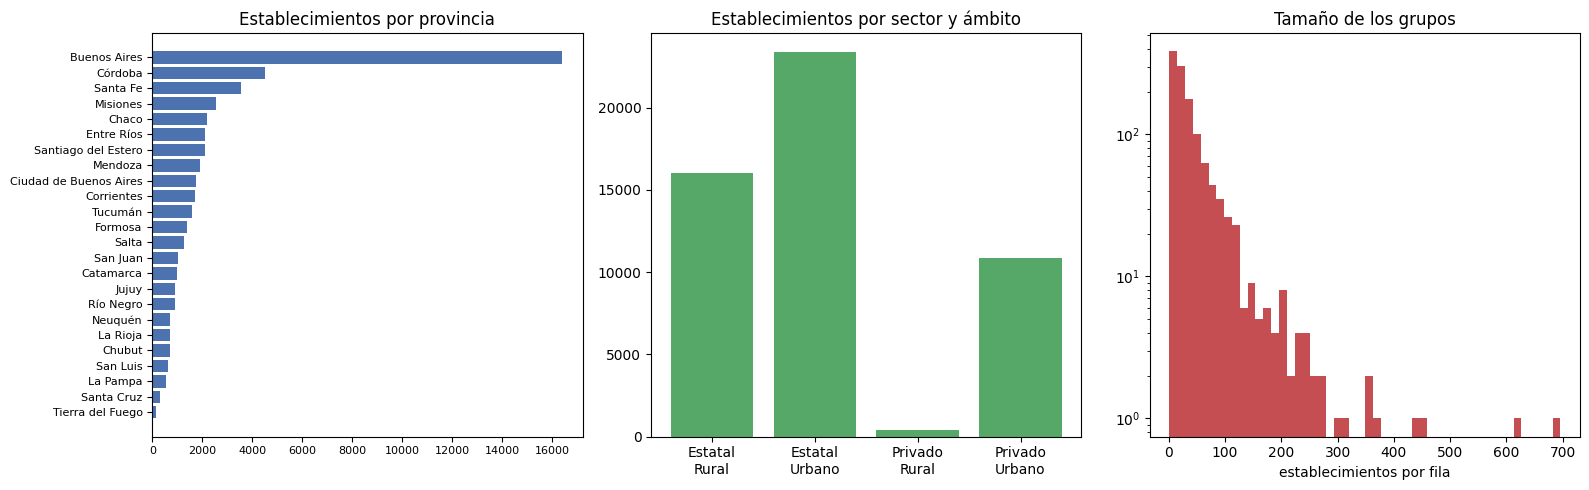

In [156]:
import matplotlib.pyplot as plt

base_eda = df_caracteristicas[IDS].apply(lambda s: s.str.strip()).copy()
base_eda["establecimientos"] = L.values

print("FILAS por sector y ámbito")
print(pd.crosstab(base_eda.sector, base_eda.ambito, margins=True).to_string())
print("\nESTABLECIMIENTOS por sector y ámbito")
print(pd.crosstab(base_eda.sector, base_eda.ambito,
                  values=base_eda.establecimientos, aggfunc="sum", margins=True).round(0).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 5))

pv = base_eda.groupby("provincia").establecimientos.sum().sort_values()
ax[0].barh(pv.index, pv.values, color="#4C72B0")
ax[0].set_title("Establecimientos por provincia")
ax[0].tick_params(labelsize=8)

comp = base_eda.groupby(["sector", "ambito"]).establecimientos.sum()
ax[1].bar([f"{s}\n{a}" for s, a in comp.index], comp.values, color="#55A868")
ax[1].set_title("Establecimientos por sector y ámbito")

ax[2].hist(base_eda.establecimientos, bins=50, color="#C44E52")
ax[2].set_title("Tamaño de los grupos")
ax[2].set_xlabel("establecimientos por fila")
ax[2].set_yscale("log")

plt.tight_layout(); plt.show()


Características tiene 1216 filas agregadas que representan 50.591 establecimientos. La composición la miramos de dos formas: por cantidad de grupos (filas) y por cantidad de establecimientos que representa cada grupo (`Localizacion`).

* *Distribución por filas*

| Sector    |   Rural |  Urbano |    Total |
| --------- | ------: | ------: | -------: |
| Estatal   |     454 |     445 |      899 |
| Privado   |      46 |     271 |      317 |
| **Total** | **500** | **716** | **1216** |

La mayoría de las filas son del sector estatal (73,9 % de los grupos), y el ámbito urbano reúne 716 filas contra 500 rurales.

* *Distribución ponderada por establecimientos*

| Sector    |   Rural |  Urbano |    Total |
| --------- | ------: | ------: | -------: |
| Estatal   |   16003 |   23368 |    39371 |
| Privado   |     388 |   10832 |    11220 |
| **Total** |**16391**|**34200**| **50591**|

Cuando ponderamos por establecimientos el desbalance es todavía más claro: el sector estatal concentra el 77,8 % de los establecimientos y el privado el 22,2 %; el ámbito urbano el 67,6 % y el rural el 32,4 %. Además los grupos tienen tamaños muy distintos (de 1 a 696 establecimientos, mediana 24), así que contar filas no es lo mismo que contar escuelas.

Este desbalance condiciona la predicción de la repitencia. Un modelo podría aprender sobre todo los patrones de los grupos estatales y urbanos y funcionar peor en los privados o rurales. Para controlarlo vamos a:

- incluir sector y ámbito como variables explicativas;
- evaluar el desempeño por subgrupo (estatal/privado y rural/urbano);
- ponderar por matrícula, para que un grupo de 30 alumnos no pese lo mismo que uno de 30.000;
- usar `Localizacion` solo como control de tamaño, no como si fuera una medida de infraestructura;
- descartar las tasas de los grupos muy chicos, que son muy inestables (lo hacemos en 5.6).

El desbalance no invalida el análisis, pero nos obliga a revisar que las predicciones no funcionen solamente para los grupos mayoritarios.

### Faltantes y su estructura



Características  celdas vacías:  22,371 (29.7% de las celdas de medición)

Columnas de Características con más faltantes:
equipamientobibliotecaequiporeceptorderadioamfm         100.0
equipamientoestablecimientoequiporeceptorderadioamfm    100.0
electricidadgeneradoreólico                              97.6
electricidadgeneradorhidráulico                          97.2
subvenciónestataljardínmaternalsi                        87.7
subvenciónestatalsnusi                                   85.0
electricidadotro                                         79.6
subvenciónestataljardíndeinfantessi                      76.4


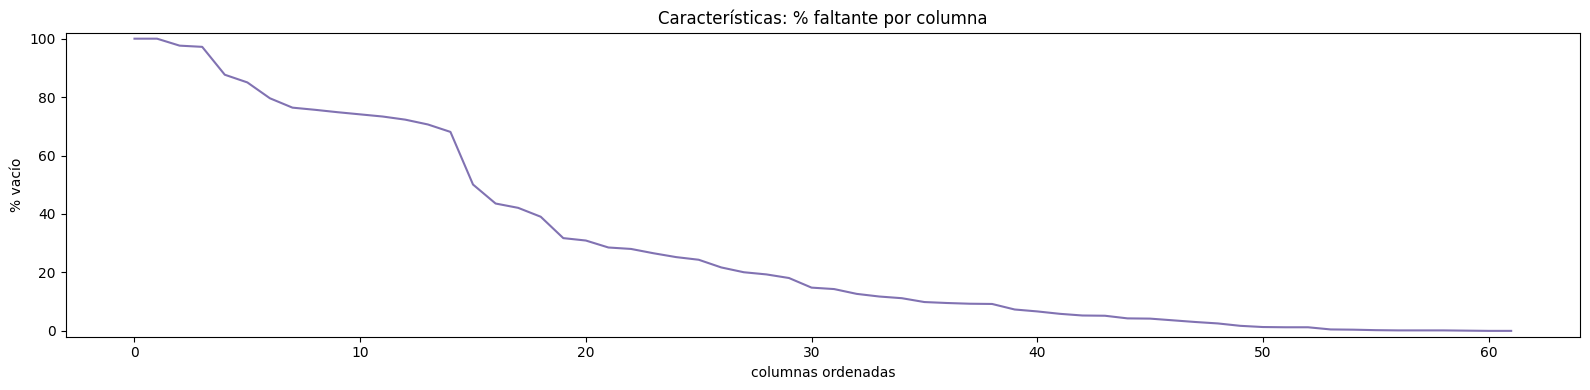

In [157]:
falt = {}

nombre = "Características"
d = df_caracteristicas

cols = [c for c in d.columns if c not in IDS]

S_ = d[cols].apply(
    lambda s: s.str.strip().replace("", np.nan)
)

falt[nombre] = S_.isna().mean() * 100

print(
    f"{nombre:<16} "
    f"celdas vacías: {S_.isna().sum().sum():>7,} "
    f"({S_.isna().mean().mean() * 100:>4.1f}% "
    f"de las celdas de medición)"
)

print("\nColumnas de Características con más faltantes:")
print(
    falt[nombre]
    .sort_values(ascending=False)
    .head(8)
    .round(1)
    .to_string()
)

fig, ax = plt.subplots(figsize=(16, 4))

serie = falt[nombre]

ax.plot(
    range(len(serie)),
    sorted(serie.values, reverse=True),
    color="#8172B2"
)

ax.set_title(f"{nombre}: % faltante por columna")
ax.set_xlabel("columnas ordenadas")
ax.set_ylabel("% vacío")
ax.set_ylim(-2, 102)

plt.tight_layout()
plt.show()


Características tiene 22.371 celdas vacías, el 29,7 % de las celdas de medición. No están repartidas de forma pareja: el gráfico muestra que 27 de las 62 columnas tienen menos de 10 % de vacíos, mientras que 16 superan el 50 %.

Las columnas con más vacíos son de equipamiento poco frecuente, de fuentes de energía alternativas (generador eólico 97,6 %, hidráulico 97,2 %) y de subvenciones para niveles que no todos los grupos tienen (jardín maternal 87,7 %, SNU 85,0 %). Los receptores de radio AM/FM, tanto del establecimiento como de la biblioteca, están 100 % vacíos.

Esto anticipa que no corresponde una imputación global. Las columnas totalmente vacías se descartan, y para el resto hay que entender qué significa el blanco antes de decidir: si es "no tiene el recurso" corresponde un 0; si es "no aplica" o "no se informó", no. Esa decisión la tomamos en 5.1.

### Infraestructura: cómo se distribuye

COBERTURA MEDIA (% de establecimientos del grupo)

                electricidad  internet_aulas  laboratorio  biblioteca
sector  ambito                                                       
Estatal Rural           98.0            54.1         22.9        61.7
        Urbano          99.4            58.5         37.0        76.5
Privado Rural           99.3            45.0         33.1        61.5
        Urbano          98.9            67.3         50.0        67.8


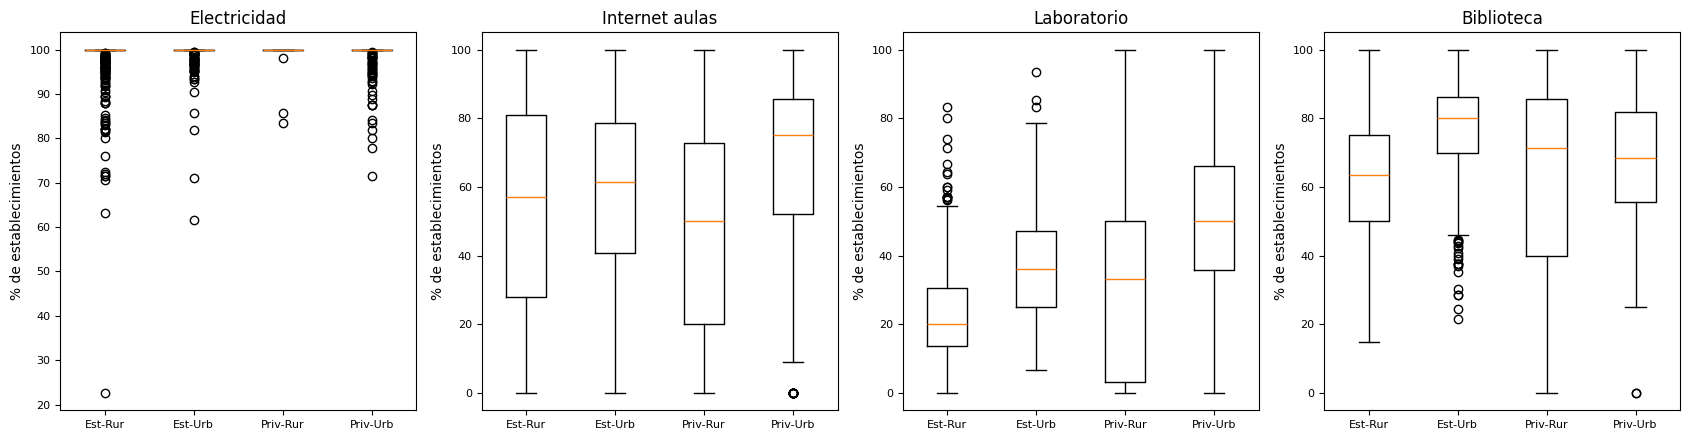

In [158]:
num_eda = lambda c: pd.to_numeric(df_caracteristicas[c].astype("string").str.strip().replace("", np.nan), errors="coerce").fillna(0)

ind = base_eda.copy()
ind["electricidad"]   = num_eda("electricidadsi") / L * 100
ind["internet_aulas"] = num_eda("espaciosconconexiónenlasaulas") / L * 100
ind["laboratorio"]    = num_eda("disponedesalaolaboratoriodeinformáticasi") / L * 100
ind["biblioteca"]     = num_eda("bibliotecadisponedealmenosunasi") / L * 100
VARS = ["electricidad", "internet_aulas", "laboratorio", "biblioteca"]

print("COBERTURA MEDIA (% de establecimientos del grupo)\n")
print(ind.groupby(["sector", "ambito"])[VARS].mean().round(1).to_string())

fig, ax = plt.subplots(1, 4, figsize=(17, 4.5))
for i, v in enumerate(VARS):
    datos = [ind[(ind.sector == s) & (ind.ambito == a)][v].dropna()
             for s in ["Estatal", "Privado"] for a in ["Rural", "Urbano"]]
    ax[i].boxplot(datos)
    ax[i].set_xticks(range(1, 5))
    ax[i].set_xticklabels(["Est-Rur", "Est-Urb", "Priv-Rur", "Priv-Urb"])
    ax[i].set_title(v.replace("_", " ").capitalize()); ax[i].set_ylabel("% de establecimientos")
    ax[i].tick_params(labelsize=8)
plt.tight_layout(); plt.show()

La electricidad está prácticamente universalizada: la cobertura va de 98,0 % a 99,4 % en los cuatro grupos. Es una condición básica importante, pero como casi no varía va a tener poca capacidad para diferenciar grupos en la predicción.

Las brechas grandes están en conectividad y laboratorios. Internet en las aulas va de 45,0 % en el privado rural a 67,3 % en el privado urbano (22,3 puntos de diferencia). El laboratorio de informática va de 22,9 % en el estatal rural a 50,0 % en el privado urbano (27,1 puntos). La biblioteca muestra diferencias menores, de 61,5 % en el privado rural a 76,5 % en el estatal urbano.

Los boxplots muestran además que dentro de cada grupo la dispersión es muy grande. En internet en aulas, por ejemplo, la mitad central de los grupos estatales rurales va de 28 % a 81 %: hay departamentos estatales rurales mejor conectados que la mayoría de los urbanos. O sea que sector y ámbito explican parte de la diferencia, pero no toda.

Como la infraestructura no es homogénea, tiene sentido incluir estas variables como posibles predictores de la repitencia 2025. Esto todavía no dice nada sobre causalidad: son diferencias observables entre grupos agregados. La relación con la repitencia la miramos en 6.2.

---
## 4.2 Dataset Matrícula

### Composición de la muestra

FILAS por sector y ámbito
ambito   Rural  Urbano   All
sector                      
Estatal    454     445   899
Privado     46     271   317
All        500     716  1216

ESTABLECIMIENTOS por sector y ámbito
ambito   Rural  Urbano    All
sector                       
Estatal  15922   23259  39181
Privado    387   10759  11146
All      16309   34018  50327


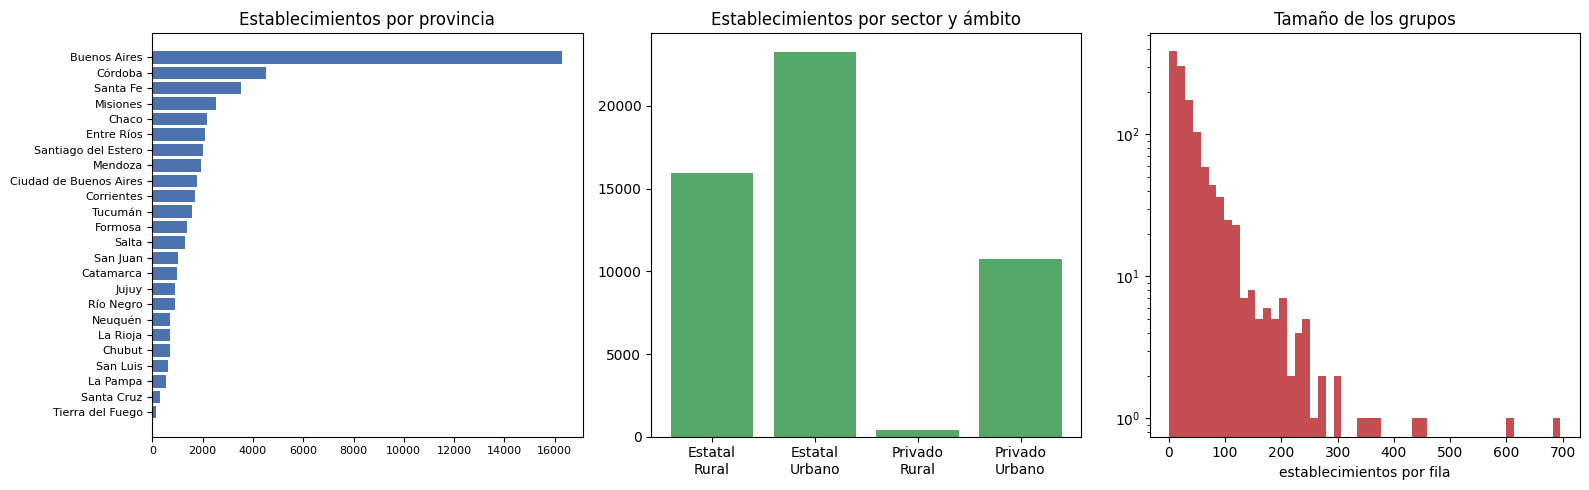

In [159]:
base_eda_matriculas = df_matriculas[IDS + ["localizacion"]].copy()
base_eda_matriculas[IDS] = base_eda_matriculas[IDS].apply(
    lambda s: s.astype("string").str.strip()
)

base_eda_matriculas["establecimientos"] = pd.to_numeric(
    base_eda_matriculas["localizacion"],
    errors="coerce"
)

base_eda_matriculas = base_eda_matriculas.drop(columns=["localizacion"])

print("FILAS por sector y ámbito")
print(pd.crosstab(base_eda_matriculas.sector, base_eda_matriculas.ambito, margins=True).to_string())
print("\nESTABLECIMIENTOS por sector y ámbito")
print(pd.crosstab(base_eda_matriculas.sector, base_eda_matriculas.ambito,
                  values=base_eda_matriculas.establecimientos, aggfunc="sum", margins=True).round(0).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 5))

pv = base_eda_matriculas.groupby("provincia").establecimientos.sum().sort_values()
ax[0].barh(pv.index, pv.values, color="#4C72B0")
ax[0].set_title("Establecimientos por provincia")
ax[0].tick_params(labelsize=8)

comp = base_eda_matriculas.groupby(["sector", "ambito"]).establecimientos.sum()
ax[1].bar([f"{s}\n{a}" for s, a in comp.index], comp.values, color="#55A868")
ax[1].set_title("Establecimientos por sector y ámbito")

ax[2].hist(base_eda_matriculas.establecimientos, bins=50, color="#C44E52")
ax[2].set_title("Tamaño de los grupos")
ax[2].set_xlabel("establecimientos por fila")
ax[2].set_yscale("log")

plt.tight_layout(); plt.show()

Matrícula también tiene 1216 filas agregadas, con exactamente la misma distribución por sector y ámbito que Características, porque tiene las mismas claves. La diferencia aparece en los establecimientos: acá suman 50.327, 264 menos que en Características.

* *Distribución por filas*

| Sector    |   Rural |  Urbano |    Total |
| --------- | ------: | ------: | -------: |
| Estatal   |     454 |     445 |      899 |
| Privado   |      46 |     271 |      317 |
| **Total** | **500** | **716** | **1216** |

* *Distribución ponderada por establecimientos*

| Sector    |   Rural |  Urbano |    Total |
| --------- | ------: | ------: | -------: |
| Estatal   |   15922 |   23259 |    39181 |
| Privado   |     387 |   10759 |    11146 |
| **Total** |**16309**|**34018**| **50327**|

La diferencia no está en qué grupos hay sino en cuántos establecimientos cuenta cada uno: en 116 grupos Matrícula registra menos establecimientos que Características (lo detallamos en 5.2). Las proporciones casi no cambian (estatal 77,9 %, urbano 67,6 %), así que el desbalance que vimos en Características se mantiene igual.

### Faltantes

Matriculas       celdas vacías:  22,264 (18.3% de las celdas de medición)

Columnas de Matriculas con más faltantes:
s_deambulantes    97.3
s_lactantes       97.2
s_s2              96.6
s_s3              91.2
_20               90.0
v_20              90.0
r_20              90.0
s_s4              84.5


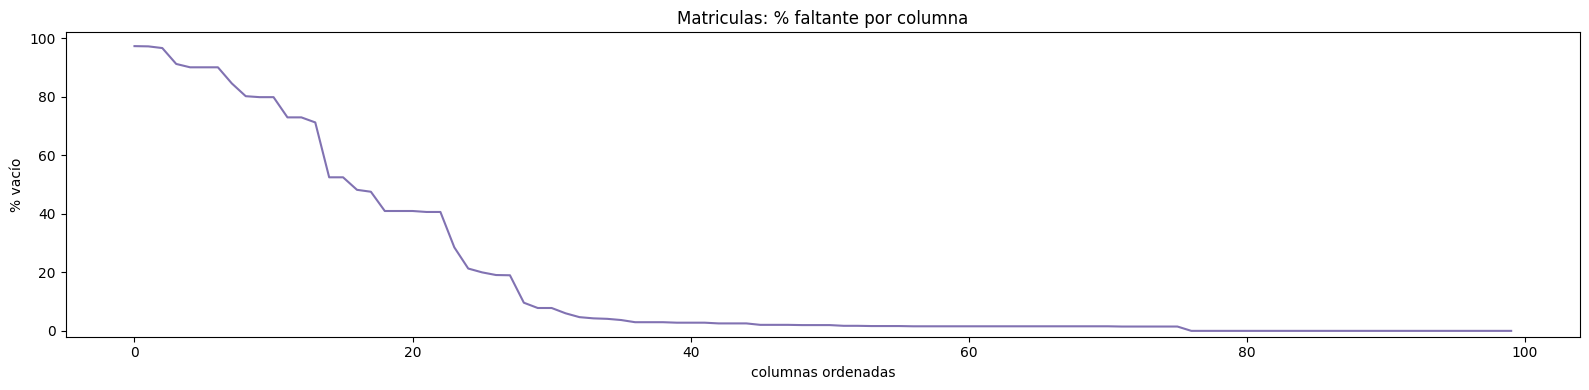

In [160]:
falt = {}

nombre = "Matriculas"
d = df_matriculas

cols = [c for c in d.columns if c not in IDS]

S_ = d[cols].apply(
    lambda s: s.str.strip().replace("", np.nan)
)

falt[nombre] = S_.isna().mean() * 100

print(
    f"{nombre:<16} "
    f"celdas vacías: {S_.isna().sum().sum():>7,} "
    f"({S_.isna().mean().mean() * 100:>4.1f}% "
    f"de las celdas de medición)"
)

print("\nColumnas de Matriculas con más faltantes:")
print(
    falt[nombre]
    .sort_values(ascending=False)
    .head(8)
    .round(1)
    .to_string()
)

fig, ax = plt.subplots(figsize=(16, 4))

serie = falt[nombre]

ax.plot(
    range(len(serie)),
    sorted(serie.values, reverse=True),
    color="#8172B2"
)

ax.set_title(f"{nombre}: % faltante por columna")
ax.set_xlabel("columnas ordenadas")
ax.set_ylabel("% vacío")
ax.set_ylim(-2, 102)

plt.tight_layout()
plt.show()

Matrícula tiene 22.264 celdas vacías, el 18,3 % de las celdas de medición. Otra vez el patrón no es aleatorio: los vacíos se concentran en la sobreedad del nivel inicial (`s_deambulantes` 97,3 %, `s_lactantes` 97,2 %, `s_s2` 96,6 %, `s_s3` 91,2 %) y en la categoría 20, que corresponde a establecimientos con organización no graduada (`_20`, `v_20` y `r_20`, 90,0 %).

Son columnas de niveles o categorías que la mayoría de los grupos no tiene, así que en general el vacío quiere decir "no aplica" más que un dato perdido. Por eso no conviene reemplazar todos los blancos por cero sin revisar cada bloque. Lo hacemos en 5.1, comparando cada resultado contra su denominador.

### Repitencia y sobreedad por sector y ámbito

TASAS MEDIAS POR SECTOR Y ÁMBITO

                tasa_repitencia  tasa_sobreedad
sector  ambito                                 
Estatal Rural               5.0            14.3
        Urbano              5.6            15.0
Privado Rural               4.4            15.3
        Urbano              1.3             4.1

TASAS AGREGADAS SOBRE EL TOTAL DE ALUMNOS

                matricula_total  repitentes_total  sobreedad_total  tasa_repitencia  tasa_sobreedad
sector  ambito                                                                                     
Estatal Rural          700069.0           38149.0         111891.0              5.4            16.0
        Urbano        5590000.0          319619.0         887541.0              5.7            15.9
Privado Rural           37937.0            1430.0           4858.0              3.8            12.8
        Urbano        2379490.0           25845.0          87848.0              1.1             3.7


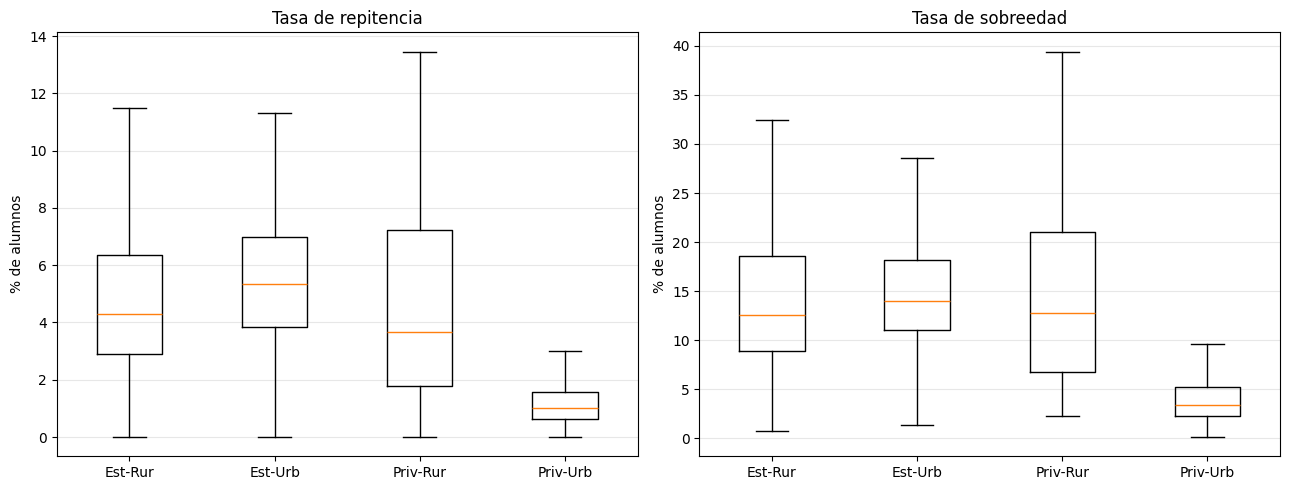

In [161]:
grados = range(1, 13)

def sumar_grados(df, prefijo):
    columnas = [
        f"{prefijo}_{grado}"
        for grado in grados
        if f"{prefijo}_{grado}" in df.columns
    ]

    return (
        df[columnas]
        .apply(pd.to_numeric, errors="coerce")
        .sum(axis=1, min_count=1)
    )


base_eda_matriculas = df_matriculas.copy()

base_eda_matriculas[IDS] = base_eda_matriculas[IDS].apply(
    lambda s: s.astype("string").str.strip()
)

base_eda_matriculas["establecimientos"] = pd.to_numeric(
    base_eda_matriculas["localizacion"],
    errors="coerce"
)

base_eda_matriculas["matricula_total"] = sumar_grados(
    base_eda_matriculas,
    ""
)

base_eda_matriculas["repitentes_total"] = sumar_grados(
    base_eda_matriculas,
    "r"
)

base_eda_matriculas["sobreedad_total"] = sumar_grados(
    base_eda_matriculas,
    "s"
)

base_eda_matriculas["tasa_repitencia"] = (
    base_eda_matriculas["repitentes_total"]
    / base_eda_matriculas["matricula_total"].replace(0, np.nan)
    * 100
)

base_eda_matriculas["tasa_sobreedad"] = (
    base_eda_matriculas["sobreedad_total"]
    / base_eda_matriculas["matricula_total"].replace(0, np.nan)
    * 100
)

VARS_MATRICULA = [
    "tasa_repitencia",
    "tasa_sobreedad"
]

print("TASAS MEDIAS POR SECTOR Y ÁMBITO\n")
print(
    base_eda_matriculas
    .groupby(["sector", "ambito"])[VARS_MATRICULA]
    .mean()
    .round(1)
    .to_string()
)

print("\nTASAS AGREGADAS SOBRE EL TOTAL DE ALUMNOS\n")

totales_matricula = (
    base_eda_matriculas
    .groupby(["sector", "ambito"])[
        [
            "matricula_total",
            "repitentes_total",
            "sobreedad_total"
        ]
    ]
    .sum()
)

totales_matricula["tasa_repitencia"] = (
    totales_matricula["repitentes_total"]
    / totales_matricula["matricula_total"]
    * 100
)

totales_matricula["tasa_sobreedad"] = (
    totales_matricula["sobreedad_total"]
    / totales_matricula["matricula_total"]
    * 100
)

print(
    totales_matricula[
        [
            "matricula_total",
            "repitentes_total",
            "sobreedad_total",
            "tasa_repitencia",
            "tasa_sobreedad"
        ]
    ]
    .round(1)
    .to_string()
)

combinaciones = [
    ("Estatal", "Rural"),
    ("Estatal", "Urbano"),
    ("Privado", "Rural"),
    ("Privado", "Urbano")
]

etiquetas = [
    "Est-Rur",
    "Est-Urb",
    "Priv-Rur",
    "Priv-Urb"
]

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

for eje, variable, titulo in zip(
    ax,
    ["tasa_repitencia", "tasa_sobreedad"],
    ["Tasa de repitencia", "Tasa de sobreedad"]
):
    datos = [
        base_eda_matriculas.loc[
            (base_eda_matriculas["sector"] == sector)
            & (base_eda_matriculas["ambito"] == ambito),
            variable
        ].dropna()
        for sector, ambito in combinaciones
    ]

    eje.boxplot(datos, tick_labels=etiquetas, showfliers=False)
    eje.set_title(titulo)
    eje.set_ylabel("% de alumnos")
    eje.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Acá calculamos la repitencia y la sobreedad de 1° a 12° de dos formas: como promedio de las tasas de los grupos y como tasa agregada (todos los repitentes sobre todos los alumnos de cada combinación de sector y ámbito).

La repitencia media va de 1,3 % en el privado urbano a 5,6 % en el estatal urbano, 4,3 puntos de diferencia. En las tasas agregadas la brecha es parecida: 5,7 % en el estatal urbano contra 1,1 % en el privado urbano.

La sobreedad muestra brechas todavía mayores. La media por grupo va de 4,1 % en el privado urbano a 15,3 % en el privado rural, y la agregada de 3,7 % en el privado urbano a 16,0 % en el estatal rural.

Que la media y la agregada no coincidan muestra otra vez que los grupos tienen tamaños muy distintos. El privado rural, por ejemplo, tiene medias altas por algunos grupos chicos (4,4 % de repitencia media contra 3,8 % agregada), pero pesa poco en el total de alumnos. Por eso en el modelo conviene conservar la matrícula de cada grupo para ponderar, y no quedarse solo con el promedio simple de las tasas.

Para la predicción, esto indica que Matrícula 2024 aporta antecedentes útiles: la repitencia previa, la sobreedad, el tamaño de la matrícula, el sector y el ámbito.

---
## 4.3 Dataset Trayectoria

### Composición de la muestra

Correspondencia con Características:
_merge
both          1207
left_only        2
right_only       0
Name: count, dtype: int64

Claves de Trayectoria sin correspondencia:
provincia departamento  sector ambito
  Formosa    Sin datos Estatal  Rural
  Tucumán    Sin datos Estatal  Rural
FILAS por sector y ámbito
ambito   Rural  Urbano   All
sector                      
Estatal    456     445   901
Privado     39     269   308
All        495     714  1209

ESTABLECIMIENTOS por sector y ámbito
ambito     Rural   Urbano      All
sector                            
Estatal  16003.0  23368.0  39371.0
Privado    341.0  10820.0  11161.0
All      16344.0  34188.0  50532.0


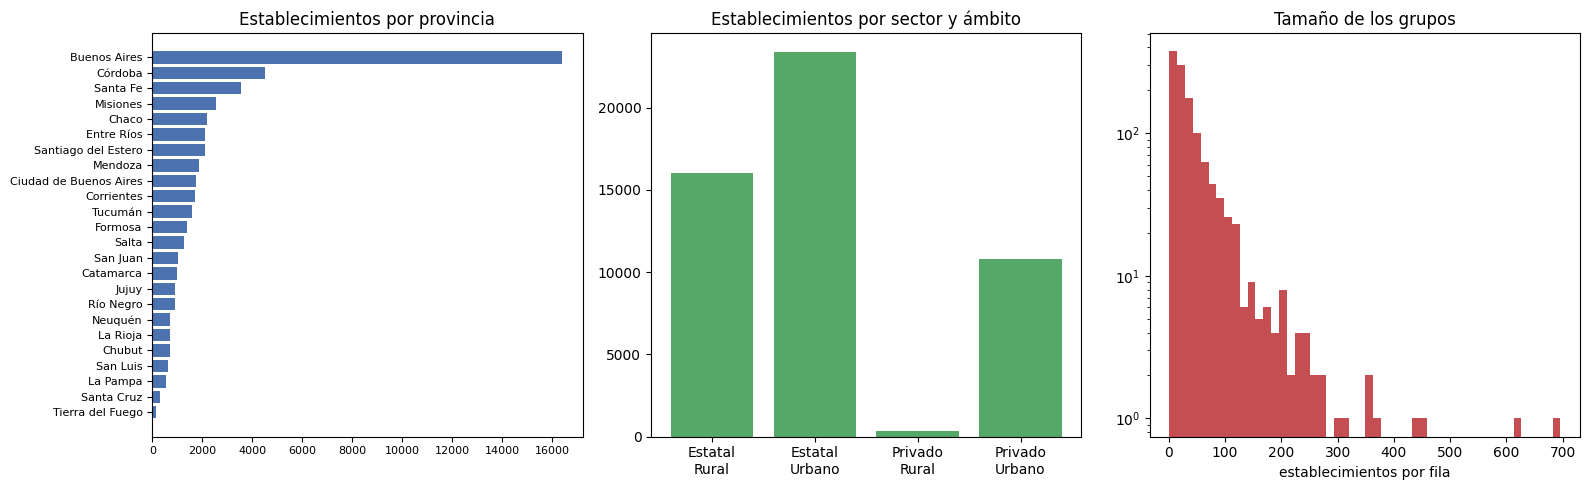

In [162]:
base_eda_trayectoria = (
    df_trayectoria[IDS]
    .copy()
    .merge(
        df_caracteristicas[IDS + ["localizacion"]],
        on=IDS,
        how="left",
        validate="one_to_one",
        indicator=True
    )
)

base_eda_trayectoria["establecimientos"] = pd.to_numeric(
    base_eda_trayectoria["localizacion"],
    errors="coerce"
)

print("Correspondencia con Características:")
print(base_eda_trayectoria["_merge"].value_counts())

faltantes = base_eda_trayectoria[
    base_eda_trayectoria["_merge"] != "both"
]

if not faltantes.empty:
    print("\nClaves de Trayectoria sin correspondencia:")
    print(faltantes[IDS].to_string(index=False))

base_eda_trayectoria = base_eda_trayectoria.drop(
    columns=["localizacion", "_merge"]
)

print("FILAS por sector y ámbito")
print(
    pd.crosstab(
        base_eda_trayectoria["sector"],
        base_eda_trayectoria["ambito"],
        margins=True
    ).to_string()
)

print("\nESTABLECIMIENTOS por sector y ámbito")
print(
    pd.crosstab(
        base_eda_trayectoria["sector"],
        base_eda_trayectoria["ambito"],
        values=base_eda_trayectoria["establecimientos"],
        aggfunc="sum",
        margins=True
    ).round(0).to_string()
)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))

pv = (
    base_eda_trayectoria
    .groupby("provincia")["establecimientos"]
    .sum()
    .sort_values()
)

ax[0].barh(pv.index, pv.values, color="#4C72B0")
ax[0].set_title("Establecimientos por provincia")
ax[0].tick_params(labelsize=8)

comp = (
    base_eda_trayectoria
    .groupby(["sector", "ambito"])["establecimientos"]
    .sum()
)

ax[1].bar(
    [f"{s}\n{a}" for s, a in comp.index],
    comp.values,
    color="#55A868"
)
ax[1].set_title("Establecimientos por sector y ámbito")

ax[2].hist(
    base_eda_trayectoria["establecimientos"].dropna(),
    bins=50,
    color="#C44E52"
)
ax[2].set_title("Tamaño de los grupos")
ax[2].set_xlabel("establecimientos por fila")
ax[2].set_yscale("log")

plt.tight_layout()
plt.show()

Al cruzar Trayectoria con Características, 1207 de sus 1209 filas encuentran su grupo. Las 2 que no cruzan tienen departamento `Sin datos` (Formosa y Tucumán, estatal rural) y no existen en las otras bases: ese es el "departamento" de más que vimos en el resumen. En sentido contrario, 9 grupos de Características no tienen fila en Trayectoria.

Tomando la `Localizacion` de Características, los grupos de Trayectoria representan 50.532 establecimientos, casi lo mismo que Características (50.591). La distribución por sector y ámbito también es casi igual (901 filas estatales y 308 privadas; 495 rurales y 714 urbanas); la diferencia se concentra en el privado rural, con 39 filas contra 46.

Para el modelo esto significa que los 9 grupos sin Trayectoria van a quedar con los salidos sin pase en NaN, y que los 2 grupos `Sin datos` se descartan porque no tienen infraestructura ni matrícula con las que vincularlos.

### Faltantes

Trayectoria      celdas vacías:  37,496 (10.9% de las celdas de medición)

Columnas de Trayectoria con más faltantes:
m_otros_20            99.8
m_nopromo_20          99.8
otros_20              99.8
promovidos_ex_20      99.8
nopromo_20            99.8
m_promovidos_ex_20    99.8
regulares_20          99.8
m_regulares_20        99.8


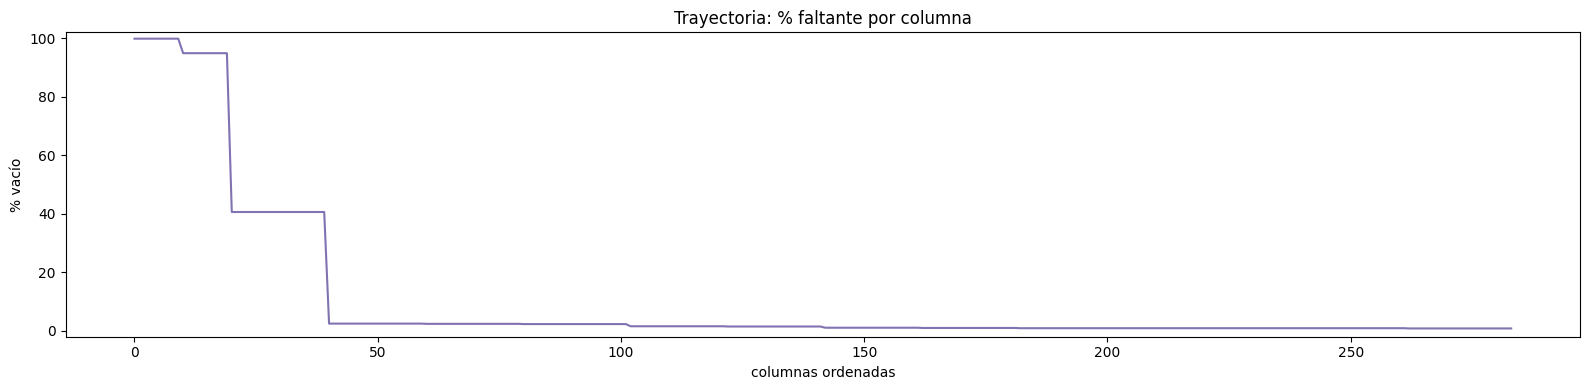

In [163]:
nombre = "Trayectoria"
d = df_trayectoria

cols = [c for c in d.columns if c not in IDS]

S_ = d[cols].apply(
    lambda s: s.str.strip().replace("", np.nan)
)

falt[nombre] = S_.isna().mean() * 100

print(
    f"{nombre:<16} "
    f"celdas vacías: {S_.isna().sum().sum():>7,} "
    f"({S_.isna().mean().mean() * 100:>4.1f}% "
    f"de las celdas de medición)"
)

print("\nColumnas de Trayectoria con más faltantes:")
print(
    falt[nombre]
    .sort_values(ascending=False)
    .head(8)
    .round(1)
    .to_string()
)

fig, ax = plt.subplots(figsize=(16, 4))

serie = falt[nombre]

ax.plot(
    range(len(serie)),
    sorted(serie.values, reverse=True),
    color="#8172B2"
)

ax.set_title(f"{nombre}: % faltante por columna")
ax.set_xlabel("columnas ordenadas")
ax.set_ylabel("% vacío")
ax.set_ylim(-2, 102)

plt.tight_layout()
plt.show()

Trayectoria tiene 37.496 celdas vacías, el 10,9 % de las celdas de medición. Es el porcentaje más bajo de las tres bases, pero en parte porque tiene muchas más columnas. Los vacíos se concentran casi por completo en la categoría 20 (columnas como `otros_20`, `nopromo_20` o `promovidos_ex_20` y sus versiones por sexo, todas con 99,8 %).

Igual que en Matrícula, son categorías que no corresponden a la mayoría de los grupos, no datos perdidos al azar. No tendría sentido imputarlas con la media ni con cero.

Mirando las tres bases juntas, los faltantes son estructurales y vienen por bloques. La limpieza entonces tiene que clasificar cada columna (aplica, no aplica, cero real o dato desconocido), descartar las que están completamente vacías o no varían, y conservar o completar el resto recién cuando esté claro qué significa el blanco.

### Movilidad, retención y promoción por sector y ámbito

Correspondencia con Características:
_merge
both          1207
left_only        2
right_only       0

TASAS MEDIAS POR SECTOR Y ÁMBITO

                tasa_salidos_sin_pase  tasa_salidos_con_pase  tasa_retencion  tasa_promocion  tasa_no_promocion
sector  ambito                                                                                                 
Estatal Rural                     1.0                    3.8            95.2            84.7                6.2
        Urbano                    0.9                    3.2            95.9            78.6                8.6
Privado Rural                     1.7                    3.1            95.2            73.0                8.5
        Urbano                    0.2                    1.3            98.4            84.2                3.3

TASAS AGREGADAS SOBRE EL TOTAL DE ALUMNOS

                tasa_salidos_sin_pase  tasa_salidos_con_pase  tasa_retencion  tasa_promocion  tasa_no_promocion
sector  ambito                      

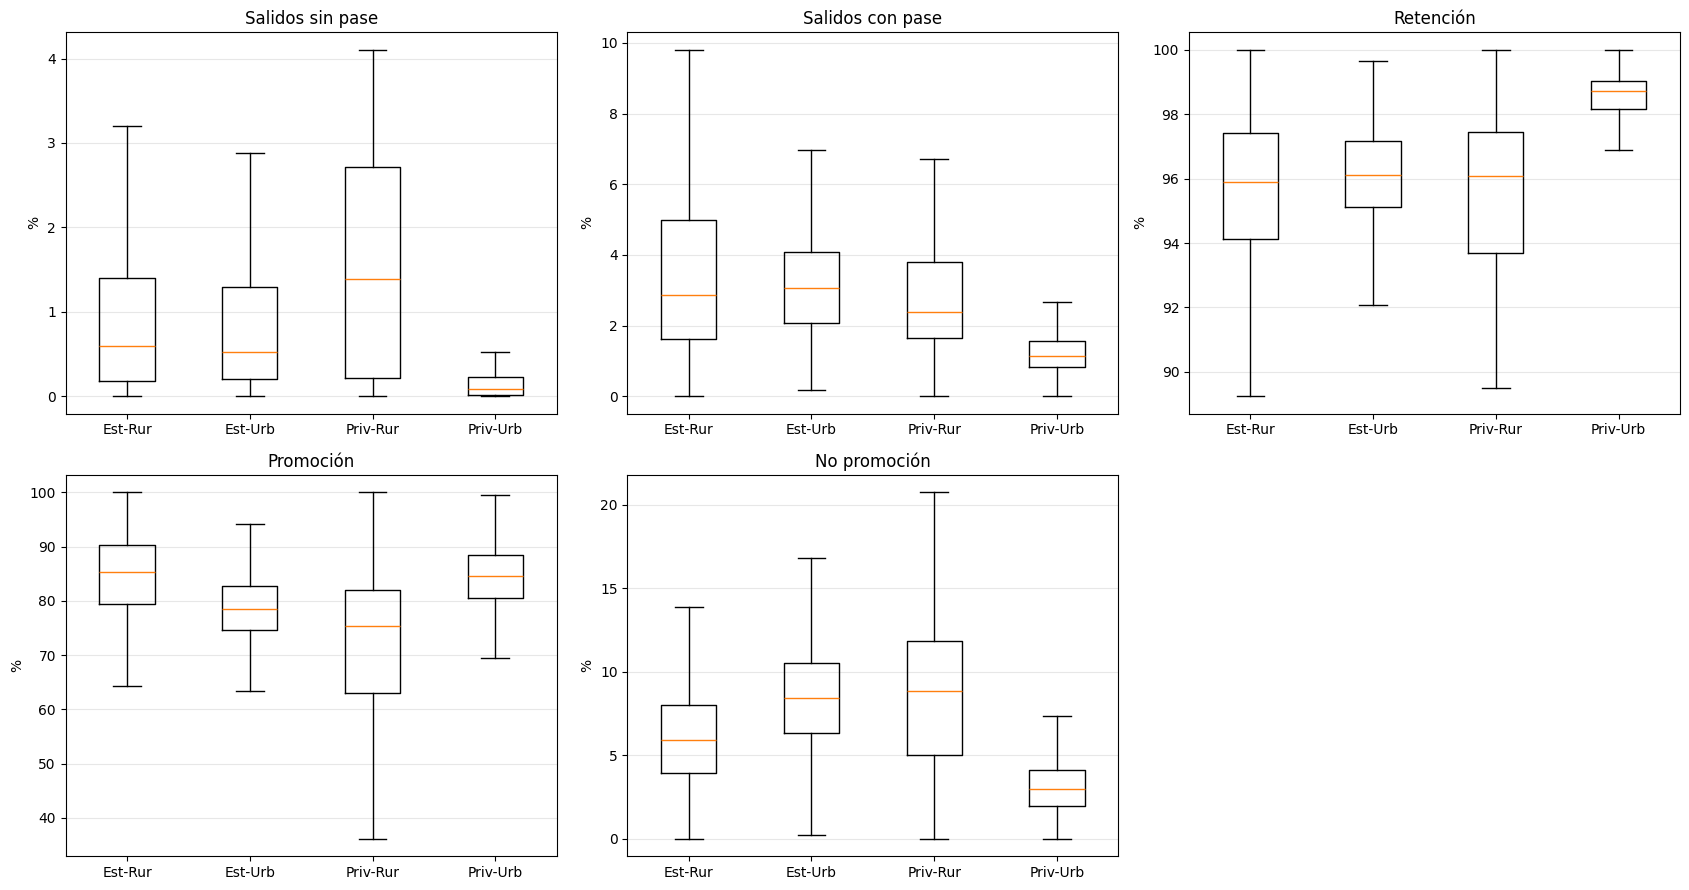

In [164]:
grados = range(1, 13)

def sumar_trayectoria(df, prefijo):
    columnas = [
        f"{prefijo}_{grado}"
        for grado in grados
        if f"{prefijo}_{grado}" in df.columns
    ]

    return (
        df[columnas]
        .apply(pd.to_numeric, errors="coerce")
        .sum(axis=1, min_count=1)
    )


base_eda_trayectoria = (
    df_trayectoria
    .copy()
    .merge(
        df_caracteristicas[IDS + ["localizacion"]],
        on=IDS,
        how="left",
        validate="one_to_one",
        indicator=True
    )
)

print("Correspondencia con Características:")
print(
    base_eda_trayectoria["_merge"]
    .value_counts()
    .to_string()
)

base_eda_trayectoria["establecimientos"] = pd.to_numeric(
    base_eda_trayectoria["localizacion"],
    errors="coerce"
)

categorias = [
    "inicial",
    "entrados",
    "ssp",
    "scp",
    "ultimo",
    "promovidos",
    "promovidos_ex",
    "nopromo"
]

for categoria in categorias:
    base_eda_trayectoria[categoria] = sumar_trayectoria(
        base_eda_trayectoria,
        categoria
    )

base_eda_trayectoria["matricula_disponible"] = (
    base_eda_trayectoria["inicial"]
    + base_eda_trayectoria["entrados"]
)

base_eda_trayectoria["tasa_entrados"] = (
    base_eda_trayectoria["entrados"]
    / base_eda_trayectoria["inicial"].replace(0, np.nan)
    * 100
)

base_eda_trayectoria["tasa_salidos_sin_pase"] = (
    base_eda_trayectoria["ssp"]
    / base_eda_trayectoria["matricula_disponible"].replace(0, np.nan)
    * 100
)

base_eda_trayectoria["tasa_salidos_con_pase"] = (
    base_eda_trayectoria["scp"]
    / base_eda_trayectoria["matricula_disponible"].replace(0, np.nan)
    * 100
)

base_eda_trayectoria["tasa_retencion"] = (
    base_eda_trayectoria["ultimo"]
    / base_eda_trayectoria["matricula_disponible"].replace(0, np.nan)
    * 100
)

base_eda_trayectoria["tasa_promocion"] = (
    base_eda_trayectoria["promovidos"]
    / base_eda_trayectoria["ultimo"].replace(0, np.nan)
    * 100
)

base_eda_trayectoria["tasa_promocion_examen"] = (
    base_eda_trayectoria["promovidos_ex"]
    / base_eda_trayectoria["ultimo"].replace(0, np.nan)
    * 100
)

base_eda_trayectoria["tasa_no_promocion"] = (
    base_eda_trayectoria["nopromo"]
    / base_eda_trayectoria["ultimo"].replace(0, np.nan)
    * 100
)

VARS_TRAYECTORIA = [
    "tasa_salidos_sin_pase",
    "tasa_salidos_con_pase",
    "tasa_retencion",
    "tasa_promocion",
    "tasa_no_promocion"
]

print("\nTASAS MEDIAS POR SECTOR Y ÁMBITO\n")
print(
    base_eda_trayectoria
    .groupby(["sector", "ambito"])[VARS_TRAYECTORIA]
    .mean()
    .round(1)
    .to_string()
)

print("\nTASAS AGREGADAS SOBRE EL TOTAL DE ALUMNOS\n")

totales_trayectoria = (
    base_eda_trayectoria
    .groupby(["sector", "ambito"])[
        [
            "inicial",
            "entrados",
            "ssp",
            "scp",
            "ultimo",
            "promovidos",
            "promovidos_ex",
            "nopromo"
        ]
    ]
    .sum()
)

totales_trayectoria["matricula_disponible"] = (
    totales_trayectoria["inicial"]
    + totales_trayectoria["entrados"]
)

totales_trayectoria["tasa_salidos_sin_pase"] = (
    totales_trayectoria["ssp"]
    / totales_trayectoria["matricula_disponible"]
    * 100
)

totales_trayectoria["tasa_salidos_con_pase"] = (
    totales_trayectoria["scp"]
    / totales_trayectoria["matricula_disponible"]
    * 100
)

totales_trayectoria["tasa_retencion"] = (
    totales_trayectoria["ultimo"]
    / totales_trayectoria["matricula_disponible"]
    * 100
)

totales_trayectoria["tasa_promocion"] = (
    totales_trayectoria["promovidos"]
    / totales_trayectoria["ultimo"]
    * 100
)

totales_trayectoria["tasa_no_promocion"] = (
    totales_trayectoria["nopromo"]
    / totales_trayectoria["ultimo"]
    * 100
)

print(
    totales_trayectoria[VARS_TRAYECTORIA]
    .round(1)
    .to_string()
)

combinaciones = [
    ("Estatal", "Rural"),
    ("Estatal", "Urbano"),
    ("Privado", "Rural"),
    ("Privado", "Urbano")
]

etiquetas = [
    "Est-Rur",
    "Est-Urb",
    "Priv-Rur",
    "Priv-Urb"
]

fig, ax = plt.subplots(2, 3, figsize=(17, 9))

variables_grafico = [
    ("tasa_salidos_sin_pase", "Salidos sin pase"),
    ("tasa_salidos_con_pase", "Salidos con pase"),
    ("tasa_retencion", "Retención"),
    ("tasa_promocion", "Promoción"),
    ("tasa_no_promocion", "No promoción")
]

for eje, (variable, titulo) in zip(ax.ravel(), variables_grafico):
    datos = [
        base_eda_trayectoria.loc[
            (base_eda_trayectoria["sector"] == sector)
            & (base_eda_trayectoria["ambito"] == ambito),
            variable
        ].dropna()
        for sector, ambito in combinaciones
    ]

    eje.boxplot(datos, tick_labels=etiquetas, showfliers=False)
    eje.set_title(titulo)
    eje.set_ylabel("%")
    eje.grid(axis="y", alpha=0.3)

ax.ravel()[-1].axis("off")

plt.tight_layout()
plt.show()

Con Trayectoria 2024 calculamos cinco indicadores por grupo: salidos sin pase, salidos con pase y retención (sobre la matrícula disponible, inicial + entrados), y promoción y no promoción (sobre la matrícula final).

- **Salidos sin pase:** la media va de 0,2 % en el privado urbano a 1,7 % en el privado rural. Salir sin pase no es lo mismo que abandonar, aunque es lo más cercano que tenemos.
- **Salidos con pase:** los valores más altos están en el estatal rural (3,8 %) y en el estatal urbano (3,2 %); en el privado urbano es 1,3 %. Esto es movilidad entre escuelas, no necesariamente algo negativo.
- **Retención:** es alta en todos los grupos. El privado urbano tiene la más alta (98,4 % de media y 98,6 % agregada) y el resto está entre 95 % y 96 %.
- **Promoción y no promoción:** acá están las diferencias más grandes. La promoción media va de 73,0 % en el privado rural a 84,7 % en el estatal rural (en la agregada, de 74,9 % a 84,3 %). La no promoción más alta está en el estatal urbano (8,6 % de media y 9,0 % agregada), contra 3,3 % y 3,0 % en el privado urbano.

Para la predicción, Trayectoria 2024 aporta antecedentes que acompañan a la repitencia. Hay que tener en cuenta que `nopromo` no es lo mismo que repitencia (un alumno no promovido puede repetir, cambiarse de escuela o dejar) y que `ssp` no es automáticamente abandono, así que los tratamos como predictores propios y no como sustitutos del objetivo. En el dataset limpio incorporamos por ahora los salidos sin pase por nivel (5.6); promoción y no promoción quedan como candidatas para la etapa de selección de variables del modelo.

---
## 4.4 Repitencia y sobreedad por nivel (primaria vs. secundaria)

TASAS POR GRUPO AGREGADO (%)

          count   mean    50%    max
rep_pri  1198.0   1.99   0.89  21.43
rep_sec  1200.0   6.95   6.39  48.21
sob_pri  1198.0   5.11   2.91  51.09
sob_sec  1200.0  20.44  20.32  75.45

POR SECTOR Y ÁMBITO

                rep_pri  rep_sec  sob_pri  sob_sec
sector  ambito                                    
Estatal Rural      2.71     7.93     6.82    24.31
        Urbano     2.29     9.03     5.60    24.99
Privado Rural      1.96     5.42     8.51    17.83
        Urbano     0.28     2.11     1.06     6.82


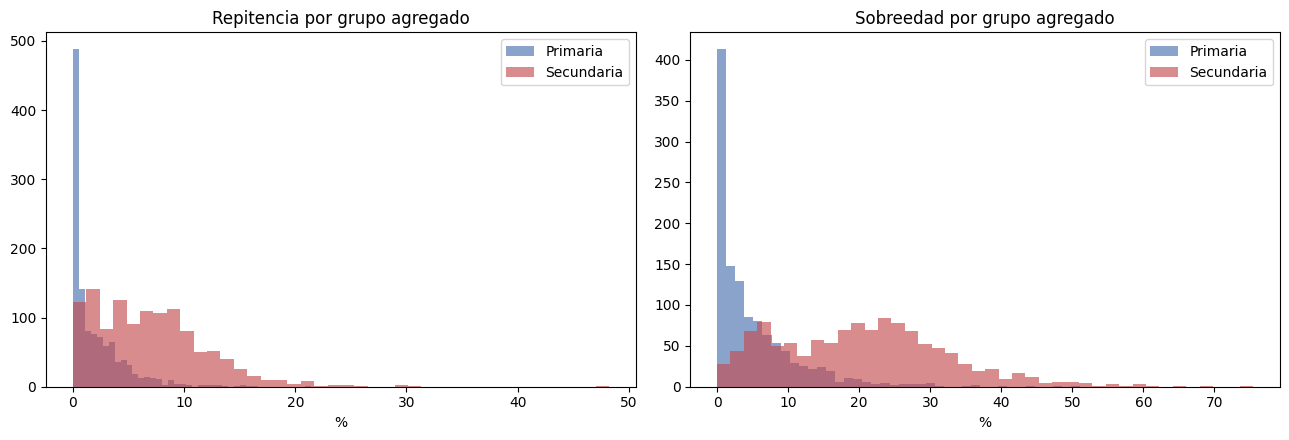

In [165]:
mat_eda = df_matriculas.copy()

for c in IDS:
    mat_eda[c] = mat_eda[c].str.strip()

nm = lambda cols: mat_eda[cols].apply(
    lambda s: pd.to_numeric(s.str.strip().replace("", np.nan), errors="coerce")
).fillna(0).sum(axis=1)

PRI_ = [str(i) for i in range(1, 7)]
SEC_ = [str(i) for i in range(7, 13)]

e = mat_eda[IDS].copy()

e["rep_pri"] = nm(["r_" + i for i in PRI_]) / nm(["_" + i for i in PRI_]).replace(0, np.nan) * 100
e["rep_sec"] = nm(["r_" + i for i in SEC_]) / nm(["_" + i for i in SEC_]).replace(0, np.nan) * 100
e["sob_pri"] = nm(["s_" + i for i in PRI_]) / nm(["_" + i for i in PRI_]).replace(0, np.nan) * 100
e["sob_sec"] = nm(["s_" + i for i in SEC_]) / nm(["_" + i for i in SEC_]).replace(0, np.nan) * 100

VARIABLES = ["rep_pri", "rep_sec", "sob_pri", "sob_sec"]

print("TASAS POR GRUPO AGREGADO (%)\n")
print(
    e[VARIABLES].describe().T[
        ["count", "mean", "50%", "max"]
    ].round(2).to_string()
)

print("\nPOR SECTOR Y ÁMBITO\n")
print(
    e.groupby(["sector", "ambito"])[VARIABLES]
    .mean()
    .round(2)
    .to_string()
)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

for i, (p, s, t) in enumerate([
    ("rep_pri", "rep_sec", "Repitencia"),
    ("sob_pri", "sob_sec", "Sobreedad")
]):
    ax[i].hist(e[p].dropna(), bins=40, alpha=.65, label="Primaria", color="#4C72B0")
    ax[i].hist(e[s].dropna(), bins=40, alpha=.65, label="Secundaria", color="#C44E52")
    ax[i].set_title(f"{t} por grupo agregado")
    ax[i].set_xlabel("%")
    ax[i].legend()

plt.tight_layout()
plt.show()

> Estas tasas son **preliminares**: cortan primaria en 6° para todas las provincias y no aplican ningún
> mínimo de matrícula. En la sección 5.6 las recalculamos respetando la estructura 6-6 / 7-5 de cada
> provincia y descartando los grupos con menos de 30 alumnos, por eso los valores finales cambian un poco.

La repitencia y la sobreedad son mucho más altas en secundaria que en primaria: la repitencia media por grupo es 6,95 % contra 1,99 %, y la sobreedad 20,44 % contra 5,11 %. En primaria la mediana de repitencia es 0,89 %, menos de la mitad de la media: muchos grupos con valores bajos y unos pocos muy altos.

Las distribuciones son asimétricas a la derecha, con máximos de 48,21 % de repitencia y 75,45 % de sobreedad en secundaria, y de 21,43 % y 51,09 % en primaria. La repitencia más alta aparece en los grupos estatales (urbano en secundaria con 9,03 %, rural en primaria con 2,71 %), y el privado urbano tiene las tasas más bajas en todo (0,28 % de repitencia en primaria y 2,11 % en secundaria).

Como primaria y secundaria se comportan tan distinto, no tiene sentido predecirlas juntas: vamos a armar un modelo para cada nivel. Y como la sobreedad acompaña a la repitencia (un alumno que repite queda con sobreedad), es un antecedente que esperamos que pese mucho en la predicción.

---
# 5. 🧹 Limpieza y preprocesamiento

*Punto 3 de la entrega: justificación de las tareas realizadas.*

**Limpieza** (5.1 y 5.2) y **preprocesamiento** (5.3 a 5.7).


## 5.1 Limpieza — la codificación de los faltantes






In [166]:
S = lambda d, c: d[c].astype("string").str.strip().replace("", np.nan)

N = lambda d, c: pd.to_numeric(S(d, c), errors="coerce")

def perfil_faltantes(d, nombre):
    cols = [c for c in d.columns if c not in IDS]
    valores = d[cols].apply(lambda s: s.astype("string").str.strip().replace("", np.nan))

    con_blanco = set(valores.columns[valores.isna().any()])
    con_cero = set(valores.columns[(valores == "0").any()])
    ambos = con_blanco & con_cero

    print(
        f"{nombre:<16} "
        f"vacias={int(valores.isna().sum().sum()):>7}  "
        f"ceros={int((valores == '0').sum().sum()):>7}  "
        f"columnas_con_AMBOS={len(ambos):>3}")

    return ambos

print("Columnas que usan blanco Y cero a la vez:\n")

a_car = perfil_faltantes(df_caracteristicas, "Características")
a_mat = perfil_faltantes(df_matriculas, "Matrícula")
a_tra = perfil_faltantes(df_trayectoria, "Trayectoria")

def revisar_blancos(d, denominador, resultado, nombre):
    riesgo = 0

    for i in map(str, range(1, 13)):
        base = N(d, denominador + i)
        valor = S(d, resultado + i)

        riesgo += int(((base > 0) & valor.isna()).sum())

    print(f"{nombre:<45} {riesgo:>5} casos con denominador > 0 y resultado en blanco")

    return riesgo


print("\nValidación de blancos según denominador:\n")

riesgo_rep = revisar_blancos(df_matriculas, "_", "r_", "Matrícula: repitentes")
riesgo_sob = revisar_blancos(df_matriculas, "_", "s_", "Matrícula: sobreedad")
riesgo_ssp = revisar_blancos(df_trayectoria,"inicial_", "ssp_", "Trayectoria: salidos sin pase")
riesgo_scp = revisar_blancos(df_trayectoria, "inicial_", "scp_", "Trayectoria: salidos con pase")
riesgo_prom = revisar_blancos(df_trayectoria, "ultimo_", "promovidos_", "Trayectoria: promovidos")
riesgo_prom_ex = revisar_blancos(df_trayectoria, "ultimo_", "promovidos_ex_", "Trayectoria: promovidos con examen")
riesgo_nopromo = revisar_blancos(df_trayectoria, "ultimo_", "nopromo_", "Trayectoria: no promovidos")

Columnas que usan blanco Y cero a la vez:

Características  vacias=  22371  ceros=      0  columnas_con_AMBOS=  0
Matrícula        vacias=  22264  ceros=  12223  columnas_con_AMBOS= 26
Trayectoria      vacias=  37496  ceros= 106780  columnas_con_AMBOS=263

Validación de blancos según denominador:

Matrícula: repitentes                             0 casos con denominador > 0 y resultado en blanco
Matrícula: sobreedad                           2009 casos con denominador > 0 y resultado en blanco
Trayectoria: salidos sin pase                     0 casos con denominador > 0 y resultado en blanco
Trayectoria: salidos con pase                     0 casos con denominador > 0 y resultado en blanco
Trayectoria: promovidos                           0 casos con denominador > 0 y resultado en blanco
Trayectoria: promovidos con examen                0 casos con denominador > 0 y resultado en blanco
Trayectoria: no promovidos                        0 casos con denominador > 0 y resultado en blanco


**Qué encontramos.** Los faltantes no vienen como celdas vacías sino como un espacio en blanco (`' '`), y además algunas columnas usan el blanco y el 0 al mismo tiempo. Eso quiere decir que un blanco no siempre significa lo mismo.

**Cómo lo sabemos.** Contamos, en cada base, las columnas que tienen blancos y ceros a la vez. En Características son 0: hay 22.371 blancos y ningún cero escrito, o sea que esta base nunca escribe "0" y el blanco ocupa ese lugar. En Matrícula son 26 columnas y en Trayectoria 263, así que ahí el 0 y el blanco conviven y tienen que significar cosas distintas.

Para entender ese blanco lo comparamos con su denominador. En repitentes, salidos sin pase, salidos con pase, promovidos, promovidos con examen y no promovidos hay **0 casos** con alumnos en el año y el resultado en blanco: cuando hay alumnos el dato siempre está (aunque sea 0), y el blanco solo aparece donde no hay alumnos, es decir, "no aplica". La excepción es la sobreedad: hay 2.009 casos con matrícula y sobreedad en blanco, la mayoría en los primeros años de primaria.

**Qué decidimos.**
- En Características el blanco es 0 (el establecimiento no tiene ese recurso), y con eso pasamos a coberturas.
- En Matrícula y Trayectoria no hacemos una imputación general. Al sumar los años de cada nivel el blanco cuenta como 0, lo que equivale a "no aplica" porque en esos casos tampoco hay alumnos en el denominador.
- En sobreedad, el blanco con matrícula también lo tomamos como 0. Es la lectura más razonable (no se informaron alumnos con sobreedad), pero puede subestimar un poco la sobreedad de algunos grupos. Como la sobreedad es un predictor y no el objetivo, lo dejamos anotado como limitación.

**Qué pasaba si no lo hacíamos.** Si imputábamos la media en Características estaríamos inventando valores en casi el 30 % de las celdas, y justo en las columnas donde el blanco significa que el recurso no está. En Matrícula y Trayectoria, tratar el blanco como dato desconocido nos hubiera hecho perder grupos enteros por categorías que ni siquiera les corresponden.

## 5.2 Otros problemas de calidad


In [167]:
BASES = {
    "Características": df_caracteristicas,
    "Matrícula": df_matriculas,
    "Trayectoria": df_trayectoria,
}

def texto(s):
    return s.astype("string").str.strip().replace("", pd.NA)

def num(d, cols):
    return d[cols].apply(lambda s: pd.to_numeric(texto(s), errors="coerce"))

def keyset(d):
    claves = d[IDS].apply(texto).drop_duplicates()

    return set(map(tuple,claves.itertuples(index=False, name=None)))

print("DIMENSIONES Y DUPLICADOS\n")

for nombre, d in BASES.items():
    print(
        f"{nombre:<16} "
        f"filas={len(d):4} "
        f"columnas={d.shape[1]:3} "
        f"duplicados_fila={d.duplicated().sum():3} "
        f"duplicados_clave={d.duplicated(IDS).sum():3}"
    )


# Columnas completamente vacías en Características
cols_car = [c for c in df_caracteristicas.columns
    if c not in IDS
]

car_valores = df_caracteristicas[cols_car].apply(texto)

vacias_car = car_valores.columns[car_valores.isna().all()].tolist()

df_caracteristicas_limpio = df_caracteristicas.drop(columns=vacias_car)

print(
    f"\nCaracterísticas: "
    f"{df_caracteristicas.shape[1]} -> "
    f"{df_caracteristicas_limpio.shape[1]} columnas"
)

# Departamentos enmascarados
print("\nFILAS CON DEPARTAMENTO 'ENMASCARADO'")

for nombre, d in BASES.items():
    cantidad = texto(d["departamento"]).eq("Enmascarado").sum()
    print(f"{nombre:<16} {cantidad:3} filas")

# Controles de coherencia
def incumplimientos(d, columnas_a, columnas_b):
    a = num(d, columnas_a).to_numpy(dtype=float)
    b = num(d, columnas_b).to_numpy(dtype=float)

    validos = (np.isfinite(a) & np.isfinite(b))

    return int(((a > b) & validos).sum())


AA = [str(i) for i in range(1, 13)]

print("\nCONTROLES DE COHERENCIA")

print("Matrícula: repitentes > matrícula:",incumplimientos(df_matriculas, [f"r_{i}" for i in AA], [f"_{i}" for i in AA]))

print("Matrícula: sobreedad > matrícula:", incumplimientos(df_matriculas,[f"s_{i}" for i in AA], [f"_{i}" for i in AA]))

print("Trayectoria: salidos sin pase > inicial:", incumplimientos(df_trayectoria, [f"ssp_{i}" for i in AA], [f"inicial_{i}" for i in AA]))

print("Trayectoria: salidos con pase > inicial:", incumplimientos(df_trayectoria, [f"scp_{i}" for i in AA], [f"inicial_{i}" for i in AA]))

print("Trayectoria: promovidos > último:", incumplimientos(df_trayectoria, [f"promovidos_{i}" for i in AA], [f"ultimo_{i}" for i in AA]))

print("Trayectoria: no promovidos > último:", incumplimientos(df_trayectoria, [f"nopromo_{i}" for i in AA], [f"ultimo_{i}" for i in AA]))


# Valores negativos
print("\nVALORES NEGATIVOS")

for nombre, d in BASES.items():
    cols = [c for c in d.columns
        if c not in IDS
    ]

    valores = num(d, cols)
    negativos = int((valores < 0).sum().sum())

    print(f"{nombre:<16} {negativos}")


# Consistencia de categorías
print("\nCONSISTENCIA DE CATEGORÍAS")

for columna in ["sector", "ambito"]:
    categorias = {nombre: set(texto(d[columna]).dropna().unique())
        for nombre, d in BASES.items()
    }

    consistentes = len({frozenset(valores)
        for valores in categorias.values()
    }) == 1

    print(f"{columna:<10} - consistentes: {consistentes}"
    )
    print(categorias)


# Auditoría de claves entre bases
print("\nAUDITORÍA DE CLAVES")

for nombre, d in BASES.items():
    print(
        f"{nombre:<16} - claves únicas: {len(keyset(d)):4}"
    )


pares = [
    ("Características", "Matrícula"),
    ("Características", "Trayectoria"),
    ("Matrícula", "Trayectoria")
]

for base_a, base_b in pares:
    claves_a = keyset(BASES[base_a])
    claves_b = keyset(BASES[base_b])

    print(
        f"{base_a} vs {base_b}: "
        f"comunes={len(claves_a & claves_b):4} | "
        f"solo {base_a}={len(claves_a - claves_b):3} | "
        f"solo {base_b}={len(claves_b - claves_a):3}"
    )



DIMENSIONES Y DUPLICADOS

Características  filas=1216 columnas= 66 duplicados_fila=  0 duplicados_clave=  0
Matrícula        filas=1216 columnas=104 duplicados_fila=  0 duplicados_clave=  0
Trayectoria      filas=1209 columnas=288 duplicados_fila=  0 duplicados_clave=  0

Características: 66 -> 64 columnas

FILAS CON DEPARTAMENTO 'ENMASCARADO'
Características   66 filas
Matrícula         66 filas
Trayectoria       65 filas

CONTROLES DE COHERENCIA
Matrícula: repitentes > matrícula: 0
Matrícula: sobreedad > matrícula: 0
Trayectoria: salidos sin pase > inicial: 0
Trayectoria: salidos con pase > inicial: 0
Trayectoria: promovidos > último: 0
Trayectoria: no promovidos > último: 0

VALORES NEGATIVOS
Características  0
Matrícula        0
Trayectoria      0

CONSISTENCIA DE CATEGORÍAS
sector     - consistentes: True
{'Características': {'Privado', 'Estatal'}, 'Matrícula': {'Privado', 'Estatal'}, 'Trayectoria': {'Privado', 'Estatal'}}
ambito     - consistentes: True
{'Características': {'Urba

In [168]:
print("\nCOMPARACIÓN DE LOCALIZACIÓN")

localizacion = (
    df_caracteristicas[IDS + ["localizacion"]]
    .merge(
        df_matriculas[IDS + ["localizacion"]],
        on=IDS,
        how="outer",
        suffixes=("_car", "_mat"),
        indicator=True,
        validate="one_to_one"
    )
)

localizacion["localizacion_car"] = pd.to_numeric(
    localizacion["localizacion_car"],
    errors="coerce"
)

localizacion["localizacion_mat"] = pd.to_numeric(
    localizacion["localizacion_mat"],
    errors="coerce"
)

localizacion["diferencia"] = (
    localizacion["localizacion_mat"]
    - localizacion["localizacion_car"]
)

print(
    localizacion["_merge"]
    .value_counts()
    .to_string()
)

ambas = localizacion["_merge"].eq("both")

print(
    "Claves con distinta localizacion:",
    int(
        (
            ambas
            & localizacion["diferencia"].ne(0)
        ).sum()
    )
)

print(
    "Total Características:",
    localizacion["localizacion_car"].sum()
)

print(
    "Total Matrícula:",
    localizacion["localizacion_mat"].sum()
)


COMPARACIÓN DE LOCALIZACIÓN
_merge
both          1216
left_only        0
right_only       0
Claves con distinta localizacion: 116
Total Características: 50591
Total Matrícula: 50327


In [169]:
diferencias_loc = localizacion[
    localizacion["_merge"].eq("both")
    & localizacion["diferencia"].ne(0)
].copy()

print(diferencias_loc["diferencia"].describe().round(2))

print(
    diferencias_loc[
        IDS
        + [
            "localizacion_car",
            "localizacion_mat",
            "diferencia"
        ]
    ]
    .sort_values("diferencia")
    .head(10)
    .to_string(index=False)
)

count    116.00
mean      -2.28
std        2.20
min      -11.00
25%       -3.00
50%       -1.00
75%       -1.00
max       -1.00
Name: diferencia, dtype: float64
          provincia        departamento  sector ambito  localizacion_car  localizacion_mat  diferencia
       Buenos Aires            LA PLATA Privado Urbano               317               306         -11
       Buenos Aires          SAN MIGUEL Privado Urbano               146               136         -10
       Buenos Aires            LA PLATA Estatal Urbano               355               346          -9
Santiago del Estero              ROBLES Estatal Urbano                31                22          -9
Santiago del Estero              LORETO Estatal  Rural                65                56          -9
       Buenos Aires          LA MATANZA Estatal Urbano               615               607          -8
       Buenos Aires     LOMAS DE ZAMORA Privado Urbano               254               247          -7
Santiago del Es

**Qué encontramos y cómo lo sabemos.** Corrimos una serie de controles sobre las tres bases:

- **Duplicados:** 0 filas duplicadas y 0 claves duplicadas en las tres bases.
- **Columnas vacías:** 2 columnas de Características (los receptores de radio AM/FM del establecimiento y de la biblioteca) no tienen un solo dato en todo el país. Características pasa de 66 a 64 columnas.
- **Departamentos enmascarados:** 66 filas en Características y en Matrícula, y 65 en Trayectoria, tienen el departamento como `Enmascarado`.
- **Coherencia:** 0 casos de repitentes o sobreedad mayores a la matrícula, 0 salidos (con o sin pase) mayores a la matrícula inicial y 0 promovidos o no promovidos mayores a la matrícula final.
- **Valores negativos:** 0 en las tres bases.
- **Codificación:** en la primera entrega anticipamos posibles problemas de caracteres en los archivos 2024. Al leer los xlsx los acentos vienen bien (`Tucumán`, `ElectricidadRedpública`), así que solo normalizamos los nombres de columnas (minúsculas y sin espacios) y, para cruzar con el archivo oficial, los nombres de provincia sin tildes.
- **Categorías:** `sector` (Estatal/Privado) y `ambito` (Rural/Urbano) usan exactamente las mismas categorías en las tres bases.
- **Claves:** Características y Matrícula comparten las 1216 claves. Contra Trayectoria hay 1207 en común, 9 que solo están en Características y Matrícula, y 2 que solo están en Trayectoria (los `Sin datos`).
- **`Localizacion`:** aunque Características y Matrícula tienen las mismas claves, en 116 grupos Matrícula registra menos establecimientos (2,3 menos en promedio y 11 como máximo, en La Plata privado urbano). En ningún caso Matrícula tiene más.

**Qué decidimos.**
- Descartamos las 2 columnas vacías.
- Conservamos los departamentos enmascarados y les agregamos la marca `depto_enmascarado`. El enmascarado es secreto estadístico, no un error de carga.
- Usamos la `Localizacion` de Características como denominador de las coberturas de infraestructura. La repitencia y la sobreedad se calculan sobre alumnos y no sobre establecimientos, así que la diferencia de `Localizacion` no afecta a las tasas.
- Los 9 grupos sin Trayectoria quedan con los salidos sin pase en NaN, y los 2 `Sin datos` se descartan.

**Qué pasaba si no lo hacíamos.** Si borrábamos los enmascarados perdíamos 66 grupos con 1.007 establecimientos, y justamente los más chicos (mediana de 12,5 establecimientos contra 26 del resto), que ya están poco representados. Si usábamos una sola `Localizacion` para todo sin revisarla, mezclábamos dos conteos de establecimientos que no coinciden. Los controles que dieron 0 también los dejamos a la vista, porque son los que explican que después la integración cruce los 1216 grupos sin correcciones manuales.

## 5.3 Transformaciones — cobertura vs. densidad






In [170]:
feat_car = [c for c in df_caracteristicas.columns
    if c not in IDS
]

raw_car = (df_caracteristicas[feat_car].astype("string").apply(lambda s: s.str.strip().replace("", np.nan)))

vacias_car = raw_car.columns[raw_car.isna().all()].tolist()

X = (raw_car.apply(pd.to_numeric, errors="coerce").fillna(0).drop(columns=vacias_car))

In [171]:
base = pd.concat([df_caracteristicas[IDS], X], axis=1)

base["depto_enmascarado"] = (base["departamento"] == "Enmascarado").astype(int)

L = pd.to_numeric(base["localizacion"], errors="coerce")

medidas = [c for c in X.columns
    if c != "localizacion"
]

rate = base[medidas].div(L, axis=0)

cobertura = [
    c for c in medidas
    if rate[c].max() <= 1.0001
]

densidad = [
    c for c in medidas
    if rate[c].max() > 1.0001
]

print(
    f"COBERTURA "
    f"(proporción de establecimientos, 0-1): "
    f"{len(cobertura)} variables"
)

print(
    f"DENSIDAD "
    f"(aparatos por establecimiento): "
    f"{len(densidad)} variables\n"
)

print("Densidades más extremas:")
print(
    rate[densidad]
    .max()
    .sort_values(ascending=False)
    .head(5)
    .round(2)
    .to_string()
)

T = pd.DataFrame(index=base.index)

for c in cobertura:
    T["cob_" + c] = rate[c].clip(0, 1)

if densidad:
    print("Densidades más extremas:")
    print(
        rate[densidad]
        .max()
        .sort_values(ascending=False)
        .head(5)
        .round(2)
        .to_string()
    )
else:
    print(
        "No se detectaron variables de densidad "
        "en Características 2024."
    )

T["log_localizacion"] = np.log1p(L)

print(f"Variables transformadas generadas: {T.shape[1]}")


COBERTURA (proporción de establecimientos, 0-1): 59 variables
DENSIDAD (aparatos por establecimiento): 0 variables

Densidades más extremas:
Series([], )
No se detectaron variables de densidad en Características 2024.
Variables transformadas generadas: 60


In [172]:
L = pd.to_numeric(
    df_caracteristicas["localizacion"],
    errors="coerce"
)

for c in [
    "equipamientoestablecimientotelevisor",
    "equipamientoestablecimientoimpresora",
    "equipamientoestablecimientosistemamultimediaocañón"
]:
    if c in df_caracteristicas.columns:
        valores = pd.to_numeric(
            df_caracteristicas[c],
            errors="coerce"
        )

        tasa = valores / L
        idx = tasa.idxmax()

        print(f"\n{c}")
        print(f"Máximo bruto: {valores.max():.2f}")
        print(f"Máximo relativo: {tasa.max():.2f}")
        print(f"Localizacion en esa fila: {L.loc[idx]:.0f}")
        print(f"Valor en esa fila: {valores.loc[idx]:.0f}")


equipamientoestablecimientotelevisor
Máximo bruto: 550.00
Máximo relativo: 1.00
Localizacion en esa fila: 8
Valor en esa fila: 8

equipamientoestablecimientoimpresora
Máximo bruto: 635.00
Máximo relativo: 1.00
Localizacion en esa fila: 9
Valor en esa fila: 9

equipamientoestablecimientosistemamultimediaocañón
Máximo bruto: 623.00
Máximo relativo: 1.00
Localizacion en esa fila: 6
Valor en esa fila: 6


**Qué encontramos.** Las variables de Características son conteos, y un conteo depende del tamaño del grupo: un departamento con 600 escuelas va a tener muchos más televisores que uno con 10, aunque esté peor equipado. Además había que ver si cada columna cuenta establecimientos (cuántas escuelas tienen el recurso) o aparatos (cuántos hay).

**Cómo lo sabemos.** Dividimos cada columna por `Localizacion`. Las 59 variables de medición quedan siempre entre 0 y 1: ninguna supera la cantidad de establecimientos del grupo. Por ejemplo, el máximo bruto de televisores es 550, pero dividido por los establecimientos nunca pasa de 1,00. O sea que en 2024 hasta el equipamiento cuenta escuelas que tienen al menos un aparato, no aparatos, y no hay variables de "densidad".

**Qué decidimos.** Pasamos las 59 variables a cobertura (proporción de establecimientos del grupo que tiene cada recurso, entre 0 y 1) con el prefijo `cob_`. El tamaño no lo tiramos: entra como una variable aparte, `log_localizacion`, con logaritmo porque `Localizacion` va de 1 a 696 y es muy asimétrica.

**Qué pasaba si no lo hacíamos.** Con los conteos brutos el modelo aprendería sobre todo el tamaño de los grupos y no su infraestructura: los departamentos grandes parecerían "mejor equipados" solo por tener más escuelas, y los coeficientes de la regresión mezclarían las dos cosas.

## 5.4 Selección de variables — redundancia estructural

Antes de crear variables nuevas revisamos si había columnas que repiten información por cómo está armado el formulario, o que casi no varían.

In [173]:
quitar = []

# (a) Gestión escolar: las 4 modalidades deberían sumar el total
total  = "cob_sistemadegestiónescolarsi"
partes = [c for c in T.columns
          if c.startswith("cob_sistemadegestión") and c != total]

coincide = np.isclose(T[partes].sum(axis=1), T[total]).mean()
print(f"(a) suma({len(partes)} modalidades de gestión) == total en {coincide*100:.1f}% de las filas")
if coincide > 0.999:
    print("    -> dependencia lineal EXACTA: se quita el total y se conservan las modalidades.")
    quitar.append(total)
else:
    print("    -> NO es exacta: se conserva el total.")

# (b) Cooperadora: Con / Sin / No debería ser una partición exhaustiva
coop = [c for c in T.columns if c.startswith("cob_cooperadora")]
suma_coop = T[coop].sum(axis=1)
print(f"\n(b) Cooperadora: {len(coop)} categorías, suman 1 en "
      f"{np.isclose(suma_coop, 1).mean()*100:.1f}% de las filas")
if np.isclose(suma_coop, 1).mean() > 0.999:
    print("    -> partición exhaustiva: se quita 1 (trampa de la dummy).")
    quitar.append("cob_cooperadorano")
else:
    print("    -> NO es exhaustiva: se conservan las 3.")

# (c) Casi constantes
cte = [c for c in T.columns if T[c].std() < 0.02]
print(f"\n(c) Casi constantes (std < 0.02): {len(cte)}")
for c in cte:
    print(f"    - {c[4:]}  (std={T[c].std():.4f})")
quitar += cte

T_sel = T.drop(columns=[c for c in dict.fromkeys(quitar) if c in T.columns])
print(f"\nSelección: {T.shape[1]} -> {T_sel.shape[1]} variables")


(a) suma(4 modalidades de gestión) == total en 100.0% de las filas
    -> dependencia lineal EXACTA: se quita el total y se conservan las modalidades.

(b) Cooperadora: 3 categorías, suman 1 en 92.7% de las filas
    -> NO es exhaustiva: se conservan las 3.

(c) Casi constantes (std < 0.02): 2
    - electricidadgeneradoreólico  (std=0.0060)
    - electricidadgeneradorhidráulico  (std=0.0084)

Selección: 60 -> 57 variables


**Qué encontramos.** Por cómo está armado el formulario, algunas variables dependen exactamente de otras, y otras casi no varían.

**Cómo lo sabemos.**
- Las 4 modalidades de sistema de gestión (provisto por el Ministerio, de terceros, encargado por el establecimiento y planilla de cálculo) suman exactamente el total `SistemadeGestiónEscolarSi` en el 100 % de las filas.
- Las 3 categorías de cooperadora (con personería, sin personería, no tiene) suman 1 solo en el 92,7 % de las filas. No forman una partición completa, así que ninguna se puede escribir a partir de las otras dos.
- 2 variables casi no varían: generador eólico (desvío 0,006) y generador hidráulico (desvío 0,008).

**Qué decidimos.** Sacamos el total de gestión escolar y nos quedamos con las modalidades, porque dicen más (qué tipo de sistema usa la escuela y no solo si tiene uno). Las 3 categorías de cooperadora las conservamos. Y sacamos las 2 casi constantes. Pasamos de 60 a 57 variables.

**Qué pasaba si no lo hacíamos.** En una regresión lineal, si una columna es la suma exacta de otras hay colinealidad perfecta: los coeficientes no se pueden estimar de forma única y el modelo reparte el peso entre el total y sus partes de manera arbitraria, así que no se pueden interpretar. Las columnas casi constantes no aportan información y solo suman ruido.

## 5.5 Creación de nuevas variables

Con las coberturas ya seleccionadas armamos variables que resumen o combinan información que ninguna columna original muestra por sí sola.

In [174]:
Nv = pd.DataFrame(index=base.index)
pick = lambda p: [c for c in T.columns if c.startswith(p)]
def div(a, b):
    return (a.div(b.where(b.ne(0))))

Nv["idx_conectividad_espacios"] = T[pick("cob_espaciosconconexión")].mean(axis=1)
Nv["idx_equipamiento_estab"]    = T[pick("cob_equipamientoestablecimiento")].mean(axis=1)
Nv["idx_equipamiento_biblio"]   = T[pick("cob_equipamientobiblioteca")].mean(axis=1)

Nv["brecha_admin_aula"] = (T["cob_espaciosconconexióneneláreadeadministración"] - T["cob_espaciosconconexiónenlasaulas"])

Nv["lab_exclusivo_sobre_disponible"] = div(T["cob_laboratoriofuncionaesespacioexclusivosi"], T["cob_disponedesalaolaboratoriodeinformáticasi"])
Nv["biblio_exclusiva_sobre_disponible"] = div(T["cob_bibliotecafuncionaesespacioexclusivosi"], T["cob_bibliotecadisponedealmenosunasi"])

tipos = pick("cob_internettipodeconexión")
fija  = ["cob_internettipodeconexiónadsl", "cob_internettipodeconexióncablemódem"]
Nv["conexion_fija_sobre_total"] = div(T[fija].sum(axis=1), T[tipos].sum(axis=1))

serv = pick("cob_internettipodeservicio")
Nv["internet_pago_sobre_total"] = div(T["cob_internettipodeserviciopago"], T[serv].sum(axis=1))

alt = [c for c in pick("cob_electricidad")
       if not c.endswith(("electricidadsi", "electricidadredpública"))]
Nv["sin_red_publica"]     = (1 - T["cob_electricidadredpública"]).clip(0, 1)
Nv["energia_alternativa"] = T[alt].sum(axis=1).clip(0, 1)

Nv["es_privado"] = (base["sector"] == "Privado").astype(int)
Nv["es_urbano"]  = (base["ambito"] == "Urbano").astype(int)

print(Nv.describe().T[["mean", "std", "min", "max"]].round(3).to_string())
print("\nCorrelación con el tamaño del grupo (log_localizacion):")
print(Nv.corrwith(T["log_localizacion"]).round(2).to_string())


                                       mean       std       min       max
idx_conectividad_espacios          0.466236  0.192537       0.0       1.0
idx_equipamiento_estab             0.444162  0.117338  0.037634  0.763889
idx_equipamiento_biblio            0.120496  0.079454       0.0  0.511111
brecha_admin_aula                  0.186891  0.300405      -0.6       1.0
lab_exclusivo_sobre_disponible     0.574522  0.312642       0.0       1.0
biblio_exclusiva_sobre_disponible   0.60108  0.222872       0.0       1.0
conexion_fija_sobre_total          0.400355  0.201898       0.0       1.0
internet_pago_sobre_total          0.282104  0.370351       0.0       1.0
sin_red_publica                     0.05714  0.134432       0.0       1.0
energia_alternativa                0.095394  0.193809       0.0       1.0
es_privado                         0.260691  0.439192       0.0       1.0
es_urbano                          0.588816  0.492251       0.0       1.0

Correlación con el tamaño del grupo (

**Qué encontramos.** Las 56 coberturas que quedaron son muchas y muy específicas, y algunas cosas que nos interesan no aparecen en ninguna columna por separado. Por ejemplo, si en un grupo el 80 % de las escuelas tiene internet en administración y el 50 % en las aulas, ninguna de las dos columnas dice directamente que la conexión se priorizó para lo administrativo y no para lo pedagógico.

**Qué decidimos.** Creamos 12 variables nuevas de cuatro tipos:
- **Índices por bloque:** `idx_conectividad_espacios` (promedio de las 5 coberturas de conexión por espacio, media 0,47), `idx_equipamiento_estab` (media 0,44) e `idx_equipamiento_biblio` (media 0,12). Resumen cada bloque en un solo número.
- **Diferencias y proporciones:** `brecha_admin_aula` (conexión en administración menos conexión en aulas), `lab_exclusivo_sobre_disponible` y `biblio_exclusiva_sobre_disponible` (de los que tienen laboratorio o biblioteca, cuántos la tienen en un espacio exclusivo), `conexion_fija_sobre_total` e `internet_pago_sobre_total` (qué parte de la conexión es fija y qué parte es paga).
- **Energía:** `sin_red_publica` y `energia_alternativa` (grupo electrógeno, paneles solares u otras fuentes).
- **Sector y ámbito:** `es_privado` y `es_urbano`, como variables 0/1.

**Cómo sabemos que aportan.** El caso más claro es `brecha_admin_aula`: en promedio la conexión llega a administración 18,7 puntos más que a las aulas, algo que ninguna de las dos columnas originales dice por sí sola. Además revisamos que las variables nuevas no sean otra forma de medir el tamaño del grupo: su correlación con `log_localizacion` es baja en todos los casos (la más alta es `es_privado`, con −0,23).

**Qué pasaba si no lo hacíamos.** Con solo las coberturas originales el modelo tendría que reconstruir por su cuenta relaciones como la brecha o la exclusividad de los espacios, y con unas 1200 filas eso es difícil sin sobreajustar. Los índices además permiten leer los coeficientes como "más conectividad" o "más equipamiento", que es lo que queremos interpretar.

## 5.6 Integración — los indicadores por grupo

Calculamos repitencia, sobreedad y salidos sin pase de 2024 para cada grupo, separando primaria y secundaria según la estructura de cada provincia.

In [175]:
HOJA_PREVIA = "2022"   # los indicadores 2024 equivalen a la "tasa 2023" oficial -> el rezago provincial es la hoja 2022

def repitencia_provincial(hoja):
    d = pd.read_excel(RUTAS["repitencia_ofi"], sheet_name=hoja, header=None)
    es_prov = d[1].isin(["6-6", "7-5"])            # las filas de provincia son las que traen estructura
    out = pd.DataFrame({"pn": d.loc[es_prov, 0].map(norm),
                        "estructura": d.loc[es_prov, 1],
                        "pri": pd.to_numeric(d.loc[es_prov, 2], errors="coerce"),
                        "sec": pd.to_numeric(d.loc[es_prov, 10], errors="coerce")})
    return out[~out.pn.isin(["CONURBANO", "RESTO DE BS AS"])].set_index("pn")

of_2023 = repitencia_provincial("2023")            # solo para validar el cálculo (5.7)
previa  = repitencia_provincial(HOJA_PREVIA)       # rezago: sí puede usarse como variable
previa.loc[previa.sec == 0, "sec"] = np.nan        # Santa Cruz informa 0 en secundaria: es dato no informado

estructura = of_2023.estructura.to_dict()
oficial    = {p: (r.pri, r.sec) for p, r in of_2023.iterrows()}

print(pd.Series(estructura).value_counts().to_string())
print(f"\nProvincias 6-6: {[p for p, v in estructura.items() if v == '6-6'][:4]} ...")
print(f"Provincias 7-5: {[p for p, v in estructura.items() if v == '7-5'][:4]} ...")


6-6    12
7-5    12

Provincias 6-6: ['BUENOS AIRES', 'CATAMARCA', 'CHUBUT', 'CORDOBA'] ...
Provincias 7-5: ['CHACO', 'CIUDAD DE BUENOS AIRES', 'JUJUY', 'LA RIOJA'] ...


In [176]:
df_matriculas["pn"]  = df_matriculas.provincia.map(norm)
df_trayectoria["pn"] = df_trayectoria.provincia.map(norm)
assert set(df_matriculas.pn) <= set(estructura), "hay provincias sin estructura educativa"

def suma(d, cols):
    return d[cols].apply(pd.to_numeric, errors="coerce").fillna(0).sum(axis=1).astype(float)

bloques = []
for pn in sorted(set(df_matriculas.pn)):
    corte = 6 if estructura[pn] == "6-6" else 7
    PRI = [str(i) for i in range(1, corte + 1)]
    SEC = [str(i) for i in range(corte + 1, 13)]
    gm, gt = df_matriculas[df_matriculas.pn == pn], df_trayectoria[df_trayectoria.pn == pn]
    f = gm[IDS].copy()
    f["mat_pri"] = suma(gm, ["_" + i for i in PRI]);  f["mat_sec"] = suma(gm, ["_" + i for i in SEC])
    f["rep_pri"] = suma(gm, ["r_" + i for i in PRI]); f["rep_sec"] = suma(gm, ["r_" + i for i in SEC])
    f["sob_pri"] = suma(gm, ["s_" + i for i in PRI]); f["sob_sec"] = suma(gm, ["s_" + i for i in SEC])
    t = gt[IDS].copy()
    t["ini_pri"] = suma(gt, ["inicial_" + i for i in PRI]); t["ini_sec"] = suma(gt, ["inicial_" + i for i in SEC])
    t["ssp_pri"] = suma(gt, ["ssp_" + i for i in PRI]);     t["ssp_sec"] = suma(gt, ["ssp_" + i for i in SEC])
    bloques.append(f.merge(t, on=IDS, how="left", indicator=True))

IND = pd.concat(bloques, ignore_index=True)
IND["pn"] = IND.provincia.map(norm)

# Evidencia real del cruce con Trayectoria
print(f"Grupos de Matrícula: {len(IND)} | con Trayectoria: {(IND._merge == 'both').sum()} "
      f"| sin Trayectoria: {(IND._merge != 'both').sum()}")
print(f"Filas de Trayectoria que no cruzaron con ningún grupo: "
      f"{len(df_trayectoria) - (IND._merge == 'both').sum()}")
IND = IND.drop(columns="_merge")

MIN_MATRICULA = 30   # debajo de esto una tasa es ruido
tasa = lambda a, b: a / b.where(b >= MIN_MATRICULA) * 100

IND["tasa_repitencia_pri"] = tasa(IND.rep_pri, IND.mat_pri)
IND["tasa_repitencia_sec"] = tasa(IND.rep_sec, IND.mat_sec)
IND["tasa_sobreedad_pri"]  = tasa(IND.sob_pri, IND.mat_pri)
IND["tasa_sobreedad_sec"]  = tasa(IND.sob_sec, IND.mat_sec)
IND["tasa_ssp_pri"]        = tasa(IND.ssp_pri, IND.ini_pri)
IND["tasa_ssp_sec"]        = tasa(IND.ssp_sec, IND.ini_sec)

# Provincia que informa 0 repitentes en TODA su secundaria (Santa Cruz): no es un 0 real
sin_dato = IND.groupby("pn").rep_sec.transform("sum") == 0
IND.loc[sin_dato, "tasa_repitencia_sec"] = np.nan
print(f"Grupos con repitencia secundaria puesta en NaN por provincia sin dato: {int(sin_dato.sum())} "
      f"({sorted(IND.loc[sin_dato, 'provincia'].unique())})")

# Variables provinciales (se agregan a las features en 6.1)
IND["prov_estructura_7_5"] = IND.pn.map(lambda p: int(estructura[p] == "7-5"))
IND["prov_rep_pri_prev"]   = IND.pn.map(previa.pri)
IND["prov_rep_sec_prev"]   = IND.pn.map(previa.sec)
PROV  = ["prov_estructura_7_5", "prov_rep_pri_prev", "prov_rep_sec_prev"]
TASAS = [c for c in IND.columns if c.startswith("tasa_")]

print(f"\nUmbral aplicado: {MIN_MATRICULA} alumnos (debajo la tasa queda NaN por inestable)\n")
for c in TASAS:
    print(f"  {c:<22} media {IND[c].mean():>6.2f}%   válidas {IND[c].notna().sum():>5}/{len(IND)}")

GRADOS = [str(g) for g in range(1, 13)]
mat_total = suma(df_matriculas, ["_" + g for g in GRADOS]).sum()
ini_total = suma(df_trayectoria, ["inicial_" + g for g in GRADOS]).sum()
print(f"\nDenominadores de 1° a 12°: Matrícula {mat_total:,.0f} alumnos | "
      f"Trayectoria inicial {ini_total:,.0f} ({(ini_total / mat_total - 1) * 100:.1f} % de diferencia)")


Grupos de Matrícula: 1216 | con Trayectoria: 1207 | sin Trayectoria: 9
Filas de Trayectoria que no cruzaron con ningún grupo: 2
Grupos con repitencia secundaria puesta en NaN por provincia sin dato: 15 (['Santa Cruz'])

Umbral aplicado: 30 alumnos (debajo la tasa queda NaN por inestable)

  tasa_repitencia_pri    media   1.98%   válidas  1196/1216
  tasa_repitencia_sec    media   7.60%   válidas  1168/1216
  tasa_sobreedad_pri     media   5.24%   válidas  1196/1216
  tasa_sobreedad_sec     media  21.85%   válidas  1182/1216
  tasa_ssp_pri           media   0.21%   válidas  1197/1216
  tasa_ssp_sec           media   1.85%   válidas  1180/1216

Denominadores de 1° a 12°: Matrícula 8,707,496 alumnos | Trayectoria inicial 8,760,071 (0.6 % de diferencia)


**Qué encontramos.** Para integrar Matrícula y Trayectoria con Características y calcular los indicadores aparecieron tres problemas:

1. **Granularidad:** no hay un identificador por escuela (CUE), así que la unidad es el grupo `provincia × departamento × sector × ámbito` y todas las tasas se calculan a ese nivel.
2. **Estructura educativa:** 12 provincias tienen estructura 6-6 (primaria de 1° a 6°) y 12 tienen 7-5 (primaria de 1° a 7°). Si cortábamos igual para todas, en la mitad de las provincias el 7° grado de primaria se contaba como secundaria.
3. **Denominadores:** cada base cuenta alumnos en un momento distinto. Matrícula tiene 8.707.496 alumnos de 1° a 12° y Trayectoria 8.760.071 en la matrícula inicial (0,6 % de diferencia).

**Cómo lo resolvimos.**
- Tomamos la estructura de cada provincia del archivo oficial y cortamos primaria y secundaria provincia por provincia.
- Cada tasa usa el denominador de su propia base: repitencia y sobreedad sobre la matrícula de Matrícula; salidos sin pase sobre la matrícula inicial de Trayectoria.
- Pusimos un umbral de 30 alumnos: si el nivel tiene menos, la tasa queda en NaN. Con 5 alumnos un solo repitente ya da 20 %, y eso es ruido, no un patrón. Con el umbral quedan tasas de repitencia válidas para 1196 grupos en primaria y 1168 en secundaria.
- Santa Cruz informa 0 repitentes en toda su secundaria. No es un cero real sino un dato no informado (lo confirmamos en 5.7), así que sus 15 grupos quedan con la repitencia secundaria en NaN.
- Agregamos tres variables de contexto provincial: si la provincia es 7-5 y su tasa oficial de repitencia de 2022 en primaria y en secundaria, que es anterior a nuestros datos y por eso se puede usar como antecedente.

**Evidencia de que salió bien.** Los 1216 grupos de Matrícula se mantienen, 1207 encuentran su fila en Trayectoria y los 9 restantes quedan con los salidos sin pase en NaN. Las 2 filas de Trayectoria que no cruzan son las `Sin datos`. No se duplicó ninguna fila.

**Qué pasaba si no lo hacíamos.** Con un corte fijo en 6° mezclábamos niveles en 12 provincias, y la repitencia de "primaria" y "secundaria" no sería comparable entre provincias. Sin el umbral, el modelo intentaría explicar tasas extremas de grupos de 3 o 4 alumnos que son puro azar.

## 5.7 Validación del cálculo contra las cifras oficiales



In [177]:
agg = IND.groupby("pn")[["rep_pri", "mat_pri", "rep_sec", "mat_sec"]].sum()
agg["calculada_pri"] = agg.rep_pri / agg.mat_pri * 100
agg["calculada_sec"] = agg.rep_sec / agg.mat_sec * 100
agg["oficial_pri"] = agg.index.map(lambda p: oficial[p][0])
agg["oficial_sec"] = agg.index.map(lambda p: oficial[p][1])

print(agg[["calculada_pri", "oficial_pri", "calculada_sec", "oficial_sec"]].round(2).to_string())

# Provincias sin dato real en secundaria: el oficial informa 0 y el relevamiento también (0 repitentes)
sin_dato = agg.index[(agg.oficial_sec == 0) & (agg.rep_sec == 0)]
ok = agg.drop(index=sin_dato)

print(f"\nCorrelación PRIMARIA   : r = {agg.calculada_pri.corr(agg.oficial_pri):.3f}   (n={len(agg)})")
print(f"Correlación SECUNDARIA : r = {agg.calculada_sec.corr(agg.oficial_sec):.3f}   (n={len(agg)})")
print(f"Correlación SECUNDARIA sin {', '.join(sin_dato)}: "
      f"r = {ok.calculada_sec.corr(ok.oficial_sec):.3f}   (n={len(ok)})")

# La correlación mide el orden entre provincias; la diferencia mide el nivel
for nivel, d in [("pri", agg), ("sec", ok)]:
    dif = (d[f"calculada_{nivel}"] - d[f"oficial_{nivel}"]).abs()
    print(f"Diferencia absoluta {nivel.upper()}: media {dif.mean():.2f} pp | "
          f"máxima {dif.max():.2f} pp ({dif.idxmax()})")

print(f"\nProvincias sin dato en secundaria: {list(sin_dato)}")
print("-> informan 0 repitentes en el relevamiento y 0,0 en el archivo oficial: no es un 0 real,")
print("   por eso se excluyen de la comparación y su tasa secundaria queda en NaN en IND.")


                        calculada_pri  oficial_pri  calculada_sec  oficial_sec
pn                                                                            
BUENOS AIRES                     2.62         2.55           6.29         6.26
CATAMARCA                        1.31         1.29           5.91         5.75
CHACO                            0.98         0.98           8.57         8.43
CHUBUT                           0.14         0.14           7.10         7.08
CIUDAD DE BUENOS AIRES           0.94         0.91           4.56         4.51
CORDOBA                          0.50         0.50           6.68         6.65
CORRIENTES                       5.96         5.88           9.62         9.63
ENTRE RIOS                       4.27         4.22          10.72        10.65
FORMOSA                          0.77         0.76          10.64        10.64
JUJUY                            0.05         0.05          10.65        10.65
LA PAMPA                         0.33         0.32  

**Por qué hace falta.** Calcular la repitencia no alcanza: hay que probar que está bien calculada, porque un error en el corte entre primaria y secundaria o en el denominador podría contaminar los análisis posteriores.


**Cómo lo hicimos.** Sumamos los repitentes y la matrícula de todos los grupos de cada provincia, respetando su estructura 6-6 o 7-5, y comparamos la tasa que nos da con la hoja 2023 del archivo oficial del Ministerio. Esa tasa oficial se calcula con los repitentes del relevamiento 2024, que son los mismos que usamos nosotros.


Nuestra tasa corresponde a una construcción propia: la calculamos dividiendo los repitentes del relevamiento 2024 por la matrícula del mismo período. En cambio, el indicador oficial utiliza como denominador la matrícula del año anterior. Por lo tanto, aunque ambas tasas utilizan los mismos datos de repitencia, no tienen exactamente la misma definición metodológica.


**Qué encontramos.** Nuestro cálculo presenta resultados muy similares a los del indicador oficial. A nivel provincia la correlación es r = 1,000 en primaria y en secundaria (0,999 sin Santa Cruz). La diferencia absoluta media es de 0,02 puntos en primaria y 0,07 en secundaria, **con un máximo de 0,08 puntos porcentuales en primaria (Corrientes) y 0,22 puntos porcentuales en secundaria (Misiones)**. Esas pequeñas diferencias se explican porque el Ministerio divide por la matrícula del año anterior y nosotros por la del mismo año, como se explicaba anteriormente.


Santa Cruz aparece con 0,0 en secundaria en el archivo oficial, y también con 0 repitentes en el relevamiento. No es un valor real sino un dato no informado, así que la excluimos de la comparación y dejamos su repitencia secundaria en NaN.


**Qué pasaba si no lo hacíamos.** No tendríamos forma de saber si el indicador estaba bien construido. Y si dejábamos Santa Cruz en 0, el modelo habría aprendido de 15 grupos "sin repitentes" que en realidad son grupos sin dato.


---
# 6. 📋 Descripción del dataset limpio

*Punto 4 de la entrega.*


In [178]:
# Cargar matrícula 2025
df_matriculas_2025 = mat_2025.copy()

print("Dimensiones:", df_matriculas_2025.shape)
display(df_matriculas_2025.head())

Dimensiones: (1217, 103)


,provincia,departamento,sector,ambito,lactantes,deambulantes,s2,s3,s4,s5,_1,_2,_3,_4,_5,_6,_7,_8,_9,_10,_11,_12,_1314,_20,_snu,v_lactantes,v_deambulantes,v_s2,v_s3,v_s4,v_s5,v_1,v_2,v_3,v_4,v_5,v_6,v_7,v_8,v_9,v_10,v_11,v_12,v_1314,v_20,v_snu,r_1,r_2,r_3,r_4,r_5,r_6,r_7,r_8,r_9,r_10,r_11,r_12,r_1314,r_20,s_lactantes,s_deambulantes,s_s2,s_s3,s_s4,s_s5,s_1,s_2,s_3,s_4,s_5,s_6,s_7,s_8,s_9,s_10,s_11,s_12,s_1314,_seclactantes,_secdeambu,_secs2,_secs3,_secs4,_secs5,_sec1,_sec2,_sec3,_sec4,_sec5,_sec6,_sec7,_sec8,_sec9,_sec10,_sec11,_sec12,_sec1314,_sec20,multi_ini,multi_pri,multi_sec,multinivel
0,Buenos Aires,25 DE MAYO,Estatal,Rural,,,35,57,57,70,86,94,102,88,99,99,121,116,112,107,104,100,,,,,,22,23,33,39,43,47,51,47,56,52,63,65,58,59,56,52,,,,0,5,8,4,7,3,3,3,7,8,2,1,,,,,,,,,,5,8,8,7,4,14,19,18,19,8,9,,0,0,3,2,1,5,3,3,6,5,6,5,7,7,6,6,6,6,0,0,11,30,1,1
1,Buenos Aires,25 DE MAYO,Estatal,Urbano,29,109,267,243,316,281,306,345,312,328,365,320,361,345,340,390,309,250,31,,528,13,55,142,123,166,148,158,178,168,157,187,161,193,173,174,196,138,120,27,,107,0,13,16,11,9,10,25,23,15,17,5,4,0,,,,,,,,,14,17,12,14,11,72,89,86,117,58,37,3,5,10,17,15,14,13,16,16,16,16,16,16,17,16,17,17,17,16,2,0,15,6,,0
2,Buenos Aires,25 DE MAYO,Privado,Urbano,,,,103,105,125,134,140,131,140,140,132,155,130,130,121,115,102,,,,,,,49,65,72,74,69,56,75,68,70,83,68,50,49,52,39,,,,0,4,5,2,0,4,1,0,1,0,3,0,,,,,,,,,,4,5,2,,4,4,1,8,5,9,7,,0,0,0,5,5,5,5,5,5,5,5,5,5,4,4,4,4,4,0,0,0,0,,0
3,Buenos Aires,9 DE JULIO,Estatal,Rural,,,57,67,75,94,94,98,121,95,132,128,105,114,105,110,85,74,11,,,,,26,42,35,49,50,47,64,54,76,66,56,58,58,53,53,36,6,,,0,0,0,1,5,1,2,0,7,1,1,0,0,,,,,,,,,,,3,7,6,21,13,22,20,18,9,2,0,0,1,0,0,1,4,3,5,5,4,5,11,7,7,7,7,7,1,0,24,28,5,0
4,Buenos Aires,9 DE JULIO,Estatal,Urbano,,,206,298,307,414,423,492,504,519,533,518,528,552,591,556,469,434,114,15,805,,,104,143,145,214,203,235,242,241,276,251,280,289,290,270,219,221,71,10,177,0,9,8,9,8,6,6,16,11,7,3,2,0,0,,,,,,,,9,8,9,8,6,85,142,171,156,139,121,43,0,0,8,11,9,21,23,24,24,24,24,25,26,26,26,28,27,26,6,0,28,0,,0


In [179]:
# Normalizar provincia
df_matriculas_2025["pn"] = df_matriculas_2025["provincia"].map(norm)

# Calcular matrícula y repitentes por nivel
bloques_2025 = []

for pn in sorted(df_matriculas_2025.pn.dropna().unique()):
    corte = 6 if estructura[pn] == "6-6" else 7

    PRI = [str(i) for i in range(1, corte + 1)]
    SEC = [str(i) for i in range(corte + 1, 13)]

    gm = df_matriculas_2025[df_matriculas_2025.pn == pn]

    f = gm[IDS].copy()
    f["mat_pri_2025"] = suma(gm, ["_" + i for i in PRI])
    f["mat_sec_2025"] = suma(gm, ["_" + i for i in SEC])
    f["rep_pri_2025"] = suma(gm, ["r_" + i for i in PRI])
    f["rep_sec_2025"] = suma(gm, ["r_" + i for i in SEC])

    bloques_2025.append(f)

IND_2025 = pd.concat(bloques_2025, ignore_index=True)

# Calcular tasas
IND_2025["tasa_repitencia_pri_2025"] = tasa(
    IND_2025.rep_pri_2025, IND_2025.mat_pri_2025
)
IND_2025["tasa_repitencia_sec_2025"] = tasa(
    IND_2025.rep_sec_2025, IND_2025.mat_sec_2025
)

print("Grupos calculados:", len(IND_2025))
print("Tasas primarias válidas:", IND_2025.tasa_repitencia_pri_2025.notna().sum())
print("Tasas secundarias válidas:", IND_2025.tasa_repitencia_sec_2025.notna().sum())

Grupos calculados: 1217
Tasas primarias válidas: 1197
Tasas secundarias válidas: 1181


## 6.1 El dataset resultante


In [180]:
FEATURES_INFRA = list(T_sel.columns) + list(Nv.columns)
FEATURES       = FEATURES_INFRA + PROV

TARGETS = [
    "tasa_repitencia_pri_2025",
    "tasa_repitencia_sec_2025"
]

INFRA = pd.concat([base[IDS + ["depto_enmascarado", "localizacion"]], T_sel, Nv], axis=1)

n0 = len(INFRA)
df_limpio = INFRA.merge(IND[IDS + ["mat_pri", "mat_sec"] + PROV + TASAS],
                        on=IDS, how="left", validate="one_to_one")

df_limpio = df_limpio.merge(
    IND_2025[IDS + TARGETS],
    on=IDS,
    how="left",
    validate="one_to_one"
)



enm   = df_limpio.departamento.eq("Enmascarado")
n_dep = df_limpio.loc[~enm, ["provincia", "departamento"]].drop_duplicates().shape[0]

print("=" * 68)
print("DATASET LIMPIO")
print("=" * 68)
print(f"Filas antes -> después de integrar : {n0} -> {len(df_limpio)}  (sin duplicación)")
print(f"Dimensiones                        : {df_limpio.shape[0]} x {df_limpio.shape[1]}")
print(f"  features de infraestructura      : {len(FEATURES_INFRA)}")
print(f"  features provinciales            : {len(PROV)}")
print(f"  indicadores por grupo            : {len(TASAS)}")
print(f"Establecimientos representados     : {df_limpio.localizacion.sum():,.0f}")
print(f"Cobertura                          : {df_limpio.provincia.nunique()} provincias, "
      f"{n_dep} departamentos + {int(enm.sum())} grupos con departamento enmascarado")
faltan = df_limpio[FEATURES].isna().sum()
print(f"Features con faltantes             : {faltan[faltan > 0].to_dict()}")
print(f"Targets 2025 disponibles        : primaria {df_limpio.tasa_repitencia_pri_2025.notna().sum()} | "
      f"secundaria {df_limpio.tasa_repitencia_sec_2025.notna().sum()}")
print()
print("Distribución por sector y ámbito:")
print(pd.crosstab(df_limpio.sector, df_limpio.ambito, margins=True).to_string())
print()
print(f"Valores DISTINTOS de repitencia primaria: {df_limpio.tasa_repitencia_pri.round(4).nunique()}")
print("(con el indicador provincial habrían sido solo 24, uno por provincia)")


DATASET LIMPIO
Filas antes -> después de integrar : 1216 -> 1216  (sin duplicación)
Dimensiones                        : 1216 x 88
  features de infraestructura      : 69
  features provinciales            : 3
  indicadores por grupo            : 6
Establecimientos representados     : 50,591
Cobertura                          : 24 provincias, 513 departamentos + 66 grupos con departamento enmascarado
Features con faltantes             : {'lab_exclusivo_sobre_disponible': 31, 'biblio_exclusiva_sobre_disponible': 6, 'conexion_fija_sobre_total': 2, 'internet_pago_sobre_total': 2, 'prov_rep_sec_prev': 15}
Targets 2025 disponibles        : primaria 1194 | secundaria 1178

Distribución por sector y ámbito:
ambito   Rural  Urbano   All
sector                      
Estatal    454     445   899
Privado     46     271   317
All        500     716  1216

Valores DISTINTOS de repitencia primaria: 975
(con el indicador provincial habrían sido solo 24, uno por provincia)


In [181]:
df_limpio.to_csv("dataset_limpio.csv", index=False, encoding="utf-8")
with open("features_modelo.json", "w", encoding="utf-8") as fh:
    json.dump({
        "features_infraestructura": FEATURES_INFRA,
        "features_provinciales": PROV,
        "indicadores_por_grupo": TASAS,
        "targets": TARGETS,
        "identificacion": IDS,
        "umbral_matricula": MIN_MATRICULA,
        "hoja_rezago_provincial": HOJA_PREVIA
    }, fh, ensure_ascii=False, indent=1)

print("Archivos generados:")
print("   - dataset_limpio.csv   ", df_limpio.shape)
print("  - features_modelo.json  ", len(FEATURES), "features /",
      len(TASAS), "indicadores /", len(TARGETS), "targets")
df_limpio.head()


Archivos generados:
   - dataset_limpio.csv    (1216, 88)
  - features_modelo.json   72 features / 6 indicadores / 2 targets


,provincia,departamento,sector,ambito,depto_enmascarado,localizacion,cob_electricidadsi,cob_electricidadredpública,cob_electricidadgrupoelectrógeno,cob_electricidadpanelfotovoltaicosolar,cob_electricidadotro,cob_equipamientoestablecimientotelevisor,cob_equipamientoestablecimientosistemamultimediaocañón,cob_equipamientoestablecimientoscanner,cob_equipamientoestablecimientowebcam,cob_equipamientoestablecimientoreproductordecd,cob_equipamientoestablecimientoreproductordedvd,cob_equipamientoestablecimientoimpresora,cob_equipamientoestablecimientoequipoemisorderadioamfm,cob_equipamientoestablecimientoservidorparausoescolar,cob_equipamientoestablecimientoimpresora3d,cob_equipamientoestablecimientoequipodesonido,cob_equipamientoestablecimientopizarrasdigitales,cob_equipamientobibliotecatelevisor,cob_equipamientobibliotecasistemamultimediaocañón,cob_equipamientobibliotecascanner,cob_equipamientobibliotecaequipamientobibliotecawebcam,cob_equipamientobibliotecareproductordecd,cob_equipamientobibliotecareproductordedvd,cob_equipamientobibliotecaimpresora,cob_equipamientobibliotecaequipoemisorderadioamfm,cob_equipamientobibliotecaservidorparausoescolar,cob_internettipodeserviciogratuitoestado,cob_internettipodeserviciogratuitootro,cob_internettipodeserviciopago,cob_internettipodeconexióntelefónica,cob_internettipodeconexiónadsl,cob_internettipodeconexióncablemódem,cob_internettipodeconexiónsatelital,cob_internettipodeconexiónotrotipo,cob_internettipodeconexiónmóvil,cob_espaciosconconexióneneláreadeadministración,cob_espaciosconconexiónenlasaulas,cob_espaciosconconexiónenlabibliotecas,cob_espaciosconconexiónenotroespaciodelestablecimiento,cob_espaciosconconexiónenellaboratorio,cob_cooperadoraconpersoneríajurídica,cob_cooperadorasinpersoneríajurídica,cob_cooperadorano,cob_sistemadegestiónescolarprovistoporelministerio,cob_sistemadegestiónescolardesarrolladoporterceros,cob_sistemadegestiónescolarencargadoporelestablecimiento,cob_sistemadegestiónescolarplanilladecalculo,cob_disponedesalaolaboratoriodeinformáticasi,cob_laboratoriofuncionaesespacioexclusivosi,cob_bibliotecadisponedealmenosunasi,cob_bibliotecafuncionaesespacioexclusivosi,cob_subvenciónestataljardínmaternalsi,cob_subvenciónestataljardíndeinfantessi,cob_subvenciónestatalprimariasi,cob_subvenciónestatalsecundariasi,cob_subvenciónestatalsnusi,log_localizacion,idx_conectividad_espacios,idx_equipamiento_estab,idx_equipamiento_biblio,brecha_admin_aula,lab_exclusivo_sobre_disponible,biblio_exclusiva_sobre_disponible,conexion_fija_sobre_total,internet_pago_sobre_total,sin_red_publica,energia_alternativa,es_privado,es_urbano,mat_pri,mat_sec,prov_estructura_7_5,prov_rep_pri_prev,prov_rep_sec_prev,tasa_repitencia_pri,tasa_repitencia_sec,tasa_sobreedad_pri,tasa_sobreedad_sec,tasa_ssp_pri,tasa_ssp_sec,tasa_repitencia_pri_2025,tasa_repitencia_sec_2025
0,Buenos Aires,25 DE MAYO,Estatal,Rural,0,49,1.0,0.979592,0.061224,0.0,0.0,0.693878,0.714286,0.387755,0.183673,0.306122,0.346939,0.836735,0.285714,0.040816,0.040816,0.632653,0.285714,0.163265,0.183673,0.061224,0.061224,0.081633,0.081633,0.204082,0.061224,0.020408,0.836735,0.122449,0.020408,0.020408,0.040816,0.244898,0.632653,0.122449,0.081633,0.571429,0.897959,0.265306,0.44898,0.061224,0.632653,0.244898,0.122449,0.306122,0.0,0.0,0.040816,0.204082,0.122449,0.510204,0.285714,0.0,0.0,0.0,0.0,0.0,3.912023,0.44898,0.396259,0.102041,-0.326531,0.6,0.56,0.25,0.020833,0.020408,0.061224,0,0,569.0,665.0,0,2.551492,6.113907,2.811951,4.812030,5.096661,14.285714,0.170648,1.785714,4.753521,3.636364
1,Buenos Aires,25 DE MAYO,Estatal,Urbano,0,43,1.0,1.0,0.0,0.0,0.0,0.697674,0.651163,0.534884,0.139535,0.325581,0.302326,0.72093,0.465116,0.116279,0.069767,0.697674,0.372093,0.325581,0.255814,0.046512,0.0,0.023256,0.069767,0.046512,0.0,0.046512,0.790698,0.023256,0.186047,0.046512,0.046512,0.511628,0.348837,0.116279,0.046512,0.813953,0.813953,0.488372,0.488372,0.186047,0.534884,0.139535,0.325581,0.348837,0.0,0.0,0.0,0.27907,0.069767,0.813953,0.465116,0.0,0.0,0.0,0.0,0.

**Cómo queda el dataset.** El dataset limpio tiene **1.216 filas y 88 columnas**. Cada fila representa un grupo provincia × departamento × sector × ámbito y, en total, representa 50.591 establecimientos de las 24 provincias (513 combinaciones provincia-departamento identificadas y 66 grupos con departamento enmascarado).

**Las columnas se ordenan en bloques:**

- **Identificación:** provincia, departamento, sector y ámbito, más depto_enmascarado y localizacion.
- **Infraestructura 2024 (69 features):** las 57 variables que quedaron después de la selección (56 coberturas y log_localizacion) y las 12 variables nuevas de 5.5.
- **Contexto provincial (3 features):** estructura 7-5 y tasas oficiales de repitencia 2022 de primaria y secundaria.
- **Antecedentes educativos 2024 (6 indicadores):** repitencia, sobreedad y salidos sin pase, cada uno para primaria y secundaria, junto con la matrícula de cada nivel (mat_pri, mat_sec), que usamos para ponderar.
- **Objetivos de repitencia 2025 (2 targets):** tasa de repitencia de primaria y secundaria, calculadas a partir de la matrícula y la cantidad de repitentes de 2025.

**Faltantes.** En las features hay un solo faltante: la tasa provincial previa de secundaria de Santa Cruz (15 filas). En los indicadores, los NaN son los que pusimos a propósito por el umbral de 30 alumnos, por Santa Cruz o por los 9 grupos sin Trayectoria. Los objetivos de repitencia 2025 tienen datos disponibles para 1.194 grupos en primaria y 1.178 en secundaria.

**Por qué los indicadores a nivel grupo y no provincial.** La repitencia primaria toma 975 valores distintos. Si hubiéramos usado el indicador provincial oficial, tendríamos solo 24 valores repetidos en las 1.216 filas. Eso es pseudo-replicación: el modelo y cualquier test tratarían como independientes filas que en realidad comparten el mismo dato, y la relación parecería más fuerte de lo que es.

**Cómo entra esto en la predicción.** Todo lo que hay en este dataset es información de 2024 y se usa como predictor. Las variables objetivo son las tasas de repitencia de 2025, que calculamos con el mismo procedimiento de 5.6 (misma estructura por provincia y mismo umbral de matrícula) a partir de `2025 Matricula - agregada.csv`. Los grupos de ambos años se vinculan mediante las claves de identificación. Se conservan las 1.216 filas del dataset de 2024; los grupos sin correspondencia o sin datos suficientes quedan sin objetivo disponible.

**Limitaciones.** Las filas siguen agrupadas dentro de provincias y departamentos, y pesan muy distinto (de 1 a 696 establecimientos). Por eso la validación del modelo tiene que agrupar por provincia y ponderar por matrícula. Las variables provinciales solo toman 24 valores por construcción: las usamos como contexto y no como centro del análisis.

## 6.2 Primera mirada a la relación entre infraestructura y repitencia

Antes de pasar al modelo miramos, con el dataset limpio, si la infraestructura y la repitencia 2024 se relacionan, y si esa relación se mantiene cuando dejamos fijo el sector (solo grupos estatales). Usamos la correlación de Spearman porque las tasas son muy asimétricas.

CORRELACIÓN DE SPEARMAN CON LA TASA DE REPITENCIA 2024

                            pri | todos  pri | solo estatal  sec | todos  sec | solo estatal
Conectividad (índice)             -0.27               -0.10        -0.36               -0.07
Internet en aulas                 -0.08               -0.01        -0.23               -0.13
Laboratorio de informática        -0.29               -0.15        -0.25                0.03
Biblioteca                        -0.03               -0.04        -0.01               -0.07
Equipamiento (índice)             -0.30               -0.19        -0.28               -0.02
Internet pago                     -0.25                0.08        -0.44                0.03
Tamaño del grupo (log)             0.30                0.25         0.17                0.09

Para comparar:
  pri: sector privado -0.46 | sobreedad +0.86
  sec: sector privado -0.62 | sobreedad +0.76

REPITENCIA AGREGADA (%) POR CUARTIL DE CONECTIVIDAD

                           pri | todos

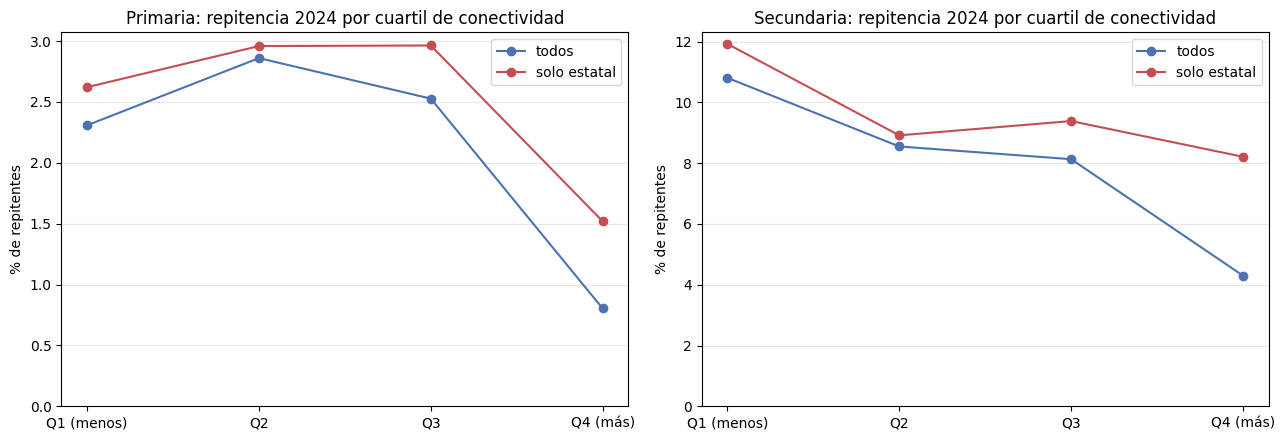

In [182]:
REL = {
    "idx_conectividad_espacios": "Conectividad (índice)",
    "cob_espaciosconconexiónenlasaulas": "Internet en aulas",
    "cob_disponedesalaolaboratoriodeinformáticasi": "Laboratorio de informática",
    "cob_bibliotecadisponedealmenosunasi": "Biblioteca",
    "idx_equipamiento_estab": "Equipamiento (índice)",
    "internet_pago_sobre_total": "Internet pago",
    "log_localizacion": "Tamaño del grupo (log)",
}

estatal = df_limpio.sector.eq("Estatal")
grupos = [("todos", df_limpio), ("solo estatal", df_limpio[estatal])]

corr = pd.DataFrame({
    f"{nivel} | {nombre}": d[list(REL)].corrwith(d[f"tasa_repitencia_{nivel}"], method="spearman")
    for nivel in ["pri", "sec"]
    for nombre, d in grupos
}).rename(index=REL)

print("CORRELACIÓN DE SPEARMAN CON LA TASA DE REPITENCIA 2024\n")
print(corr.round(2).to_string())

print("\nPara comparar:")
for nivel in ["pri", "sec"]:
    rep = df_limpio[f"tasa_repitencia_{nivel}"]
    print(f"  {nivel}: sector privado {df_limpio.es_privado.corr(rep, method='spearman'):+.2f} | "
          f"sobreedad {df_limpio[f'tasa_sobreedad_{nivel}'].corr(rep, method='spearman'):+.2f}")

# Repitencia agregada (repitentes / matrícula) por cuartil de conectividad
cuartil = pd.qcut(df_limpio.idx_conectividad_espacios, 4,
                  labels=["Q1 (menos)", "Q2", "Q3", "Q4 (más)"])

def repitencia_por_cuartil(d, nivel):
    d = d[d[f"tasa_repitencia_{nivel}"].notna()]
    repitentes = d[f"tasa_repitencia_{nivel}"] * d[f"mat_{nivel}"] / 100
    q = cuartil.loc[d.index]
    return (repitentes.groupby(q, observed=True).sum()
            / d[f"mat_{nivel}"].groupby(q, observed=True).sum() * 100)

tabla = pd.DataFrame({f"{nivel} | {nombre}": repitencia_por_cuartil(d, nivel)
                      for nivel in ["pri", "sec"] for nombre, d in grupos})
print("\nREPITENCIA AGREGADA (%) POR CUARTIL DE CONECTIVIDAD\n")
print(tabla.round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for eje, nivel, titulo in zip(ax, ["pri", "sec"], ["Primaria", "Secundaria"]):
    for nombre, color in [("todos", "#4C72B0"), ("solo estatal", "#C44E52")]:
        serie = tabla[f"{nivel} | {nombre}"]
        eje.plot(serie.index.astype(str), serie.values, marker="o", color=color, label=nombre)
    eje.set_title(f"{titulo}: repitencia 2024 por cuartil de conectividad")
    eje.set_ylabel("% de repitentes")
    eje.set_ylim(bottom=0)
    eje.grid(axis="y", alpha=0.3)
    eje.legend()
plt.tight_layout(); plt.show()

**Qué vemos.** Mirando todos los grupos juntos, la infraestructura sí aparece asociada a menos repitencia: los grupos con más conectividad, laboratorios y equipamiento muestran tasas mas bajas (Spearman entre −0,25 y −0,36, y el internet pago llega a −0,44 en secundaria). Por cuartil se ve claro en secundaria: el 25 % de los grupos con menos conectividad tiene 10,8 % de repitencia, y el 25 % con más, 4,3 %.

**Pero buena parte pasa por el sector.** Cuando miramos solo los grupos estatales, casi todas esas correlaciones se achican a valores cercanos a 0 (entre −0,19 y +0,08). El sector privado por sí solo tiene una correlación de −0,46 con la repitencia en primaria y de −0,62 en secundaria: las escuelas privadas tienen mejor infraestructura y menos repitencia a la vez, y eso infla la relación cuando se mezclan todos los grupos. Igual algo queda dentro del estatal: en secundaria, los grupos estatales del cuartil con menos conectividad repiten 11,9 %, contra 8,2 % a 9,4 % en el resto; y en primaria el cuartil con más conectividad repite 1,5 %, contra 2,6 % a 3,0 %.

**La sobreedad pesa mucho más.** Su correlación con la repitencia es +0,86 en primaria y +0,76 en secundaria, muy por encima de cualquier variable de infraestructura. Es esperable, porque repetir genera sobreedad.

**Qué nos dice para el modelo.** La asociacion entre infraestructura y repitencia existe, pero es moderada y está mezclada con el sector, pero no es necesariamente causa-efecto de la repitencia perce. Por eso el modelo tiene que incluir sector y ámbito como controles, y la pregunta que importa no es si la infraestructura se relaciona con la repitencia (ya vemos que sí), sino si agrega información por encima de los antecedentes educativos y del sector, para poder predecir la repitencia del año 2025. Eso es lo que vamos a medir en la evaluación (sección 8).

---
# 7. 💾 Acceso al dataset limpio

*Punto 5 de la entrega.*

El dataset limpio y la lista de features están en el repositorio, en la carpeta `datasets_limpios/`:

* 📄 [`dataset_limpio.csv`](https://github.com/juanjosemfranchi-netizen/educacion_escolaridad/blob/main/datasets_limpios/dataset_limpio.csv): 1216 filas × 86 columnas.
* 📄 [`features_modelo.json`](https://github.com/juanjosemfranchi-netizen/educacion_escolaridad/blob/main/datasets_limpios/features_modelo.json): qué columnas son features de infraestructura, cuáles provinciales, cuáles indicadores, la clave y el umbral de matrícula usado.

Los dos archivos son los que genera la celda de la sección 6.1. La celda de abajo descarga el dataset directo desde GitHub y verifica que coincida con el que se generó en este notebook.

In [183]:
URL = ("https://raw.githubusercontent.com/ju4n1t0x/"
       "repitencia_educacional/main/datasets_limpios/dataset_limpio.csv")

df_repo = pd.read_csv(URL)
print(f"Dataset limpio descargado del repositorio: {df_repo.shape[0]} filas x {df_repo.shape[1]} columnas")

try:
    pd.testing.assert_frame_equal(df_repo, pd.read_csv("dataset_limpio.csv"))
    print("Coincide con el dataset generado en la sección 6.1: sí")
except AssertionError as error:
    print("Coincide con el dataset generado en la sección 6.1: NO")
    print(str(error)[:300])

df_repo.head()

Dataset limpio descargado del repositorio: 1216 filas x 88 columnas
Coincide con el dataset generado en la sección 6.1: sí


,provincia,departamento,sector,ambito,depto_enmascarado,localizacion,cob_electricidadsi,cob_electricidadredpública,cob_electricidadgrupoelectrógeno,cob_electricidadpanelfotovoltaicosolar,cob_electricidadotro,cob_equipamientoestablecimientotelevisor,cob_equipamientoestablecimientosistemamultimediaocañón,cob_equipamientoestablecimientoscanner,cob_equipamientoestablecimientowebcam,cob_equipamientoestablecimientoreproductordecd,cob_equipamientoestablecimientoreproductordedvd,cob_equipamientoestablecimientoimpresora,cob_equipamientoestablecimientoequipoemisorderadioamfm,cob_equipamientoestablecimientoservidorparausoescolar,cob_equipamientoestablecimientoimpresora3d,cob_equipamientoestablecimientoequipodesonido,cob_equipamientoestablecimientopizarrasdigitales,cob_equipamientobibliotecatelevisor,cob_equipamientobibliotecasistemamultimediaocañón,cob_equipamientobibliotecascanner,cob_equipamientobibliotecaequipamientobibliotecawebcam,cob_equipamientobibliotecareproductordecd,cob_equipamientobibliotecareproductordedvd,cob_equipamientobibliotecaimpresora,cob_equipamientobibliotecaequipoemisorderadioamfm,cob_equipamientobibliotecaservidorparausoescolar,cob_internettipodeserviciogratuitoestado,cob_internettipodeserviciogratuitootro,cob_internettipodeserviciopago,cob_internettipodeconexióntelefónica,cob_internettipodeconexiónadsl,cob_internettipodeconexióncablemódem,cob_internettipodeconexiónsatelital,cob_internettipodeconexiónotrotipo,cob_internettipodeconexiónmóvil,cob_espaciosconconexióneneláreadeadministración,cob_espaciosconconexiónenlasaulas,cob_espaciosconconexiónenlabibliotecas,cob_espaciosconconexiónenotroespaciodelestablecimiento,cob_espaciosconconexiónenellaboratorio,cob_cooperadoraconpersoneríajurídica,cob_cooperadorasinpersoneríajurídica,cob_cooperadorano,cob_sistemadegestiónescolarprovistoporelministerio,cob_sistemadegestiónescolardesarrolladoporterceros,cob_sistemadegestiónescolarencargadoporelestablecimiento,cob_sistemadegestiónescolarplanilladecalculo,cob_disponedesalaolaboratoriodeinformáticasi,cob_laboratoriofuncionaesespacioexclusivosi,cob_bibliotecadisponedealmenosunasi,cob_bibliotecafuncionaesespacioexclusivosi,cob_subvenciónestataljardínmaternalsi,cob_subvenciónestataljardíndeinfantessi,cob_subvenciónestatalprimariasi,cob_subvenciónestatalsecundariasi,cob_subvenciónestatalsnusi,log_localizacion,idx_conectividad_espacios,idx_equipamiento_estab,idx_equipamiento_biblio,brecha_admin_aula,lab_exclusivo_sobre_disponible,biblio_exclusiva_sobre_disponible,conexion_fija_sobre_total,internet_pago_sobre_total,sin_red_publica,energia_alternativa,es_privado,es_urbano,mat_pri,mat_sec,prov_estructura_7_5,prov_rep_pri_prev,prov_rep_sec_prev,tasa_repitencia_pri,tasa_repitencia_sec,tasa_sobreedad_pri,tasa_sobreedad_sec,tasa_ssp_pri,tasa_ssp_sec,tasa_repitencia_pri_2025,tasa_repitencia_sec_2025
0,Buenos Aires,25 DE MAYO,Estatal,Rural,0,49,1.0,0.979592,0.061224,0.0,0.0,0.693878,0.714286,0.387755,0.183673,0.306122,0.346939,0.836735,0.285714,0.040816,0.040816,0.632653,0.285714,0.163265,0.183673,0.061224,0.061224,0.081633,0.081633,0.204082,0.061224,0.020408,0.836735,0.122449,0.020408,0.020408,0.040816,0.244898,0.632653,0.122449,0.081633,0.571429,0.897959,0.265306,0.448980,0.061224,0.632653,0.244898,0.122449,0.306122,0.0,0.000000,0.040816,0.204082,0.122449,0.510204,0.285714,0.0,0.000000,0.000000,0.000000,0.0,3.912023,0.448980,0.396259,0.102041,-0.326531,0.600000,0.560000,0.250000,0.020833,0.020408,0.061224,0,0,569.0,665.0,0,2.551492,6.113907,2.811951,4.812030,5.096661,14.285714,0.170648,1.785714,4.753521,3.636364
1,Buenos Aires,25 DE MAYO,Estatal,Urbano,0,43,1.0,1.000000,0.000000,0.0,0.0,0.697674,0.651163,0.534884,0.139535,0.325581,0.302326,0.720930,0.465116,0.116279,0.069767,0.697674,0.372093,0.325581,0.255814,0.046512,0.000000,0.023256,0.069767,0.046512,0.000000,0.046512,0.790698,0.023256,0.186047,0.046512,0.046512,0.511628,0.348837,0.116279,0.046512,0.813953,0.813953,0.488372,0.488372,0.186047,0.534884,0.139535,0.325581,0.348837,0.0,0.000

---
# 8. 🤖 Modelo de Aprendizaje Automático



*Punto 6 de la entrega.*

**Tipo de problema.** Lo que queremos predecir, la tasa de repitencia 2025 de cada grupo, es un número continuo entre 0 y 100, y vamos a tener el valor real para cada grupo. Es entonces un problema de **aprendizaje supervisado de regresión**.

**Modelo elegido: regresión lineal con regularización L2 (Ridge).** La decisión no se apoya solo en que las medias difieran (1,99 % contra 6,95 %), sino en que el EDA muestra diferencias estructurales entre niveles:

En la seccion 4.4 del EDA podemos ver que la forma de distribución en primaria es fuertemente asimétrica, su mediana (0,89%) es menos de la mitad de su media (1.99%), mientras que en secundaria es mucho más simétrica (mediana 6,39% y media 6,95%) y con una cola más larga (máximos 48,21% contra 21,43%). Son distribuciones de distinta forma.

Además el vínculo entre ámbito y repitencia se invierte, en primaria la repitencia estatal más alta es la rural (2,71 % contra 2,29% de la urbana), y en secundaria es la urbana (9.03% contra 7,93%), y la asociación entre sector y repitencia es más fuerte en secundaria (Spearman -0,62) que en primaria (-0,46), seccion 6.2 del EDA.

Por otro lado, si tenemos en cuenta la composición de los grupos (sección 5.6 del EDA), vemos que cada nivel se construye con grados distintos según la estructura provincial (6-6 y 7-5), así que "primaria" y "secundaria" agrupan poblaciones escolares de composición diferente en cada provincia. 

Todo esto sugiere que las diferencias entre niveles no son aditivas: entrenar un único modelo en el que el nivel opere solo como corrimiento del intercepto no podría representarlas, y para hacerlo necesitaría interacciones de nivel con prácticamente todas las vaiables, que en el límite reproduce dos modelos separados compartiendo una misma pensalización.


**Por qué una regresión lineal.** Queremos ver cómo se relaciona la repitencia con la infraestructura, y la regresión lineal es el modelo más fácil de interpretar: si las variables se encuentran fuertemente correlacionadas. A los coeficientes de Ridge los leeremos como la direccion que existe de la asociacion colectiva del bloque (que el set de infraestructura se asocice de forma constitente a menos repitencia), y que se vea comparando el mismo modelo con y sin el bloque de infraesctura -no los coeficientes sueltos- que es donde realmente responderemos a nuestra pregunta de investigacion.

**Por qué Ridge y no una regresión común.** Muchas variables están correlacionadas entre sí: los índices se construyen a partir de las mismas coberturas (por ejemplo `idx_conectividad_espacios` y las cinco coberturas de conexión), y las tres categorías de cooperadora van juntas. Encima, aunque haya unas 1200 filas, al ponderar por matrícula el tamaño de muestra efectivo es de unas 200 observaciones (228 en primaria y 204 en secundaria), porque unos pocos grupos muy grandes concentran gran parte de los alumnos. En esas condiciones una regresión común da coeficientes inestables, que cambian mucho con pequeñas variaciones en los datos. Ridge agrega una penalización que achica los coeficientes y los estabiliza. Como esa penalización depende de la escala de cada variable, primero las estandarizamos, y el nivel de penalización (alpha) lo elegimos por validación cruzada.

**Qué cambió respecto de la primera entrega.** En la primera entrega habíamos propuesto Random Forest o XGBoost, complementados con un clustering para armar perfiles institucionales, y dos variables objetivo: repitencia y abandono interanual. Después del EDA ajustamos tres cosas:
- **Ridge en lugar de Random Forest o XGBoost:** con unas 200 observaciones efectivas, un ensamble de árboles con 72 variables corre mucho riesgo de sobreajustar. Además, lo que queremos es ver para qué lado se relaciona cada variable de infraestructura con la repitencia, y eso los coeficientes de una regresión lo muestran directamente.
- **Sin clustering:** la idea era usar los perfiles como variable extra y comparar el modelo con y sin ellos. La descripción de los grupos ya la cubrimos con el EDA (sector, ámbito, coberturas e índices), y la comparación que nos interesa ahora es otra: el mismo modelo con y sin el bloque de infraestructura.
- **Solo la repitencia como objetivo, por ahora:** la repitencia la calculamos directo de la Matrícula y ya validamos el cálculo contra la cifra oficial (5.7). El abandono interanual se calcula combinando matrícula, repitentes y egresados de dos años seguidos, y a nivel grupo eso queda muy afectado por los alumnos que cambian de departamento o de sector entre un año y otro (por ejemplo, al pasar de primaria a secundaria) y por los grupos que cambian entre años, como los enmascarados. Lo dejamos como posible extensión, y los salidos sin pase entran solo como predictor.

**Cómo lo vamos a entrenar.**
- **Predictores (todos de 2024):** infraestructura y sus índices, sector y ámbito, tamaño del grupo, repitencia, sobreedad y salidos sin pase de 2024, y el contexto provincial.
- **Objetivo (2025):** tasa de repitencia 2025 = repitentes 2025 / matrícula 2025 × 100, calculada con el mismo procedimiento de 5.6. Se usa solo como objetivo, nunca como predictor, así no hay fuga de información.
- **Ponderación por matrícula:** una tasa calculada sobre 40 alumnos es mucho más ruidosa que una sobre 40.000, así que cada grupo pesa según su cantidad de alumnos.
- **Validación dejando provincias enteras afuera** (validación cruzada agrupada por provincia): la provincia explica buena parte de la repitencia y de la infraestructura. Si separábamos al azar, el modelo vería grupos de la misma provincia en entrenamiento y en prueba, y el desempeño parecería mejor de lo que es.

**Qué vamos a evaluar.**
1. **Si el modelo anticipa la repitencia 2025:** error medio (MAE y RMSE ponderados por matrícula) y R² en las provincias que el modelo no vio, mirando también los resultados por sector y ámbito para comprobar que no funcione solo para los grupos estatales urbanos.
2. **Si la infraestructura aporta:** entrenamos el mismo modelo Ridge con dos conjuntos de variables, solo antecedentes educativos 2024 y antecedentes más infraestructura 2024. Si el error baja al agregar la infraestructura, hay un patrón de relación entre infraestructura y repitencia que el modelo puede aprovechar. Después miramos qué variables de infraestructura pesan más y con qué signo, y si estos se mantienen estables y apuntan a una direccion comun (ej, asocacion de mayor conectividad con menor repitencia).

El resultado va a mostrar asociación y no causalidad: si la conectividad aparece relacionada con menos repitencia, no quiere decir que por sí sola la reduzca. Como vimos en 6.2, parte de esa relación pasa por el sector.

# Entrenamiento y evaluación del modelo

## Creación del pileine

In [184]:
warnings.filterwarnings("ignore")

try:
    df = pd.read_csv("dataset_limpio.csv")      # bajado en la sección 7
except FileNotFoundError:
    df = df_limpio.copy()                        # si 6.1 corre en la misma sesión

FJ = json.load(open("features_modelo.json"))
IDS        = FJ["identificacion"]
FEAT_INFRA = FJ["features_infraestructura"]
FEAT_PROV  = FJ["features_provinciales"]
FEAT_TASAS = FJ["indicadores_por_grupo"]
ANTES  = FEAT_PROV + FEAT_TASAS     # antecedentes educativos + contexto provincial
X_FULL = FEAT_INFRA + ANTES         # variables del modelo completo
PESOS  = {"pri": "mat_pri", "sec": "mat_sec"}

COLS_NUM = X_FULL + list(PESOS.values()) + [f"tasa_repitencia_{n}_2025" for n in ("pri", "sec")]
df[COLS_NUM] = df[COLS_NUM].apply(pd.to_numeric, errors="coerce")

print(f"filas: {len(df)} | features: {len(X_FULL)} "
      f"(infra {len(FEAT_INFRA)} + antecedentes {len(ANTES)})")

filas: 1216 | features: 78 (infra 69 + antecedentes 9)


In [185]:
warnings.filterwarnings("ignore")

ALPHAS = (0.1, 1, 10, 100, 1_000, 10_000, 100_000)   # techo alto: el grid chico se satura
K_OUT, K_IN = 5, 4

def armar_ridge(alpha=1.0):
    return Pipeline([("sc", StandardScaler()), ("ridge", Ridge(alpha=alpha))])

def base_nivel(nivel, xcols):
    t = f"tasa_repitencia_{nivel}_2025"
    d = df[IDS + xcols + [PESOS[nivel], t]].dropna(subset=[t, PESOS[nivel]] + xcols).copy()
    return d[d[PESOS[nivel]] > 0].reset_index(drop=True), t

print("Pipeline demo:", armar_ridge())
def base_nivel(nivel, xcols):
    t = f"tasa_repitencia_{nivel}_2025"
    d = df[IDS + xcols + [PESOS[nivel], t]].dropna(subset=[t, PESOS[nivel]] + xcols).copy()

    return d[d[PESOS[nivel]] > 0].reset_index(drop=True), t

Pipeline demo: Pipeline(steps=[('sc', StandardScaler()), ('ridge', Ridge())])


## Entrenamiento

In [189]:
warnings.filterwarnings("ignore")

ALPHAS = np.logspace(-1, 7, 9)
K_OUT, K_IN = 5, 4

def base(nivel):
    ycol, wcol = f"tasa_repitencia_{nivel}_2025", PESOS[nivel]
    d = df[IDS + X_FULL + [wcol, ycol]].dropna().copy()
    return d[d[wcol] > 0].reset_index(drop=True), ycol

def entrenar(d, cols, ycol, wcol):
    X, y = d[cols].to_numpy(float), d[ycol].to_numpy(float)
    w, g = d[wcol].to_numpy(float), d["provincia"].to_numpy()
    pred, alphas, coefs = np.full(len(y), np.nan), [], []

    for tr, te in GroupKFold(K_OUT).split(X, y, g):
        mejor, err_mejor = None, np.inf
        for a in ALPHAS:
            errs = []
            for i, j in GroupKFold(K_IN).split(X[tr], y[tr], g[tr]):
                m = armar_ridge(a)
                m.fit(X[tr][i], y[tr][i], ridge__sample_weight=w[tr][i])
                errs.append(np.average((y[tr][j] - m.predict(X[tr][j]))**2, weights=w[tr][j]))
            if np.mean(errs) < err_mejor:
                mejor, err_mejor = a, np.mean(errs)

        m = armar_ridge(mejor)
        m.fit(X[tr], y[tr], ridge__sample_weight=w[tr])
        pred[te] = m.predict(X[te])
        alphas.append(mejor)
        coefs.append(m["ridge"].coef_)

    return dict(y=y, pred=pred, w=w, alphas=alphas, coefs=np.array(coefs),
                cols=list(cols), sector=d.sector.to_numpy(), ambito=d.ambito.to_numpy())

RES = {}
for nivel in ("pri", "sec"):
    d, ycol = base(nivel)
    for nombre, cols in [("completo", X_FULL), ("basico", ANTES)]:
        RES[(nivel, nombre)] = entrenar(d, cols, ycol, PESOS[nivel])

# Control pooled: nivel + interacciones nivel × variables
bloques = []
for nivel in ("pri", "sec"):
    d, ycol = base(nivel)
    b = d[["provincia", "sector", "ambito"] + X_FULL + [PESOS[nivel], ycol]].copy()
    b["nivel_sec"] = int(nivel == "sec")
    bloques.append(b.rename(columns={PESOS[nivel]: "w", ycol: "y"}))

pool = pd.concat(bloques, ignore_index=True)
sec = pool.nivel_sec.to_numpy()
Z = pool[X_FULL].astype(float).copy()
for c in X_FULL:
    Z[f"secx_{c}"] = Z[c].to_numpy() * sec
Z["nivel_sec"] = sec

aux = Z.assign(
    provincia=pool.provincia, sector=pool.sector, ambito=pool.ambito,
    y=pool.y, w=pool.w
)
RES["pooled"] = entrenar(aux, list(Z.columns), "y", "w")
RES["niveles_pool"] = np.where(aux["nivel_sec"].to_numpy() == 1, "sec", "pri")

print("Alphas:", {k: v["alphas"] for k, v in RES.items() if isinstance(v, dict)})

Alphas: {('pri', 'completo'): [np.float64(10000.0), np.float64(100000.0), np.float64(100000.0), np.float64(100000.0), np.float64(100000.0)], ('pri', 'basico'): [np.float64(0.1), np.float64(10000.0), np.float64(100000.0), np.float64(10000.0), np.float64(10000.0)], ('sec', 'completo'): [np.float64(100000.0), np.float64(100000.0), np.float64(10000.0), np.float64(10000.0), np.float64(10000.0)], ('sec', 'basico'): [np.float64(0.1), np.float64(1000000.0), np.float64(0.1), np.float64(100000.0), np.float64(0.1)], 'pooled': [np.float64(100000.0), np.float64(100000.0), np.float64(10000.0), np.float64(10000.0), np.float64(10000.0)]}


## Evaluacion

In [193]:
def metricas(y, pred, w):
    y, pred, w = np.asarray(y), np.asarray(pred), np.asarray(w)
    e = y - pred
    return {
        "MAE pond.": np.average(np.abs(e), weights=w),
        "RMSE pond.": np.sqrt(np.average(e**2, weights=w)),
        "R2": r2_score(y, pred),
        "R2 pond.": r2_score(y, pred, sample_weight=w)
    }

# Nivel de cada fila del modelo pooled; admite las dos versiones del nombre.
niveles_pool = RES.get("niveles_pool", RES.get("nivel_pool"))
if niveles_pool is None:
    raise KeyError("Falta la clave de niveles pooled. Ejecutá primero la celda 8.3.")

filas = []

# Modelos separados
for nivel in ("pri", "sec"):
    for tipo in ("completo", "basico"):
        resultado = RES[(nivel, tipo)]
        filas.append({
            "modelo": f"{nivel} — {tipo}",
            "n": len(resultado["y"]),
            **metricas(resultado["y"], resultado["pred"], resultado["w"])
        })

# Modelo pooled: total y desglosado por nivel
rp = RES["pooled"]
filas.append({
    "modelo": "pooled — total",
    "n": len(rp["y"]),
    **metricas(rp["y"], rp["pred"], rp["w"])
})

for nivel in ("pri", "sec"):
    sel = niveles_pool == nivel
    filas.append({
        "modelo": f"pooled — {nivel}",
        "n": int(sel.sum()),
        **metricas(rp["y"][sel], rp["pred"][sel], rp["w"][sel])
    })

print("MÉTRICAS OUT-OF-FOLD")
print(pd.DataFrame(filas).to_string(
    index=False, float_format=lambda x: f"{x:.3f}"
))

# Cambio al agregar infraestructura; completo y básico usan la misma muestra.
print("\nCAMBIO AL AGREGAR INFRAESTRUCTURA")
for nivel in ("pri", "sec"):
    basico = RES[(nivel, "basico")]
    completo = RES[(nivel, "completo")]
    mb = metricas(basico["y"], basico["pred"], basico["w"])
    mc = metricas(completo["y"], completo["pred"], completo["w"])

    print(
        f"{nivel}: MAE {mb['MAE pond.']:.2f} → {mc['MAE pond.']:.2f} | "
        f"RMSE {mb['RMSE pond.']:.2f} → {mc['RMSE pond.']:.2f} | "
        f"R² pond. {mb['R2 pond.']:.3f} → {mc['R2 pond.']:.3f}"
    )

# Desglose por sector y ámbito del modelo completo.
print("\nMODELO COMPLETO: DESGLOSE POR SECTOR Y ÁMBITO")
for nivel in ("pri", "sec"):
    resultado = RES[(nivel, "completo")]
    for columna in ("sector", "ambito"):
        for valor in pd.unique(resultado[columna]):
            sel = resultado[columna] == valor
            m = metricas(
                resultado["y"][sel],
                resultado["pred"][sel],
                resultado["w"][sel]
            )
            print(
                f"{nivel} | {columna}={valor} | n={sel.sum()} | "
                f"MAE pond.={m['MAE pond.']:.2f} | "
                f"RMSE pond.={m['RMSE pond.']:.2f} | "
                f"R²={m['R2']:.3f} | R² pond.={m['R2 pond.']:.3f}"
            )

# Estabilidad de signos: diagnóstico, no ranking de importancia.
print("\nESTABILIDAD DE SIGNOS — INFRAESTRUCTURA")
for nivel in ("pri", "sec"):
    resultado = RES[(nivel, "completo")]
    signos = np.sign(resultado["coefs"])
    estables = (signos > 0).all(axis=0) | (signos < 0).all(axis=0)
    es_infra = np.isin(resultado["cols"], FEAT_INFRA)
    print(f"{nivel}: {estables[es_infra].mean():.0%} de signos estables")



MÉTRICAS OUT-OF-FOLD
        modelo    n  MAE pond.  RMSE pond.    R2  R2 pond.
pri — completo 1137      0.623       0.821 0.770     0.858
  pri — basico 1137      0.503       0.732 0.787     0.887
sec — completo 1135      2.980       3.742 0.475     0.534
  sec — basico 1135      2.889       3.737 0.389     0.535
pooled — total 2272      1.716       2.641 0.628     0.657
  pooled — pri 1137      0.621       0.842 0.760     0.850
  pooled — sec 1135      3.013       3.794 0.473     0.521

CAMBIO AL AGREGAR INFRAESTRUCTURA
pri: MAE 0.50 → 0.62 | RMSE 0.73 → 0.82 | R² pond. 0.887 → 0.858
sec: MAE 2.89 → 2.98 | RMSE 3.74 → 3.74 | R² pond. 0.535 → 0.534

MODELO COMPLETO: DESGLOSE POR SECTOR Y ÁMBITO
pri | sector=Estatal | n=853 | MAE pond.=0.68 | RMSE pond.=0.89 | R²=0.761 | R² pond.=0.842
pri | sector=Privado | n=284 | MAE pond.=0.48 | RMSE pond.=0.60 | R²=0.586 | R² pond.=-0.322
pri | ambito=Rural | n=444 | MAE pond.=0.80 | RMSE pond.=1.14 | R²=0.760 | R² pond.=0.846
pri | ambito=Urbano 

In [194]:
# ---- lectura de coeficientes: estabilidad de signos (NO es ranking individual) ----
print("\nLECTURA DE COEFICIENTES — estabilidad de signos del bloque de infraestructura")
for nivel in ("pri", "sec"):
    r = RES[(nivel, "completo")]
    med = np.median(r["coefs"], axis=0)
    estable = (r["coefs"] > 0).all(0) | (r["coefs"] < 0).all(0)
    t = (pd.DataFrame({"variable": r["cols"],
                       "signo (mediana entre folds)": med,
                       "signo estable en todos los folds": estable})
         [lambda d2: d2.variable.isin(FEAT_INFRA)]
         .sort_values("signo (mediana entre folds)", key=abs, ascending=False))
    print(f"\n— modelo {nivel} —")
    print(t.round(3).to_string(index=False))
    print(f"→ variables del bloque con signo estable: {t['signo estable en todos los folds'].mean():.0%}")


LECTURA DE COEFICIENTES — estabilidad de signos del bloque de infraestructura

— modelo pri —
                                                variable  signo (mediana entre folds)  signo estable en todos los folds
                               internet_pago_sobre_total                        0.140                              True
                       biblio_exclusiva_sobre_disponible                        0.120                              True
                                              es_privado                       -0.113                              True
                                     energia_alternativa                        0.106                              True
                          lab_exclusivo_sobre_disponible                        0.105                             False
           cob_equipamientoestablecimientoequipodesonido                       -0.104                              True
                cob_equipamientoestablecimientoimpresora         

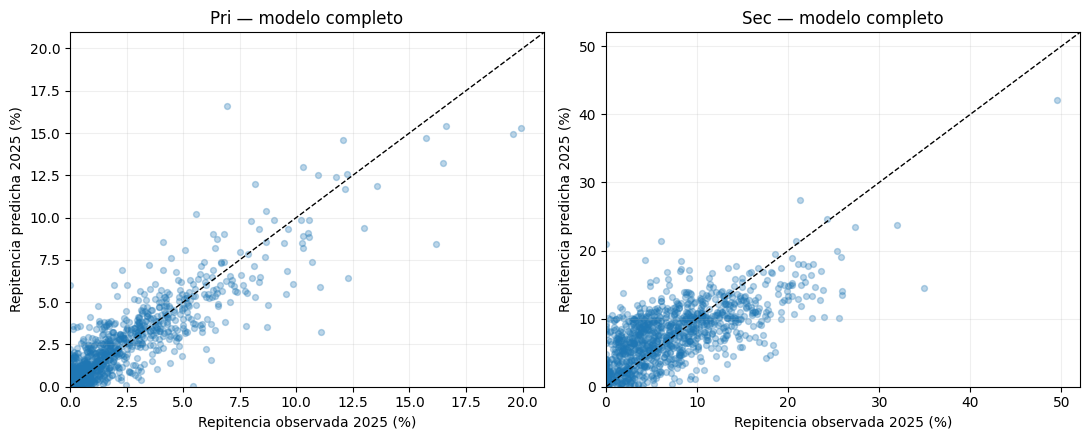

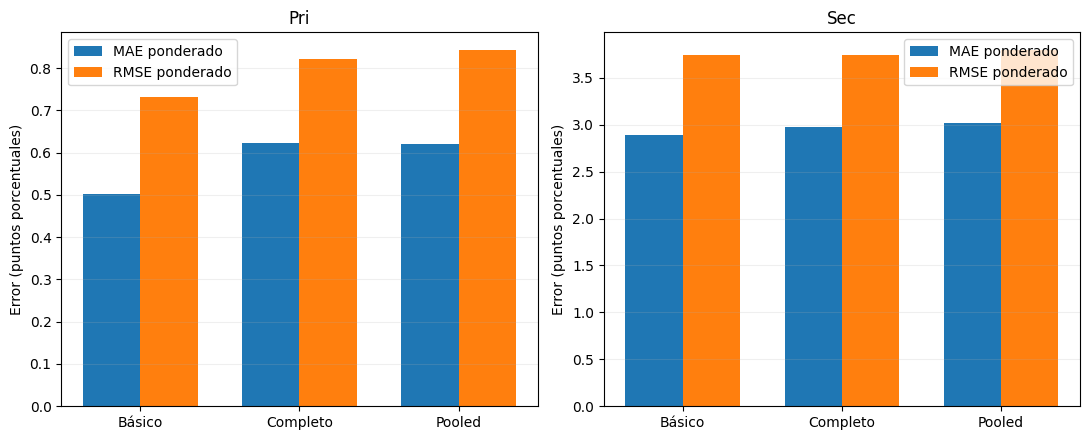

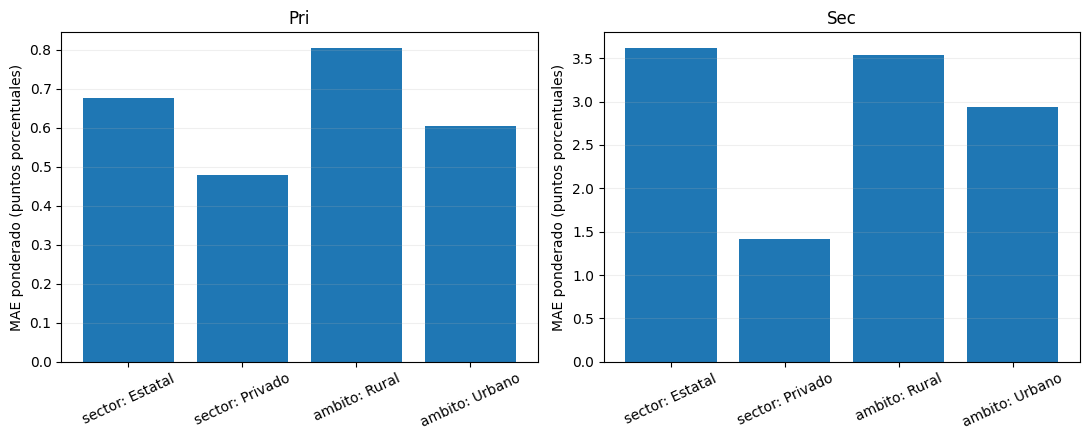

In [195]:
def errores(y, pred, w):
    e = np.asarray(y) - np.asarray(pred)
    w = np.asarray(w)
    return (
        np.average(np.abs(e), weights=w),
        np.sqrt(np.average(e**2, weights=w))
    )

# 1. Valores observados vs. predichos (predicciones out-of-fold)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, nivel in zip(axes, ("pri", "sec")):
    r = RES[(nivel, "completo")]
    y, pred = r["y"], r["pred"]
    limite = max(y.max(), pred.max()) * 1.05

    ax.scatter(y, pred, alpha=0.3, s=18)
    ax.plot([0, limite], [0, limite], "--", color="black", linewidth=1)
    ax.set(xlim=(0, limite), ylim=(0, limite),
           xlabel="Repitencia observada 2025 (%)",
           ylabel="Repitencia predicha 2025 (%)",
           title=f"{nivel.capitalize()} — modelo completo")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


# 2. MAE y RMSE ponderados: básico, completo y pooled, por nivel
nivel_pool = RES.get("niveles_pool", RES.get("nivel_pool"))
if nivel_pool is None:
    raise KeyError("No encuentro los niveles del modelo pooled; ejecutá primero la celda 8.3.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
configuraciones = ["Básico", "Completo", "Pooled"]

for ax, nivel in zip(axes, ("pri", "sec")):
    mae, rmse = [], []

    for config in configuraciones:
        if config == "Pooled":
            r = RES["pooled"]
            sel = nivel_pool == nivel
            m1, m2 = errores(r["y"][sel], r["pred"][sel], r["w"][sel])
        else:
            tipo = "basico" if config == "Básico" else "completo"
            r = RES[(nivel, tipo)]
            m1, m2 = errores(r["y"], r["pred"], r["w"])

        mae.append(m1)
        rmse.append(m2)

    x = np.arange(len(configuraciones))
    ancho = 0.36
    ax.bar(x - ancho/2, mae, ancho, label="MAE ponderado")
    ax.bar(x + ancho/2, rmse, ancho, label="RMSE ponderado")
    ax.set_xticks(x, configuraciones)
    ax.set_ylabel("Error (puntos porcentuales)")
    ax.set_title(nivel.capitalize())
    ax.grid(axis="y", alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()


# 3. MAE ponderado del modelo completo por sector y ámbito
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, nivel in zip(axes, ("pri", "sec")):
    r = RES[(nivel, "completo")]
    etiquetas, valores = [], []

    for columna, categorias in [
        ("sector", ["Estatal", "Privado"]),
        ("ambito", ["Rural", "Urbano"])
    ]:
        for categoria in categorias:
            sel = r[columna] == categoria
            mae, _ = errores(r["y"][sel], r["pred"][sel], r["w"][sel])
            etiquetas.append(f"{columna}: {categoria}")
            valores.append(mae)

    ax.bar(etiquetas, valores)
    ax.set_ylabel("MAE ponderado (puntos porcentuales)")
    ax.set_title(nivel.capitalize())
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()